# Assessment 2: Machine Learning and Real Time Streaming
Student ID: 33602190  
Unit: ITO5202  
Year: 2026

This assessment uses the IBM AML HI-Small dataset from Assessment 1. Part A compares classification models and saves the selected model. Part B uses that model to predict transactions sent through Kafka.

## 0. Environment and configuration
Start Kafka with `bash scripts/start_kafka.sh` in a separate terminal. Open the notebook with `bash scripts/start_notebook.sh`, select Python (assessment2-aml) and run the cells in order.

File paths start from the project folder. The split uses seed 42, and Spark uses UTC for timestamps. Spark downloads the Kafka connector on its first run.

In [1]:
from pathlib import Path
import os
import sys
import platform
from importlib.metadata import version

PROJECT_ROOT = Path.cwd().resolve()
JAVA_HOME = PROJECT_ROOT / ".runtime/jdk-17.0.20.1+1/Contents/Home"
os.environ["JAVA_HOME"] = str(JAVA_HOME)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_SUBMIT_ARGS"] = "--driver-memory 4g pyspark-shell"

SEED = 42
DATA_DIR = PROJECT_ROOT / "data"
MODEL_PATH = PROJECT_ROOT / "models/a2_model"
STREAM_PATH = DATA_DIR / "stream_data.parquet"
DEVELOPMENT_PATH = DATA_DIR / "development_data.parquet"
KAFKA_BOOTSTRAP_SERVERS = "127.0.0.1:9092"
KAFKA_TOPIC = "aml-transactions"
RUN_KAFKA_SMOKE_TEST = True
SPARK_KAFKA_PACKAGE = "org.apache.spark:spark-sql-kafka-0-10_2.12:3.5.7"

print("Python:", platform.python_version())
print("PySpark:", version("pyspark"))
print("Kafka Python client:", version("kafka-python3"))
print("Python executable:", sys.executable)
print("XGBoost:", version("xgboost"))

Python: 3.11.17
PySpark: 3.5.7
Kafka Python client: 3.0.0
Python executable: /Users/a208109/Desktop/assessment2-aml/.venv/bin/python
XGBoost: 3.0.5


### Start Spark
Spark runs with four local threads and 4 GB of driver memory. The Kafka connector matches Spark 3.5.7 and Scala 2.12. The Kafka server uses its own Scala 2.13 build.

In [2]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .master("local[4]")
         .appName("Assessment2-AML")
         .config("spark.jars.packages", SPARK_KAFKA_PACKAGE)
         .config("spark.jars.ivy", str(PROJECT_ROOT / ".runtime/ivy"))
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
jvm = spark.sparkContext._jvm
java_version = jvm.java.lang.System.getProperty("java.version")
scala_version = jvm.scala.util.Properties.versionNumberString()
print(f"Spark {spark.version}, Java {java_version}, Scala {scala_version}")

:: loading settings :: url = jar:file:/Users/a208109/Desktop/assessment2-aml/.venv/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /Users/a208109/Desktop/assessment2-aml/.runtime/ivy/cache
The jars for the packages stored in: /Users/a208109/Desktop/assessment2-aml/.runtime/ivy/jars
org.apache.spark#spark-sql-kafka-0-10_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-54becb2d-bc7c-4dd7-891a-4658baaf576c;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.12;3.5.7 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.12;3.5.7 in central
	found org.apache.kafka#kafka-clients;3.4.1 in central
	found org.lz4#lz4-java;1.8.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.5 in central
	found org.slf4j#slf4j-api;2.0.7 in central
	found org.apache.hadoop#hadoop-client-runtime;3.3.4 in central
	found org.apache.hadoop#hadoop-client-api;3.3.4 in central
	found commons-logging#commons-logging;1.1.3 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.apache.commons#commons-pool2;2.11.1 in cent

26/10/10 22:17:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 3.5.7, Java 17.0.20.1, Scala 2.12.18


### Check Kafka and Structured Streaming
This check sends a sample JSON array through Kafka and reads it with Python and Spark. It removes the temporary topic when finished. Kafka needs to be running at `127.0.0.1:9092`.

Set `RUN_KAFKA_SMOKE_TEST = False` to skip this check when working offline.

In [3]:
from scripts.check_kafka import check_kafka

if RUN_KAFKA_SMOKE_TEST:
    setup_result = check_kafka(spark, PROJECT_ROOT, KAFKA_BOOTSTRAP_SERVERS)
    print(setup_result)
else:
    print("SKIPPED: Kafka connectivity check")

PASS: Python producer and consumer exchanged one JSON array.


PASS: Spark Structured Streaming parsed the same record using the Kafka connector.
{'python_round_trip': 'PASS', 'spark_streaming': 'PASS', 'records': 1}


## Part A: Machine learning
### A1. Load and validate the dataset

The task is binary classification using `is_laundering` as the target. A value of 1 means simulated laundering, and 0 means no laundering. The aim is to identify transactions that may need review.

The data comes from the HI-Small subset of [IBM Transactions for Anti-Money Laundering (AML)](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml), which was approved for Assessment 1. Each row in the transaction file represents a transaction. The account file provides bank and account details.

#### Check the input files
The checksums are compared with those recorded in Assessment 1. The CSV headers are also checked before the columns are renamed.

In [4]:
import csv
import hashlib
import pandas as pd
from IPython.display import display

expected_hashes = {
    "HI-Small_Trans.csv":
        "b19d39f515523373f991b689c07e11e7b0b95c17a2c27a87d91584ae16c5b040",
    "HI-Small_accounts.csv":
        "786808526e33cfc441212dd6fccda7edfc24172149bed59c6ef59b186836b014",
}
expected_headers = {
    "HI-Small_Trans.csv": [
        "Timestamp", "From Bank", "Account", "To Bank", "Account",
        "Amount Received", "Receiving Currency", "Amount Paid",
        "Payment Currency", "Payment Format", "Is Laundering",
    ],
    "HI-Small_accounts.csv": [
        "Bank Name", "Bank ID", "Account Number", "Entity ID", "Entity Name",
    ],
}
file_checks = []
source_hashes = {}
for filename, expected_hash in expected_hashes.items():
    path = DATA_DIR / filename
    with path.open("rb") as file:
        actual_hash = hashlib.file_digest(file, "sha256").hexdigest()
    with path.open(newline="", encoding="utf-8-sig") as file:
        header = next(csv.reader(file))
    source_hashes[filename] = actual_hash
    file_checks.append((filename, actual_hash == expected_hash, header == expected_headers[filename]))
display(pd.DataFrame(file_checks, columns=["File", "Matches Assessment 1 checksum", "Header matches"]))

,File,Matches Assessment 1 checksum,Header matches
0,HI-Small_Trans.csv,True,True
1,HI-Small_accounts.csv,True,True


#### Load the data
Account numbers are kept as strings. The two columns named `Account` are renamed `sender_account` and `receiver_account`. Bank IDs are numeric in both files. Loading stops if a record cannot be parsed. No rows are removed.

The timestamp format is `yyyy/MM/dd HH:mm`. The source does not specify a timezone, so UTC is used consistently without changing the recorded clock times. Amounts use double precision and are interpreted in their own currencies.

In [5]:
from pyspark import StorageLevel
from pyspark.sql.types import (
    StructType, StructField, TimestampType, LongType,
    StringType, DoubleType, IntegerType,
)

transaction_schema = StructType([
    StructField("timestamp", TimestampType(), True),
    StructField("from_bank", LongType(), True),
    StructField("sender_account", StringType(), True),
    StructField("to_bank", LongType(), True),
    StructField("receiver_account", StringType(), True),
    StructField("amount_received", DoubleType(), True),
    StructField("receiving_currency", StringType(), True),
    StructField("amount_paid", DoubleType(), True),
    StructField("payment_currency", StringType(), True),
    StructField("payment_format", StringType(), True),
    StructField("is_laundering", IntegerType(), True),
])
account_schema = StructType([
    StructField("bank_name", StringType(), True),
    StructField("bank_id", LongType(), True),
    StructField("account_number", StringType(), True),
    StructField("entity_id", StringType(), True),
    StructField("entity_name", StringType(), True),
])

transactions = (
    spark.read.schema(transaction_schema)
    .option("header", True).option("enforceSchema", True)
    .option("timestampFormat", "yyyy/MM/dd HH:mm")
    .option("mode", "FAILFAST")
    .csv(str(DATA_DIR / "HI-Small_Trans.csv"))
    .persist(StorageLevel.MEMORY_AND_DISK)
)
accounts = (
    spark.read.schema(account_schema)
    .option("header", True).option("enforceSchema", True)
    .option("mode", "FAILFAST")
    .csv(str(DATA_DIR / "HI-Small_accounts.csv"))
    .persist(StorageLevel.MEMORY_AND_DISK)
)
transaction_count = transactions.count()
account_count = accounts.count()
display(pd.DataFrame([
    ("Transactions", f"{transaction_count:,}", len(transactions.columns)),
    ("Accounts", f"{account_count:,}", len(accounts.columns)),
], columns=["Dataset", "Rows", "Columns"]))
display(pd.DataFrame([
    (name, field.name, field.dataType.simpleString())
    for name, dataframe in [("Transactions", transactions), ("Accounts", accounts)]
    for field in dataframe.schema.fields
], columns=["Dataset", "Field", "Spark type"]))

,Dataset,Rows,Columns
0,Transactions,"5,078,345",11
1,Accounts,"518,581",5


,Dataset,Field,Spark type
0,Transactions,timestamp,timestamp
1,Transactions,from_bank,bigint
2,Transactions,sender_account,string
3,Transactions,to_bank,bigint
4,Transactions,receiver_account,string
5,Transactions,amount_received,double
6,Transactions,receiving_currency,string
7,Transactions,amount_paid,double
8,Transactions,payment_currency,string
9,Transactions,payment_format,string


#### Check missing and invalid values
Check each column for nulls and text columns for blanks. Amounts must be finite and at least zero. Labels must be 0 or 1. The timestamp check also identifies missing dates after parsing.

In [6]:
missing_results = []
for name, dataframe in [("Transactions", transactions), ("Accounts", accounts)]:
    expressions = []
    for field in dataframe.schema.fields:
        missing = F.col(field.name).isNull()
        if isinstance(field.dataType, StringType):
            missing = missing | (F.trim(F.col(field.name)) == "")
        expressions.append(
            F.sum(F.when(missing, 1).otherwise(0)).alias(field.name)
        )
    counts = dataframe.agg(*expressions).first().asDict()
    missing_results.extend((name, column, count) for column, count in counts.items())
display(pd.DataFrame(missing_results, columns=["Dataset", "Field", "Null or blank rows"]))

invalid_checks = {
    "invalid_labels": (
        F.col("is_laundering").isNull() | ~F.col("is_laundering").isin(0, 1)
    ),
}
for column in ["amount_paid", "amount_received"]:
    invalid_checks[f"invalid_{column}"] = (
        F.col(column).isNull() | F.isnan(column)
        | (F.abs(F.col(column)) == float("inf")) | (F.col(column) < 0)
    )
invalid_results = transactions.agg(*[
    F.sum(F.when(condition, 1).otherwise(0)).alias(name)
    for name, condition in invalid_checks.items()
]).first().asDict()
display(pd.DataFrame(invalid_results.items(), columns=["Check", "Invalid rows"]))

,Dataset,Field,Null or blank rows
0,Transactions,timestamp,0
1,Transactions,from_bank,0
2,Transactions,sender_account,0
3,Transactions,to_bank,0
4,Transactions,receiver_account,0
5,Transactions,amount_received,0
6,Transactions,receiving_currency,0
7,Transactions,amount_paid,0
8,Transactions,payment_currency,0
9,Transactions,payment_format,0


,Check,Invalid rows
0,invalid_labels,0
1,invalid_amount_paid,0
2,invalid_amount_received,0


#### Check dates and labels
Compare the date range and label counts with Assessment 1. These checks cover the original files. Model development uses the separate development data created in A2.

In [7]:
# Keep the displayed dates in UTC.
coverage_display = transactions.agg(
    F.date_format(F.min("timestamp"), "yyyy-MM-dd HH:mm").alias("first"),
    F.date_format(F.max("timestamp"), "yyyy-MM-dd HH:mm").alias("last"),
).first()
display(pd.DataFrame([
    (coverage_display["first"], coverage_display["last"],
     spark.conf.get("spark.sql.session.timeZone")),
], columns=["First transaction", "Last transaction", "Processing timezone"]))
label_counts = transactions.groupBy("is_laundering").count().orderBy(
    "is_laundering"
).collect()
display(pd.DataFrame([
    (row.is_laundering, f"{row['count']:,}",
     f"{100 * row['count'] / transaction_count:.4f}%")
    for row in label_counts
], columns=["Label", "Transactions", "Percent"]))

,First transaction,Last transaction,Processing timezone
0,2022-09-01 00:00,2022-09-18 16:18,UTC


,Label,Transactions,Percent
0,0,"5,073,168",99.8981%
1,1,"5,177",0.1019%


#### Check account matches
An account is identified by its bank ID and account number together. Check that this combination is unique, then count transactions whose sender or receiver has no matching account. This helps prevent joins from duplicating or dropping transactions.

In [8]:
duplicate_account_keys = (
    accounts.groupBy("bank_id", "account_number").count()
    .filter(F.col("count") > 1).count()
)
account_keys = accounts.select("bank_id", "account_number")
unmatched_senders = transactions.join(
    account_keys,
    (transactions.from_bank == account_keys.bank_id)
    & (transactions.sender_account == account_keys.account_number),
    "left_anti",
).count()
unmatched_receivers = transactions.join(
    account_keys,
    (transactions.to_bank == account_keys.bank_id)
    & (transactions.receiver_account == account_keys.account_number),
    "left_anti",
).count()
join_checks = [
    ("Duplicate account key groups", duplicate_account_keys),
    ("Transactions without sender account", unmatched_senders),
    ("Transactions without receiver account", unmatched_receivers),
]
display(pd.DataFrame(join_checks, columns=["Check", "Count"]))

,Check,Count
0,Duplicate account key groups,0
1,Transactions without sender account,0
2,Transactions without receiver account,0


#### Check duplicate transactions
The source has no transaction ID. Compare the ten fields other than the label to find repeated transactions and any conflicting labels. Exact duplicates have the same values in all eleven fields. Keep all rows during these checks.

In [9]:
transaction_content_columns = [
    column for column in transactions.columns if column != "is_laundering"
]
content_groups = transactions.groupBy(*transaction_content_columns).agg(
    F.count("*").alias("source_rows"),
    F.countDistinct("is_laundering").alias("label_variants"),
)
duplicate_summary = content_groups.agg(
    F.sum(F.when(F.col("source_rows") > 1, 1).otherwise(0))
     .alias("repeated_content_groups"),
    F.sum(F.when(F.col("source_rows") > 1, F.col("source_rows")).otherwise(0))
     .alias("rows_in_repeated_groups"),
    F.sum(F.col("source_rows") - F.col("label_variants"))
     .alias("exact_duplicate_excess_rows"),
    F.sum(F.when(F.col("label_variants") > 1, 1).otherwise(0))
     .alias("conflicting_label_groups"),
).first().asDict()
display(pd.DataFrame([
    (name.replace("_", " ").capitalize(), f"{count:,}")
    for name, count in duplicate_summary.items()
], columns=["Check", "Count"]))
print("Source rows retained:", f"{transaction_count:,}")

,Check,Count
0,Repeated content groups,9
1,Rows in repeated groups,18
2,Exact duplicate excess rows,9
3,Conflicting label groups,0


Source rows retained: 5,078,345


#### Validation results
The files contain 5,078,345 transactions and 518,581 accounts, matching Assessment 1. There are no missing values or invalid labels. Both amount fields contain finite values of zero or more. The dates run from 1 September 2022 at 00:00 to 18 September 2022 at 16:18, using UTC for processing.

Every sender and receiver matches an account. The combination of bank ID and account number is unique. There are 5,177 transactions labelled as laundering, or 0.1019% of all transactions. This imbalance needs to be considered when evaluating the models.

Nine pairs have identical transaction details and labels. This gives 18 rows in duplicate groups and nine extra duplicate rows. There are no conflicting labels. Without transaction IDs, it is not possible to tell whether these are duplicate entries or separate events with identical details, so all rows are kept. A2 keeps each pair in the same partition. Different transactions involving the same account can still appear in different partitions.

### A2. Split the development and streaming data

The split targets 75% for development and 25% for streaming. This meets the assignment minimums of 70% and 20%. The streaming data is reserved for Part B before fitting any preprocessing or model.

The nine duplicate pairs need to stay together. A SHA-256 key groups transactions using the ten fields other than the label. A hash calculation includes seed 42 as a salt to assign each group to a partition. The resulting percentages are checked because they will not be exactly 75% and 25%.

Within development, seed 43 is used to target 70% training, 15% validation and 15% testing. Duplicate pairs stay together here as well. Training data is used to fit preprocessing and models. Validation data is used to choose the model and prediction threshold. Test data is reserved for the final evaluation. The split mixes transaction dates and can include the same account in different partitions.

#### Add source row IDs
`source_record_id` is the transaction's position in the original CSV, starting at 1 after the header. Identical rows receive different IDs. Each record occupies one line in this file. The counts and contents are checked against A1 after adding the IDs. Keeping the original file order preserves these IDs.

In [10]:
raw_lines = spark.sparkContext.textFile(
    str(DATA_DIR / "HI-Small_Trans.csv"), minPartitions=4
)
indexed_lines = raw_lines.zipWithIndex().filter(lambda item: item[1] > 0)
numbered_lines = spark.createDataFrame(
    indexed_lines.map(lambda item: (item[1], item[0])),
    "source_record_id long, raw_csv string",
)
identified_transactions = (
    numbered_lines.select(
        "source_record_id",
        F.from_csv(
            "raw_csv", transaction_schema.simpleString(),
            {"mode": "FAILFAST", "timestampFormat": "yyyy/MM/dd HH:mm"},
        ).alias("record"),
    )
    .select("source_record_id", "record.*")
    .withColumn(
        "transaction_group_id",
        F.sha2(F.to_json(F.struct(*transaction_content_columns)), 256),
    )
    .persist(StorageLevel.DISK_ONLY)
)
id_summary = identified_transactions.agg(
    F.count("*").alias("rows"),
    F.countDistinct("source_record_id").alias("unique_ids"),
    F.min("source_record_id").alias("first_id"),
    F.max("source_record_id").alias("last_id"),
).first()
content_matches = transactions.exceptAll(
    identified_transactions.select(*transactions.columns)
).limit(1).count() == 0 and id_summary.rows == transaction_count
display(pd.DataFrame([
    ("Source rows", f"{id_summary.rows:,}"),
    ("Unique IDs", f"{id_summary.unique_ids:,}"),
    ("First / last source ID", f"{id_summary.first_id:,} / {id_summary.last_id:,}"),
    ("Original transaction content matches", content_matches),
], columns=["Check", "Result"]))
transactions.unpersist()
accounts.unpersist()

,Check,Result
0,Source rows,"5,078,345"
1,Unique IDs,"5,078,345"
2,First / last source ID,"1 / 5,078,345"
3,Original transaction content matches,True


DataFrame[bank_name: string, bank_id: bigint, account_number: string, entity_id: string, entity_name: string]

#### Assign the partitions
The assignment uses the transaction group key and a fixed salt. It does not use the label or row position. Hash values are mapped to buckets from 0 to 999,999. With seed 42, the first 750,000 buckets go to development. Seed 43 divides development into training, validation and test data.

The row ID, group ID and partition columns are used to check the split. They are excluded from model features.

In [11]:
MODEL_SPLIT_SEED = 43
HASH_BUCKETS = 1_000_000

def hash_bucket(seed):
    return F.pmod(
        F.xxhash64("transaction_group_id", F.lit(seed)),
        F.lit(HASH_BUCKETS),
    )

def assign_partitions(dataframe):
    outer_bucket = hash_bucket(SEED)
    inner_bucket = hash_bucket(MODEL_SPLIT_SEED)
    return (
        dataframe.withColumn(
            "data_partition",
            F.when(outer_bucket < 750_000, "development").otherwise("stream"),
        )
        .withColumn(
            "model_partition",
            F.when(F.col("data_partition") == "stream", "stream")
             .when(inner_bucket < 700_000, "train")
             .when(inner_bucket < 850_000, "validation")
             .otherwise("test"),
        )
    )

partitioned_transactions = assign_partitions(
    identified_transactions
).persist(StorageLevel.DISK_ONLY)
outer_counts = {
    row.data_partition: row["count"]
    for row in partitioned_transactions.groupBy("data_partition").count().collect()
}
display(pd.DataFrame([
    (name, f"{outer_counts[name]:,}",
     f"{100 * outer_counts[name] / transaction_count:.4f}%")
    for name in ["development", "stream"]
], columns=["Partition", "Rows", "Percent of source"]))

,Partition,Rows,Percent of source
0,development,"3,808,651",74.9979%
1,stream,"1,269,694",25.0021%


#### Check the split
Check that every source row appears once and that each transaction group belongs to only one partition. Repeat the assignment after changing the number of Spark partitions to confirm that the result stays the same.

In [12]:
partition_id_count = partitioned_transactions.select(
    "source_record_id"
).distinct().count()
cross_partition_groups = (
    partitioned_transactions.groupBy("transaction_group_id")
    .agg(F.countDistinct("model_partition").alias("partitions"))
    .filter(F.col("partitions") != 1).count()
)
repeated_assignments = assign_partitions(
    identified_transactions.repartition(3)
).select("source_record_id", "data_partition", "model_partition")
assignment_changes = repeated_assignments.exceptAll(
    partitioned_transactions.select(
        "source_record_id", "data_partition", "model_partition"
    )
).limit(1).count()
display(pd.DataFrame([
    ("Complete source-row coverage", f"{partition_id_count:,} unique IDs"),
    ("Content groups crossing partitions", cross_partition_groups),
    ("Assignment changes after repartitioning", assignment_changes),
], columns=["Check", "Result"]))

,Check,Result
0,Complete source-row coverage,"5,078,345 unique IDs"
1,Content groups crossing partitions,0
2,Assignment changes after repartitioning,0


#### Check the development groups
Count the labels in training, validation and test data to confirm that both classes are present. Streaming labels are not used to select features, tune models or evaluate Part A.

In [13]:
development_source = partitioned_transactions.filter(
    F.col("data_partition") == "development"
)
stream_source = partitioned_transactions.filter(F.col("data_partition") == "stream")
model_counts = {
    row.model_partition: row.asDict()
    for row in development_source.groupBy("model_partition").agg(
        F.count("*").alias("rows"),
        F.sum(F.when(F.col("is_laundering") == 0, 1).otherwise(0)).alias("negative"),
        F.sum(F.when(F.col("is_laundering") == 1, 1).otherwise(0)).alias("positive"),
    ).collect()
}
display(pd.DataFrame([
    (name, f"{model_counts[name]['rows']:,}",
     f"{100 * model_counts[name]['rows'] / outer_counts['development']:.4f}%",
     f"{model_counts[name]['negative']:,}", f"{model_counts[name]['positive']:,}")
    for name in ["train", "validation", "test"]
], columns=["Partition", "Rows", "% of development", "Label 0", "Label 1"]))

,Partition,Rows,% of development,Label 0,Label 1
0,train,"2,664,035",69.9469%,"2,661,302","2,733"
1,validation,"572,159",15.0226%,"571,583",576
2,test,"572,457",15.0304%,"571,869",588


#### Save and reload the data
Save development records to `data/development_data.parquet` and streaming records to `data/stream_data.parquet`. Development records include their training, validation or test assignment. Spark creates a folder of Parquet files for each dataset. Running this cell again replaces these generated files.

Reload both datasets and compare their column types, counts and complete rows with the data before saving. Record the checksums, split settings, paths and counts in `data/split_manifest.json`.

In [14]:
development_source.write.mode("overwrite").parquet(str(DEVELOPMENT_PATH))
stream_source.write.mode("overwrite").parquet(str(STREAM_PATH))

development_df = spark.read.parquet(str(DEVELOPMENT_PATH))
stream_df = spark.read.parquet(str(STREAM_PATH))
reload_checks = []
for name, saved, original in [
    ("development", development_df, development_source),
    ("stream", stream_df, stream_source),
]:
    saved_count = saved.count()
    rows_match = saved_count == outer_counts[name] and original.exceptAll(saved).limit(1).count() == 0
    reload_checks.append((name, saved_count, rows_match, saved.dtypes == original.dtypes))
display(pd.DataFrame(reload_checks, columns=["Reloaded dataset", "Rows", "Rows and IDs match", "Types match"]))

train_df = development_df.filter(F.col("model_partition") == "train")
validation_df = development_df.filter(F.col("model_partition") == "validation")
test_df = development_df.filter(F.col("model_partition") == "test")

import json

split_manifest = {
    "source_sha256": source_hashes,
    "source_record_id": "1-based CSV record position, header excluded",
    "group_columns": transaction_content_columns,
    "method": "SHA-256 content key; xxhash64 with seed argument; modulo buckets",
    "outer_seed": SEED,
    "model_seed": MODEL_SPLIT_SEED,
    "hash_buckets": HASH_BUCKETS,
    "outer_development_threshold": 750_000,
    "model_train_validation_thresholds": [700_000, 850_000],
    "outer_counts": outer_counts,
    "development_partitions": model_counts,
    "paths": {
        "development": str(DEVELOPMENT_PATH.relative_to(PROJECT_ROOT)),
        "stream": str(STREAM_PATH.relative_to(PROJECT_ROOT)),
    },
    "checks": {
        "source_rows": transaction_count,
        "unique_source_ids": partition_id_count,
        "cross_partition_groups": cross_partition_groups,
        "assignment_changes": assignment_changes,
        "parquet_exact_match": all(row[2] and row[3] for row in reload_checks),
    },
}
(DATA_DIR / "split_manifest.json").write_text(
    json.dumps(split_manifest, indent=2, sort_keys=True) + "\n"
)
partitioned_transactions.unpersist()
identified_transactions.unpersist()
print("Saved data/split_manifest.json")

,Reloaded dataset,Rows,Rows and IDs match,Types match
0,development,3808651,True,True
1,stream,1269694,True,True


Saved data/split_manifest.json


#### Split results
Development contains 3,808,651 rows, or 74.9979% of the source. Streaming contains 1,269,694 rows, or 25.0021%. All 5,078,345 source rows are preserved, and both shares meet the assignment minimums.

Within development, there are 2,664,035 training rows, 572,159 validation rows and 572,457 test rows. These contain 2,733, 576 and 588 laundering labels respectively. Both classes are present in each group.

No duplicate group crosses a partition boundary. Changing the Spark partitions did not change any assignments. The saved Parquet files match the original assigned rows and column types. Use `train_df` for fitting, `validation_df` for model selection and `test_df` for final batch evaluation. Keep `stream_df` for Part B.

### A3. Explore the training data

#### Reuse of Assessment 1 analysis
The sender entity summary is adapted from section 3.1 of [Assessment 1](https://github.com/tung-lechu/assessment1-aml/blob/94acdaa21b071efc135a1fb4257710b8664f3fd0/assessment1.ipynb). It uses the same bank and account join keys and extracts the entity type from the part of `entity_name` before `#`. Here the join is checked to make sure it keeps every training row and finds an entity type for each sender.

The payment format and currency summary is adapted from section 3.2. The grouping, transaction counts, currency totals and laundering counts are reused. Assessment 1 calculated these over the full source dataset. Here they are recalculated from `train_df`, so the charts and findings describe only the training partition. Validation, test and streaming records are not included in this exploration.

Assessment 1's results provide background, but its percentages and selected Saudi Riyal thresholds are not carried over as new model results or fixed rules. Its rapid onward transfer flag is also excluded: it can flag an earlier transaction using a later payment, which would not be known when the earlier transaction arrives.

The classification baseline, amount distribution and time plots below are added for Assessment 2. The aim is to score new records from this simulated dataset. These results do not demonstrate detection on real transactions or on customers that were absent from training.

Amount comparisons cover all currencies using each currency's own distribution.

#### Class balance and baseline
A model that always predicts 0 provides a simple starting point. Its accuracy can be high when almost every record is labelled 0, even though it misses every laundering transaction. Positive precision is reported as zero by convention when there are no positive predictions.

In [15]:
train_df = train_df.persist(StorageLevel.MEMORY_AND_DISK)
training_labels = {
    row.is_laundering: row["count"]
    for row in train_df.groupBy("is_laundering").count().collect()
}
training_count = sum(training_labels.values())
training_positives = training_labels[1]
training_negatives = training_labels[0]
training_rate = training_positives / training_count
baseline_accuracy = training_negatives / training_count
display(pd.DataFrame([
    (0, "No laundering", f"{training_negatives:,}", f"{baseline_accuracy:.4%}"),
    (1, "Simulated laundering", f"{training_positives:,}", f"{training_rate:.4%}"),
], columns=["Label", "Meaning", "Training rows", "Share"]))
display(pd.DataFrame([
    ("Always predict 0", f"{baseline_accuracy:.4%}", "0 (convention)", "0", "0"),
], columns=["Baseline", "Accuracy", "Positive precision", "Recall", "F1"]))
display(pd.DataFrame([
    (f"{training_negatives:,}", 0, f"{training_positives:,}", 0),
], columns=["True negatives", "False positives", "False negatives", "True positives"]))

,Label,Meaning,Training rows,Share
0,0,No laundering,"2,661,302",99.8974%
1,1,Simulated laundering,"2,733",0.1026%


,Baseline,Accuracy,Positive precision,Recall,F1
0,Always predict 0,99.8974%,0 (convention),0,0


,True negatives,False positives,False negatives,True positives
0,"2,661,302",0,"2,733",0


The training data contains 2,733 laundering records out of 2,664,035 transactions (0.1026%). Assessment 1 recorded 5,177 positives in the full dataset, or 0.1019%. The always-zero baseline reaches 99.8974% accuracy but misses all 2,733 positive records. Model comparison therefore needs positive-class precision, recall and F1, together with PR-AUC, rather than accuracy alone. These baseline figures describe training data; validation and test scores will be calculated separately.

#### Plotting libraries
Spark calculates the summaries. Pandas, Matplotlib and Seaborn display them.

In [16]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#### Sender entity types
Reuse the bank and account join from Assessment 1 to compare entity types. The accounts file is a static lookup. Entity type would need to be available during streaming if selected as a model feature.

,entity_type,transactions,positives,rate
0,Corporation,738357,922,0.1249
1,Partnership,934890,953,0.1019
2,Sole Proprietorship,939808,840,0.0894
3,Individual,2263,2,0.0884
4,Country,48452,16,0.0330
5,Direct,265,0,0.0000


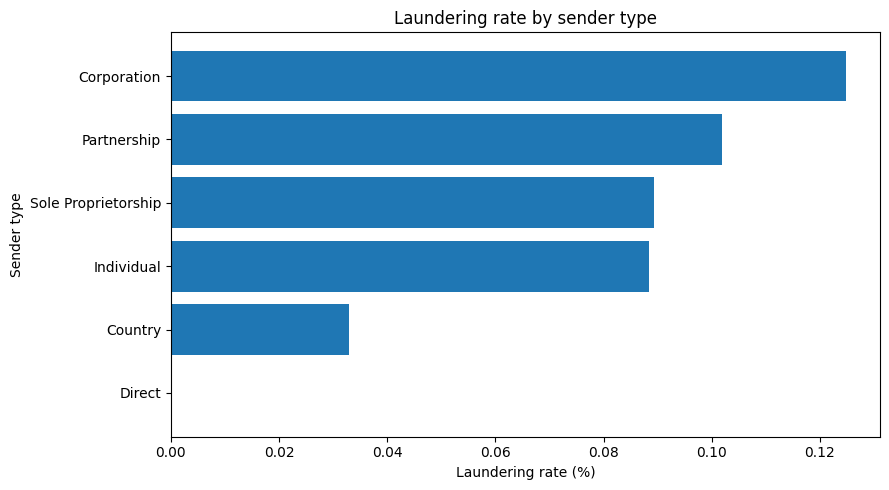

In [17]:
sender_types = accounts.select(
    F.col("bank_id").alias("from_bank"), F.col("account_number").alias("sender_account"),
    F.trim(F.regexp_replace("entity_name", r"\s*#.*$", "")).alias("entity_type"),
)
sender_training = train_df.join(sender_types, ["from_bank", "sender_account"], "left")
entity_risk = sender_training.groupBy("entity_type").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).toPandas()
display(entity_risk.round(4))
plot_data = entity_risk.sort_values("rate")

plt.figure(figsize=(9, 5))
plt.barh(plot_data["entity_type"], plot_data["rate"])
plt.title("Laundering rate by sender type")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Sender type")
plt.tight_layout()
plt.show()

Corporation has the highest observed rate, with 922 positives among 738,357 transactions. Partnership has the largest positive count, at 953. Rate and count answer different questions. Individual has only two positive records, so its rate has limited support.

#### Payment formats
Reuse Assessment 1’s payment format and currency grouping. The first table shows the ten combinations with the most training transactions. Amounts are totalled only within a currency. The chart compares label rates across formats.

,payment_format,payment_currency,transactions,amount_paid,positives
0,Cheque,US Dollar,371601,1.355933e+11,68
1,Credit Card,US Dollar,265802,8.674700e+08,46
2,Cheque,Euro,231310,7.873304e+10,56
3,Credit Card,Euro,165811,4.582520e+08,32
4,ACH,US Dollar,125951,1.195821e+11,841
5,Cash,US Dollar,98389,4.949174e+10,22
6,Reinvestment,US Dollar,97720,2.412700e+10,0
7,Bitcoin,Bitcoin,76898,1.494323e+06,31
8,ACH,Euro,73827,5.551849e+10,631
9,Reinvestment,Euro,61039,1.377238e+10,0


,payment_format,transactions,positives,rate
0,ACH,315374,2340,0.7420
1,Bitcoin,76937,31,0.0403
2,Cash,257554,60,0.0233
3,Cheque,977805,192,0.0196
4,Credit Card,694028,110,0.0158
5,Wire,90238,0,0.0000
6,Reinvestment,252099,0,0.0000


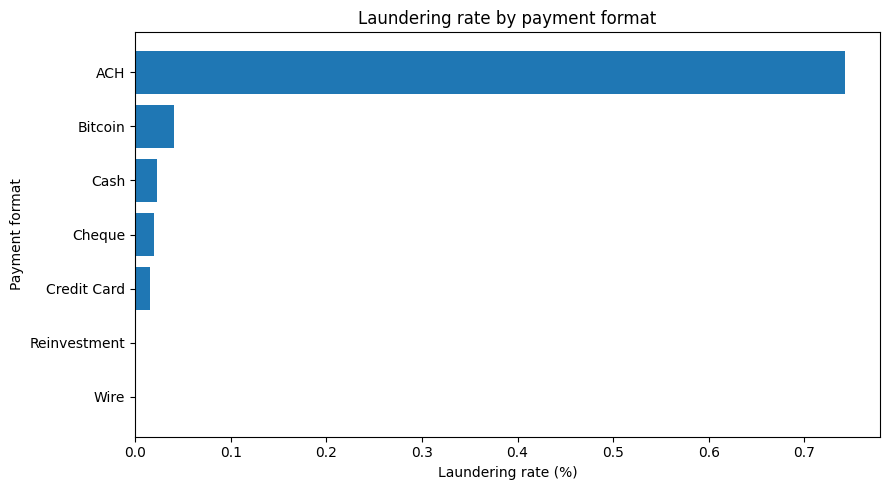

In [18]:
payment_summary = train_df.groupBy("payment_format", "payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("amount_paid").alias("amount_paid"),
    F.sum("is_laundering").alias("positives"),
)
display(payment_summary.orderBy(F.desc("transactions")).limit(10).toPandas().round(2))
format_risk = train_df.groupBy("payment_format").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).toPandas()
display(format_risk.round(4))
plot_data = format_risk.sort_values("rate")

plt.figure(figsize=(9, 5))
plt.barh(plot_data["payment_format"], plot_data["rate"])
plt.title("Laundering rate by payment format")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Payment format")
plt.tight_layout()
plt.show()

ACH contains 2,340 of the 2,733 training positives. Its rate is much higher than the other formats, making payment format a useful candidate feature. Zero observed positives for a format do not establish that future payments are safe.

#### Payment currencies
Compare both the number and proportion of laundering labels. Currency names identify units of payment and are not reliable evidence of where a transaction took place.

,payment_currency,transactions,positives,rate
0,Saudi Riyal,46940,191,0.4069
1,Euro,612713,732,0.1195
2,Yen,81330,86,0.1057
3,Australian Dollar,71778,71,0.0989
4,US Dollar,993890,977,0.0983
5,Swiss Franc,123155,111,0.0901
6,Canadian Dollar,73212,65,0.0888
7,Yuan,112238,99,0.0882
8,Rupee,100047,88,0.0880
9,Ruble,81242,71,0.0874


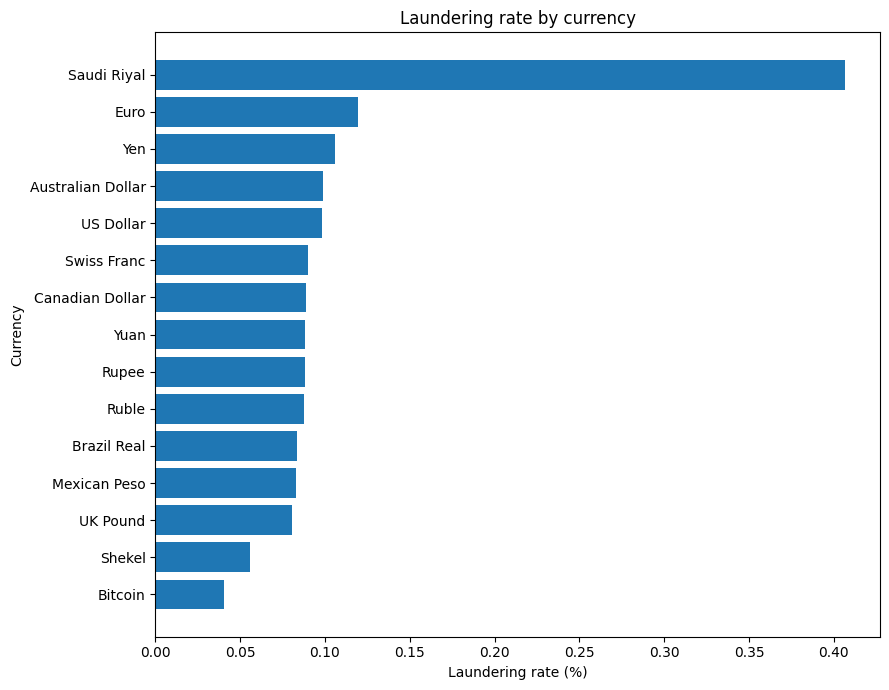

In [19]:
currency_risk = train_df.groupBy("payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).toPandas()
display(currency_risk.round(4))
plot_data = currency_risk.sort_values("rate")

plt.figure(figsize=(9, 7))
plt.barh(plot_data["payment_currency"], plot_data["rate"])
plt.title("Laundering rate by currency")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Currency")
plt.tight_layout()
plt.show()

Saudi Riyal has the highest rate at 0.4069%, with 191 positives. USD and Euro have the largest positive counts, at 977 and 732. A high rate is different from a large number of cases; both matter when deciding which patterns deserve attention.

#### Does the payment format pattern change across currencies?
Compare ACH with all other formats within each currency. This gives an overview with two bars per currency; the next heatmap keeps all formats separate. Rates use the transaction count of each currency and format group, rather than the size of the whole dataset.

In [20]:
format_currency_risk = train_df.withColumn(
    "format_group", F.when(F.col("payment_format") == "ACH", "ACH").otherwise("Other formats")
).groupBy("payment_currency", "format_group").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).toPandas()
currencies = currency_risk["payment_currency"].tolist()
display(format_currency_risk.sort_values("rate", ascending=False).head(6).round(3))

,payment_currency,format_group,transactions,positives,rate
15,Saudi Riyal,ACH,5191,186,3.583
13,Euro,ACH,73827,631,0.855
20,Yen,ACH,9590,78,0.813
0,Australian Dollar,ACH,7825,62,0.792
12,Swiss Franc,ACH,13647,95,0.696
9,Mexican Peso,ACH,6418,44,0.686


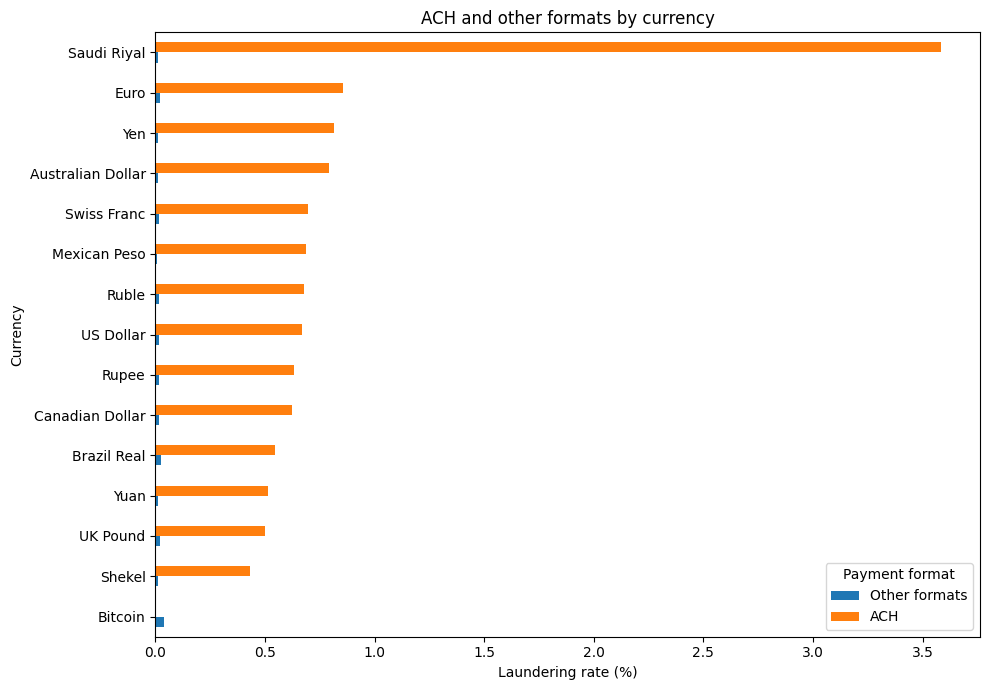

In [21]:
plot_data = format_currency_risk.pivot(index="payment_currency", columns="format_group", values="rate")
plot_data = plot_data[["Other formats", "ACH"]].sort_values("ACH")

plot_data.plot.barh(figsize=(10, 7))
plt.title("ACH and other formats by currency")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Currency")
plt.legend(title="Payment format")
plt.tight_layout()
plt.show()

Saudi Riyal ACH payments have a 3.58% rate, compared with 0.67% for USD ACH and 0.85% for Euro ACH. ACH accounts for 186 of the 191 Saudi Riyal positives. This shows why format and currency should be considered together. The Bitcoin-currency ACH group has only 18 transactions and no positives, so that comparison is particularly limited. These results do not support copying Assessment 1’s Saudi Riyal threshold into the model.

#### Payment format and currency heatmap
Each cell shows the laundering percentage within a format and currency. Blank cells have fewer than 1,000 records, so their rates are hidden. The count table shows the size of each group.

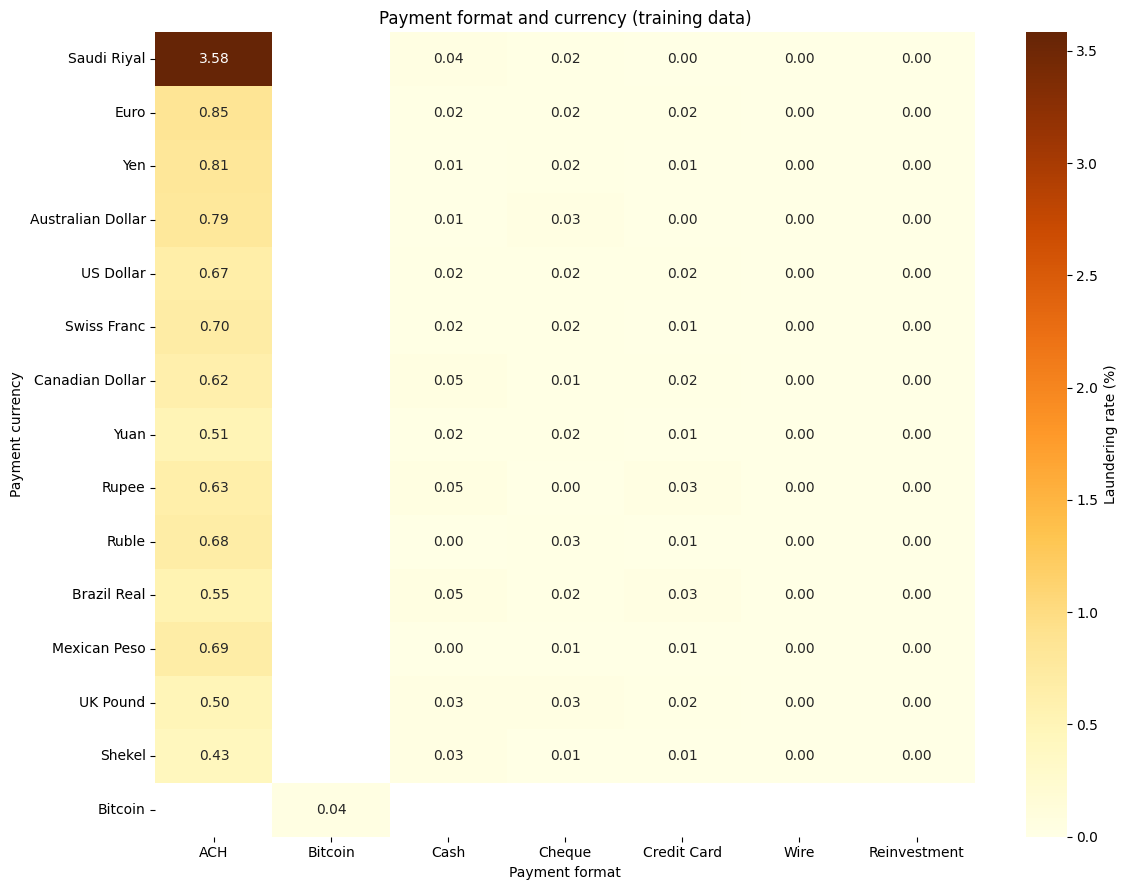

payment_format,ACH,Bitcoin,Cash,Cheque,Credit Card,Wire,Reinvestment
payment_currency,,,,,,,
Saudi Riyal,5191,0,4972,18130,12573,1853,4221
Euro,73827,18,59696,231310,165811,21012,61039
Yen,9590,0,8362,31066,21592,2900,7820
Australian Dollar,7825,0,7189,27842,19682,2542,6698
US Dollar,125951,10,98389,371601,265802,34417,97720
Swiss Franc,13647,4,12545,47290,33158,4388,12123
Canadian Dollar,8696,0,7344,27907,19784,2515,6966
Yuan,16995,1,10773,40891,29151,3807,10620
Rupee,11728,6,10270,38632,26326,3541,9544


In [22]:
payment_grid = payment_summary.withColumn("rate", 100 * F.col("positives") / F.col("transactions")).toPandas()
format_order = format_risk["payment_format"].tolist()
rate_grid = payment_grid.pivot(index="payment_currency", columns="payment_format", values="rate").reindex(index=currencies, columns=format_order)
count_grid = payment_grid.pivot(index="payment_currency", columns="payment_format", values="transactions").reindex_like(rate_grid).fillna(0)
plt.figure(figsize=(12, 9))
sns.heatmap(rate_grid, mask=count_grid < 1000, annot=True, fmt=".2f", cmap="YlOrBr",
            vmin=0, cbar_kws={"label": "Laundering rate (%)"})
plt.title("Payment format and currency (training data)")
plt.xlabel("Payment format")
plt.ylabel("Payment currency")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
display(count_grid.astype(int))

ACH has the highest displayed rate in each fiat currency, reaching 3.58% for Saudi Riyal. Other formats have much lower rates. Blank cells lack enough records for this comparison. A displayed 0.00 may be a small rate rounded to two decimals.

#### Amount box plots across currencies
Compare the two labels within each currency. Boxes show the middle 50% of amounts; whiskers mark the 5th and 95th percentiles. Spark estimates these percentiles from all training records.

The log scale makes the wide amount range readable. Each panel has its own scale, so amounts should not be compared between currencies. The table gives group counts and medians.

In [23]:
amount_quantiles = train_df.groupBy("payment_currency", "is_laundering").agg(
    F.count("*").alias("transactions"),
    F.percentile_approx("amount_paid", [0.05, 0.25, 0.5, 0.75, 0.95], 10000).alias("quantiles"),
).toPandas()
amount_quantiles["median"] = amount_quantiles.quantiles.map(lambda q: q[2])
display(amount_quantiles[["payment_currency", "is_laundering", "transactions", "median"]].sort_values(["payment_currency", "is_laundering"]))

,payment_currency,is_laundering,transactions,median
9,Australian Dollar,0,71707,1289.440000
13,Australian Dollar,1,71,5598.370000
0,Bitcoin,0,76893,0.071712
29,Bitcoin,1,31,0.225070
28,Brazil Real,0,37088,5340.480000
22,Brazil Real,1,31,22129.520000
8,Canadian Dollar,0,73147,1149.460000
18,Canadian Dollar,1,65,7755.910000
1,Euro,0,611981,742.790000
25,Euro,1,732,5313.330000


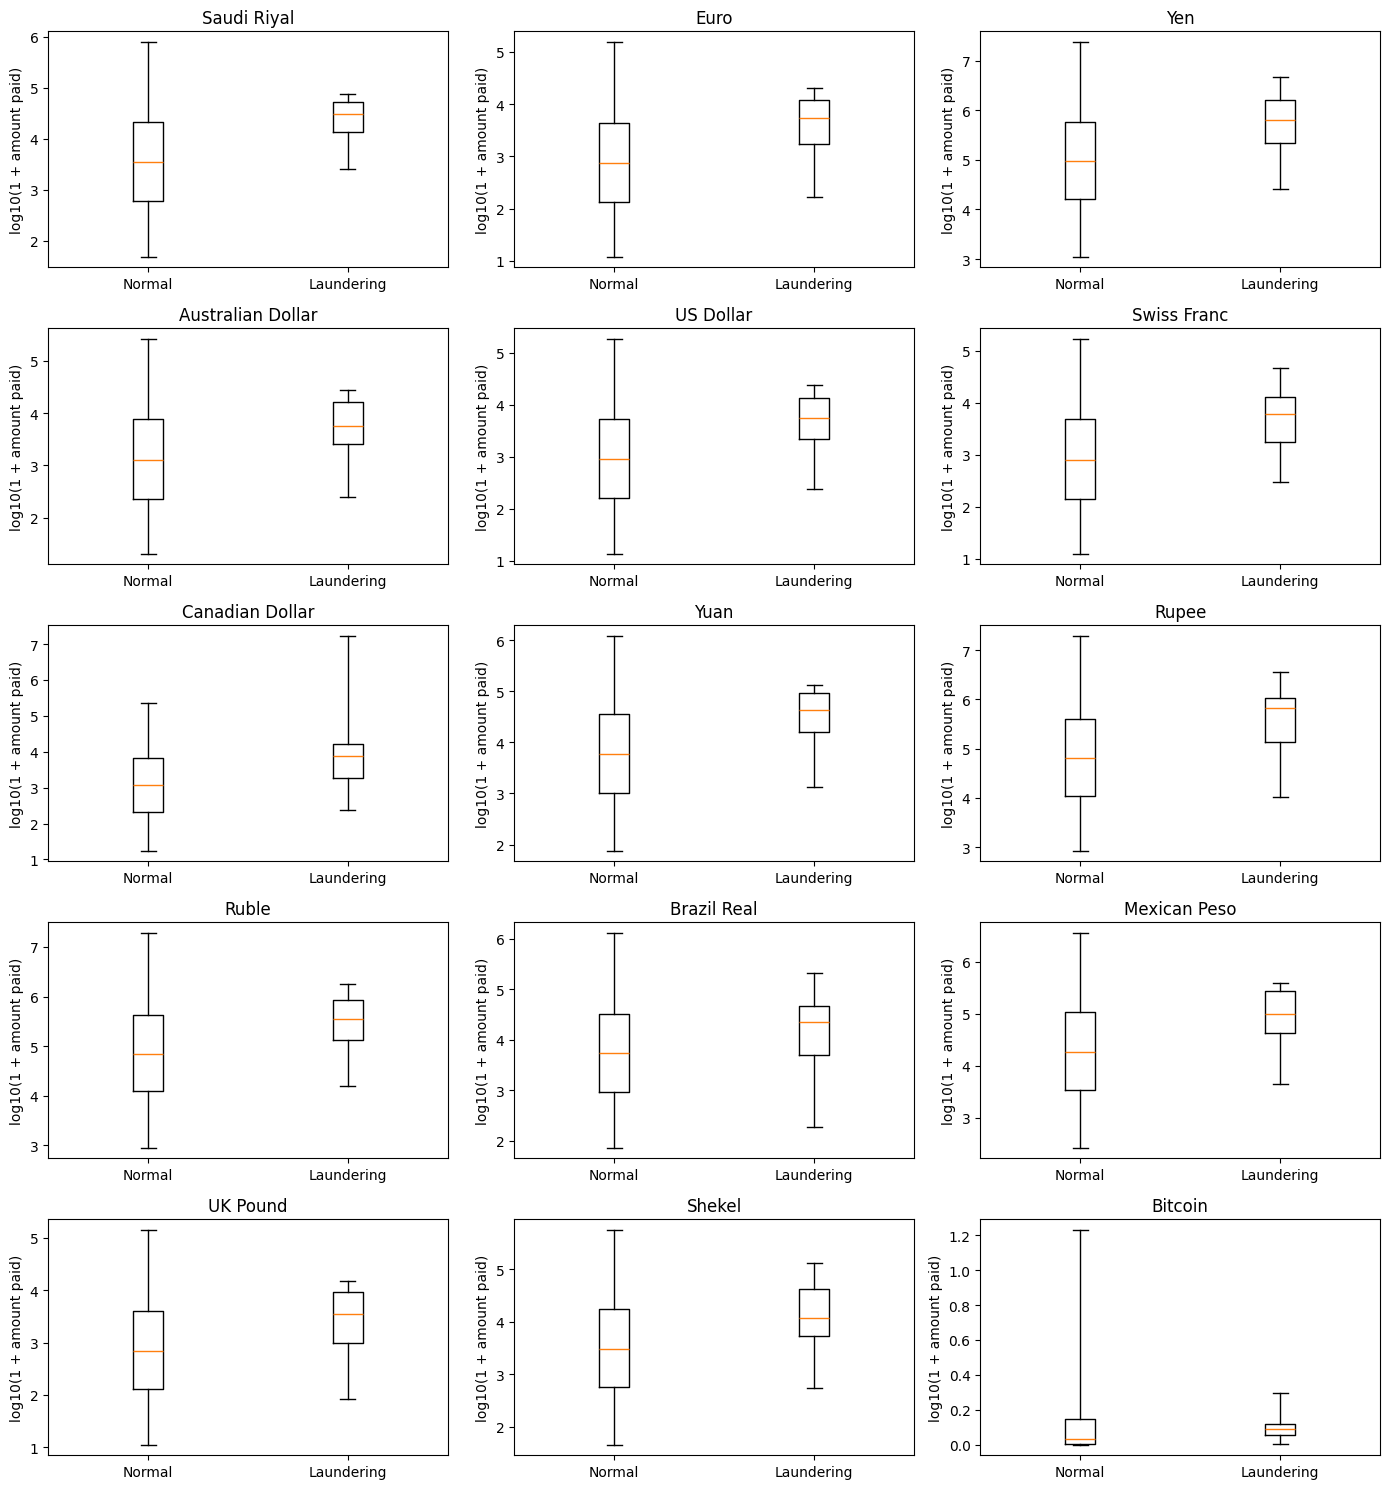

In [24]:
fig, axes = plt.subplots(5, 3, figsize=(14, 15))
for ax, currency in zip(axes.flat, currencies):
    rows = amount_quantiles[amount_quantiles["payment_currency"] == currency].sort_values("is_laundering")
    boxes = []
    for quantiles in rows["quantiles"]:
        low, q1, median, q3, high = np.log10(1 + np.array(quantiles))
        boxes.append(dict(whislo=low, q1=q1, med=median, q3=q3, whishi=high))
    ax.bxp(boxes, showfliers=False)
    ax.set_title(currency)
    ax.set_xticks([1, 2], ["Normal", "Laundering"])
    ax.set_ylabel("log10(1 + amount paid)")
plt.tight_layout()
plt.show()

The laundering median is higher than the normal median in all 15 currencies. For example, the approximate medians are USD 5,517.96 versus 899.49, Euro 5,313.33 versus 742.79, and Saudi Riyal 30,855.39 versus 3,455.32. These are comparisons within each currency; the numbers should not be compared as equivalent monetary values across currencies.

The boxes and whiskers still overlap, and the positive groups contain only 31 to 977 observations. Higher typical amounts therefore provide context rather than a clean boundary between labels. Different payment-format mixes can also contribute to these pooled differences.

#### Amount histograms for three contrasting currencies
Box plots summarise spread; histograms show the shape of each distribution. USD and Euro have the most positive records, while Saudi Riyal has the highest overall label rate. These three panels provide a closer view of those groups, alongside the all-currency box plots above.

Each class is normalised separately to 100%, so its shape remains visible despite the class imbalance. The plots use every training record in the selected currencies and bins of width 0.25 on log10(1 + amount paid). They do not show the relative sizes of the two classes.

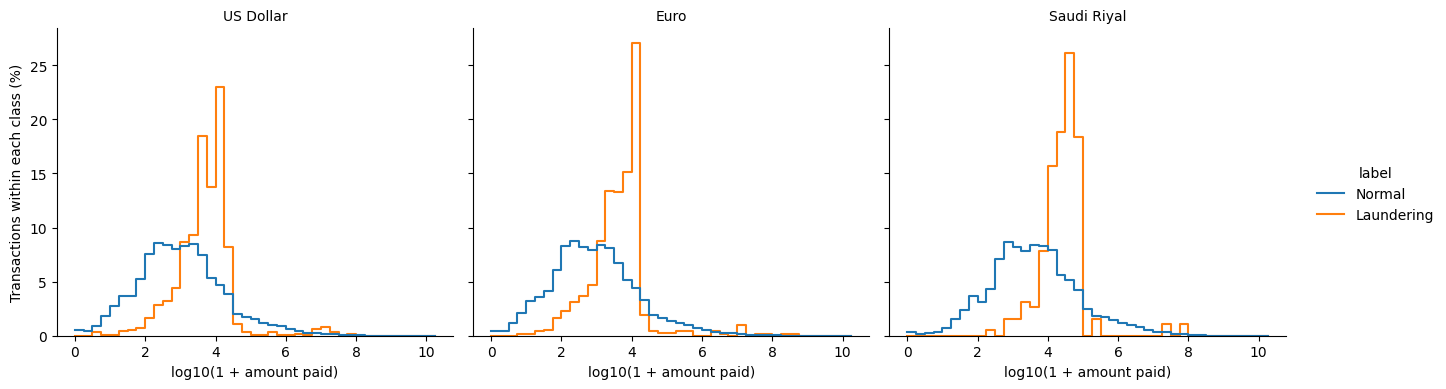

In [25]:
focus_currencies = ["US Dollar", "Euro", "Saudi Riyal"]
amount_bins = train_df.filter(F.col("payment_currency").isin(focus_currencies)).groupBy(
    "payment_currency", "is_laundering",
    F.floor(F.log10(F.col("amount_paid") + 1) * 4).cast("int").alias("bin"),
).count().toPandas()
histogram_data = amount_bins.assign(
    log_amount=(amount_bins["bin"] + 0.5) / 4,
    label=amount_bins["is_laundering"].map({0: "Normal", 1: "Laundering"}),
)
histogram = sns.displot(
    data=histogram_data, x="log_amount", weights="count", hue="label",
    hue_order=["Normal", "Laundering"], col="payment_currency", col_order=focus_currencies,
    binwidth=0.25, binrange=(0, (amount_bins["bin"].max() + 1) / 4),
    stat="percent", common_norm=False, element="step", fill=False, height=4, aspect=1.1,
)
histogram.set_axis_labels("log10(1 + amount paid)", "Transactions within each class (%)")
histogram.set_titles("{col_name}")
plt.show()

The positive distributions are more concentrated than the normal distributions in these three currencies. Their tallest bins are around 10,000 to 17,800 for USD and Euro, and 31,600 to 56,200 for Saudi Riyal. Those bins contain approximately 23%, 27% and 26% of the respective positive classes.

Normal payments also occur throughout those ranges and extend into large upper tails. The histograms explain why a shift in the median does not make amount alone a reliable classifier. The curves show within-class percentages, not the probability that an amount is laundering.

#### Relative amount and laundering across all currencies
Is a relatively large payment more likely to carry a laundering label? Calculate the median, 90th and 99th percentiles separately for each payment currency, then put each transaction into one of four amount bands. A yen payment is compared with other yen payments, and a Saudi Riyal payment with other Saudi Riyal payments. No exchange-rate conversion or addition of different currency amounts is needed.

All 15 currencies contribute. Percentiles are approximate, and tied amounts mean the groups need not contain exactly 50%, 40%, 9% and 1% of records. The combined rates still reflect the mix of currencies and formats, so they are descriptive rather than an isolated effect of amount. The cutoffs are calculated from training data only and are used here for exploration.

,amount_band,transactions,positives,rate
0,1. Up to median,1331885,384,0.0288
1,2. Median to 90th percentile,1065597,2237,0.2099
2,3. 90th to 99th percentile,239751,58,0.0242
3,4. Above 99th percentile,26802,54,0.2015


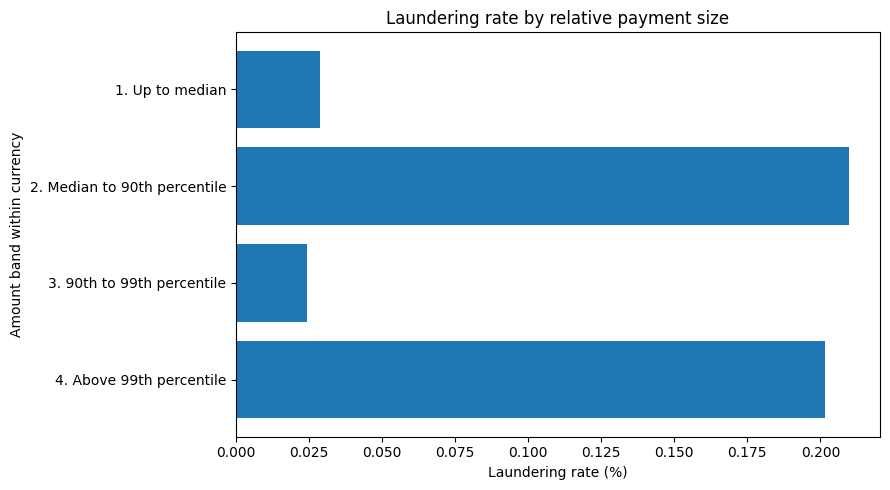

In [26]:
amount_cutoffs = train_df.groupBy("payment_currency").agg(
    F.percentile_approx("amount_paid", [0.5, 0.9, 0.99], 10000).alias("cutoffs")
)
amount_bands = train_df.join(amount_cutoffs, "payment_currency").withColumn(
    "amount_band",
    F.when(F.col("amount_paid") <= F.col("cutoffs")[0], "1. Up to median")
     .when(F.col("amount_paid") <= F.col("cutoffs")[1], "2. Median to 90th percentile")
     .when(F.col("amount_paid") <= F.col("cutoffs")[2], "3. 90th to 99th percentile")
     .otherwise("4. Above 99th percentile"),
)
amount_risk = amount_bands.groupBy("amount_band").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy("amount_band").toPandas()
display(amount_risk.round(4))
plot_data = amount_risk.sort_values("amount_band", ascending=False)

plt.figure(figsize=(9, 5))
plt.barh(plot_data["amount_band"], plot_data["rate"])
plt.title("Laundering rate by relative payment size")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Amount band within currency")
plt.tight_layout()
plt.show()

The median-to-90th-percentile band has the highest observed rate, 0.2099%, and contains 2,237 of the 2,733 positives, or 81.85%. Payments above the 99th percentile have a similar rate of 0.2015%, but only 54 positives. The intervening 90th-to-99th-percentile band has a much lower rate of 0.0242%.

The relationship is not a steady increase in laundering rate as relative amount grows. A single large-payment threshold would miss much of the observed pattern. Relative size is useful context alongside payment format and currency, but these pooled rates do not prove an independent effect of amount.

#### Paid and received amount check
Do the two amount columns provide different information? Compare them across all training records where both amounts use the same currency. Differences between amounts in different currencies would mix units.

In [27]:
same_currency = train_df.filter(F.col("payment_currency") == F.col("receiving_currency"))
paired_amount_summary = same_currency.groupBy("payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    F.sum(F.when(F.col("amount_paid") != F.col("amount_received"), 1).otherwise(0)).alias("unequal_amounts"),
).toPandas()
display(paired_amount_summary.sort_values("transactions", ascending=False))

,payment_currency,transactions,positives,unequal_amounts
0,US Dollar,973630,977,0
3,Euro,605100,732,0
12,Swiss Franc,122933,111,0
4,Yuan,106850,99,0
13,Shekel,100759,56,0
10,Rupee,99419,88,0
1,UK Pound,93219,76,0
14,Ruble,81076,71,0
5,Yen,80497,86,0
7,Bitcoin,76898,31,0


Paid and received amounts are identical in all 2,626,282 same-currency training transactions, across all 15 currencies. A scatter plot of this pair would collapse onto one line and add little information.

For these records, amount received duplicates amount paid. Cross-currency amounts were excluded because their difference would mix units. This supports avoiding a raw paid-minus-received feature across the whole dataset.

#### Does payment format change the amount relationship?
Compare amount bands within each payment format. The bands use each currency's own percentiles and include all training records. The table gives the counts behind the rates; the credit card group above the 99th percentile has only one record.

,payment_format,amount_band,transactions,positives,rate
16,ACH,1. Up to median,148124,198,0.134
0,ACH,2. Median to 90th percentile,127414,2059,1.616
20,ACH,3. 90th to 99th percentile,35081,35,0.100
1,ACH,4. Above 99th percentile,4755,48,1.009
18,Bitcoin,1. Up to median,38457,7,0.018
25,Bitcoin,2. Median to 90th percentile,30776,24,0.078
24,Bitcoin,3. 90th to 99th percentile,6927,0,0.000
27,Bitcoin,4. Above 99th percentile,777,0,0.000
11,Cash,1. Up to median,128559,34,0.026
2,Cash,2. Median to 90th percentile,86918,19,0.022


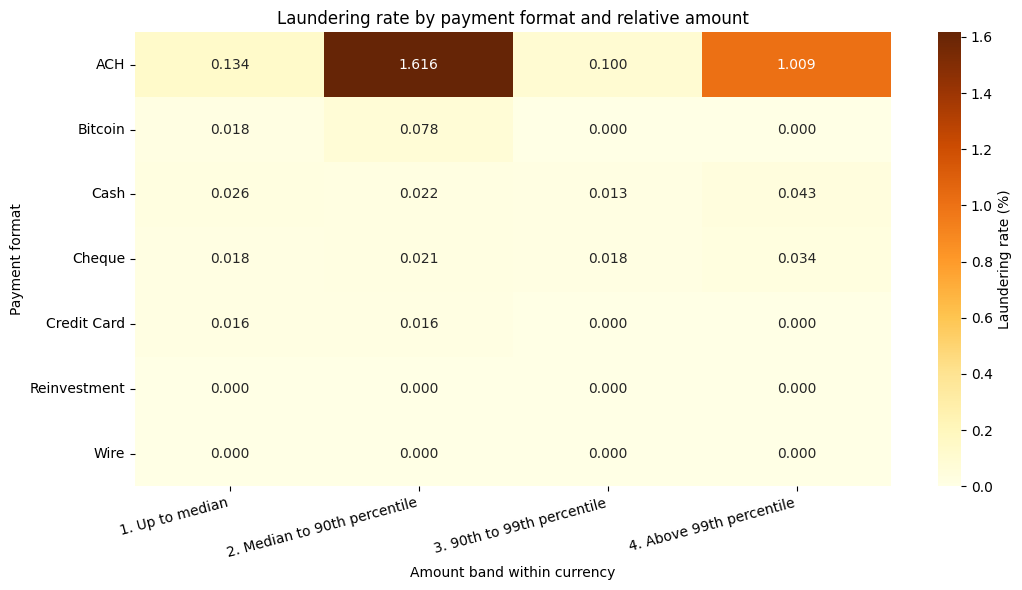

In [28]:
amount_format = amount_bands.groupBy("payment_format", "amount_band").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).toPandas()
band_order = sorted(amount_format.amount_band.unique())
format_order = ["ACH", "Bitcoin", "Cash", "Cheque", "Credit Card", "Reinvestment", "Wire"]
display(amount_format.sort_values(["payment_format", "amount_band"]).round(3))
rate_grid = amount_format.pivot(index="payment_format", columns="amount_band", values="rate").reindex(format_order)[band_order]

plt.figure(figsize=(11, 6))
sns.heatmap(rate_grid, annot=True, fmt=".3f", cmap="YlOrBr", vmin=0,
            cbar_kws={"label": "Laundering rate (%)"})
plt.title("Laundering rate by payment format and relative amount")
plt.xlabel("Amount band within currency")
plt.ylabel("Payment format")
plt.xticks(rotation=15, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

The middle amount band is mainly an ACH pattern. ACH payments between the median and 90th percentile contain 2,059 positives among 127,414 transactions, a rate of 1.616%. This group accounts for only 4.78% of training transactions but 75.34% of all positive labels. It also supplies 92.04% of the positives in the pooled middle band.

Within ACH, this rate is about 12.1 times the rate below the median (0.134%). It drops to 0.100% in the 90th-to-99th band before rising to 1.009% above the 99th percentile. Cash, cheque and credit card payments do not show the same middle-band peak. Transaction size therefore needs to be considered together with payment format; a rule that only looks for the largest payments would miss most of the labelled cases.

These are descriptive training results. Even in the ACH middle band, 98.384% of transactions have label 0. The concentration suggests a useful feature relationship, not a sufficient detection rule or an independently measured causal effect.

#### Does the ACH pattern hold across currencies?
Compare ACH payments between each currency's median and 90th percentile. These cutoffs use all training payments in that currency. The table shows whether a high rate represents many cases or a small group.

,payment_currency,transactions,positives,rate
10,Saudi Riyal,2068,170,8.221
2,Euro,29975,552,1.842
4,Yen,3640,67,1.841
6,Australian Dollar,3180,54,1.698
11,Mexican Peso,2500,41,1.640
14,Swiss Franc,5527,82,1.484
12,Ruble,3452,51,1.477
0,US Dollar,51871,750,1.446
9,Rupee,4568,61,1.335
1,Brazil Real,1693,21,1.240


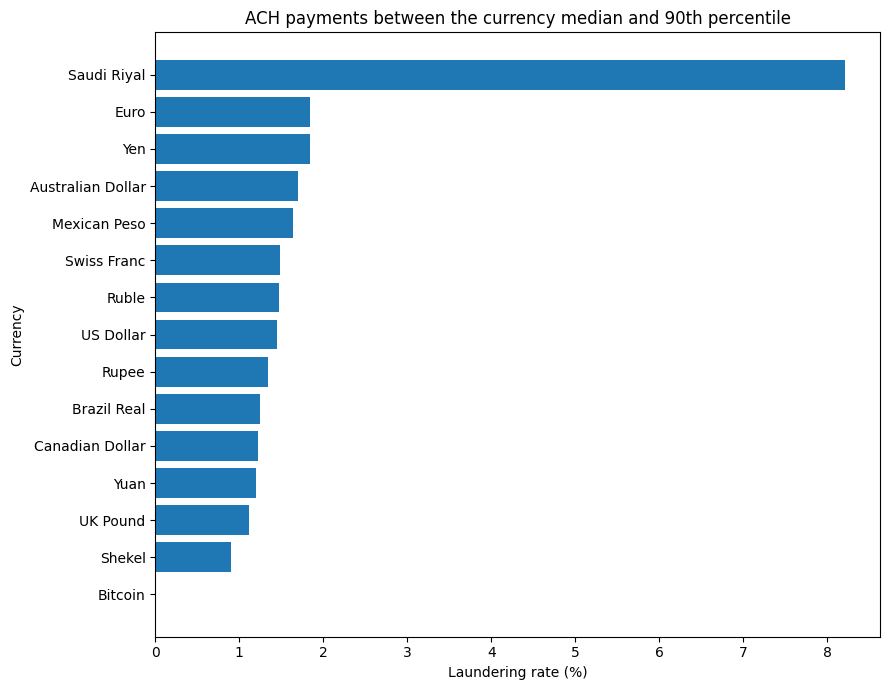

In [29]:
ach_middle = amount_bands.filter(
    (F.col("payment_format") == "ACH") & (F.col("amount_band") == band_order[1])
).groupBy("payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).toPandas().sort_values("rate", ascending=False)
display(ach_middle.round(3))
plot_data = ach_middle.sort_values("rate")

plt.figure(figsize=(9, 7))
plt.barh(plot_data["payment_currency"], plot_data["rate"])
plt.title("ACH payments between the currency median and 90th percentile")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Currency")
plt.tight_layout()
plt.show()

Saudi Riyal stands out even within the same payment format and relative amount band: 170 of 2,068 transactions are positive, or 8.22%. Euro has 552 of 29,975 (1.84%) and USD has 750 of 51,871 (1.45%). Saudi Riyal has the highest observed rate, while USD contributes the largest number of cases in this group.

This narrows the earlier Saudi Riyal finding to a specific combination of currency, format and relative size. It is not explained solely by comparing ACH in one currency with other formats in another. However, the bands cover different monetary ranges and may still differ in entities, banks and timing. The single Bitcoin-denominated ACH record in this band provides too little evidence for a rate comparison.

The modelling implication is to evaluate amount, currency and payment format together. These rates and labels are not predictor columns, and any apparent benefit must be checked on validation data before drawing conclusions about model performance.

#### Transaction timing
Use the original transaction timestamp with the notebook’s UTC convention. Hourly and daily summaries cover all training currencies. Daily counts help show whether a high rate is based on very few records.

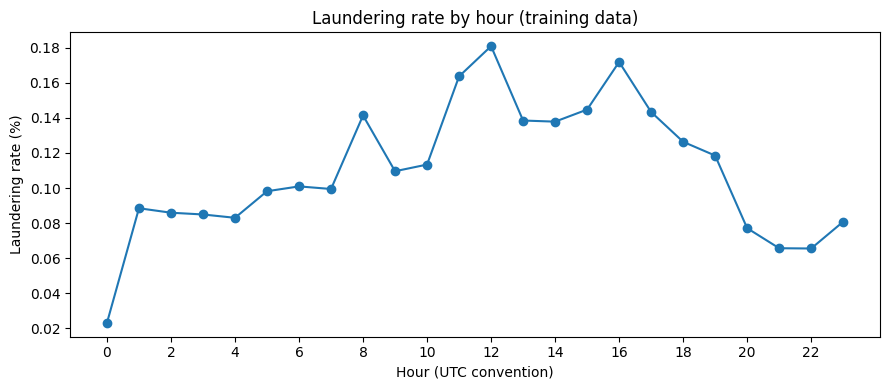

In [30]:
hour_risk = train_df.groupBy(F.hour("timestamp").alias("hour")).agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy("hour").toPandas()
day_risk = train_df.groupBy(F.date_format("timestamp", "yyyy-MM-dd").alias("date")).agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy("date").toPandas()
plt.figure(figsize=(9, 4))
plt.plot(hour_risk["hour"], hour_risk["rate"], marker="o")
plt.xticks(range(0, 24, 2))
plt.xlabel("Hour (UTC convention)")
plt.ylabel("Laundering rate (%)")
plt.title("Laundering rate by hour (training data)")
plt.tight_layout()
plt.show()

,date,transactions,positives,rate
0,2022-09-01,584378,182,0.031
1,2022-09-02,396284,242,0.061
2,2022-09-03,108861,196,0.180
3,2022-09-04,109264,214,0.196
4,2022-09-05,253487,242,0.095
5,2022-09-06,252434,284,0.113
6,2022-09-07,253643,245,0.097
7,2022-09-08,253058,281,0.111
8,2022-09-09,342588,257,0.075
9,2022-09-10,109437,224,0.205


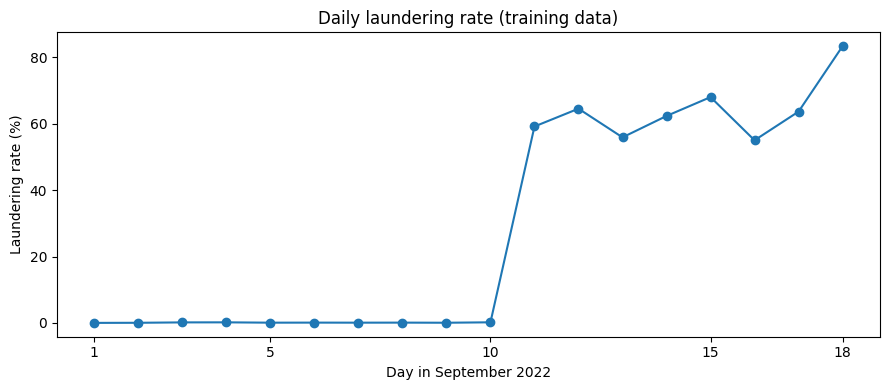

In [31]:
display(day_risk.round(3))
plt.figure(figsize=(9, 4))
plt.plot(pd.to_datetime(day_risk["date"]).dt.day, day_risk["rate"], marker="o")
plt.xticks([1, 5, 10, 15, 18])
plt.xlabel("Day in September 2022")
plt.ylabel("Laundering rate (%)")
plt.title("Daily laundering rate (training data)")
plt.tight_layout()
plt.show()

After 10 September, only 601 training records remain, including 366 positives. This produces a 60.90% rate, but describes just 0.0226% of the training transactions. The final date has five positives among six records. The daily plot therefore reflects a substantial change in the dataset, not evidence of a recurring seasonal trend.

Absolute calendar date will be excluded from the initial feature set because it could identify this sparse tail. The 333,223 records at midnight also deserve caution. Time features need validation, and our random split does not establish performance on a later period.

#### Weekday and hour together
This view includes all training transactions from 1 to 18 September. The table shows the counts behind the five highest rates. With little activity after 10 September, these results cannot establish a stable weekly pattern.

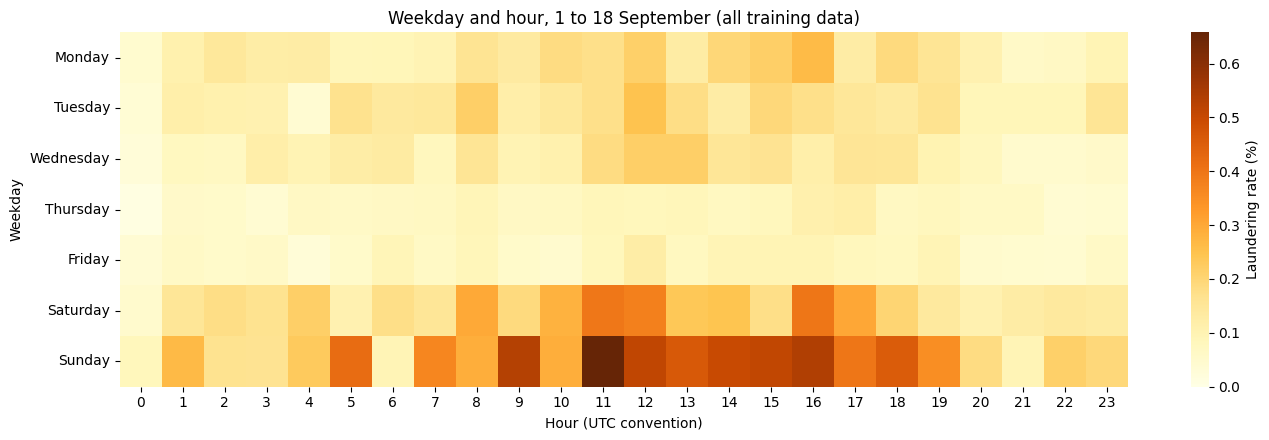

,weekday,hour,transactions,positives,rate
90,Sunday,11,4256,28,0.657895
65,Sunday,16,4267,23,0.539020
93,Sunday,9,4332,23,0.530933
14,Sunday,12,4099,21,0.512320
42,Sunday,15,4321,22,0.509141


In [32]:
time_grid = train_df.groupBy(
    F.date_format("timestamp", "EEEE").alias("weekday"), F.hour("timestamp").alias("hour"),
).agg(F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
      (100 * F.avg("is_laundering")).alias("rate")).toPandas()
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hourly_rates = time_grid.pivot(index="weekday", columns="hour", values="rate").reindex(index=days, columns=range(24))
plt.figure(figsize=(14, 4.5))
sns.heatmap(hourly_rates, cmap="YlOrBr", vmin=0,
            cbar_kws={"label": "Laundering rate (%)"})
plt.title("Weekday and hour, 1 to 18 September (all training data)")
plt.xlabel("Hour (UTC convention)")
plt.ylabel("Weekday")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
display(time_grid.sort_values("rate", ascending=False).head(5))

Sunday has the highest overall rate at 0.3151%, followed by Saturday at 0.1956%. Sunday at 11:00 is the highest hourly group, with 28 positives among 4,256 transactions (0.6579%).

The final eight dates add only 601 transactions but 366 positives. This uneven coverage affects the pattern, so weekday and hour still need validation.

#### Bank and currency relationships
Do payments within the same bank have a different label rate from payments between banks? Does changing currency show a different pattern? Both comparisons include all training currencies. Bank and currency differences do not by themselves identify an international payment.

,bank_relationship,transactions,positives,rate
0,Different banks,2301360,2675,0.1162
1,Same bank,362675,58,0.0160


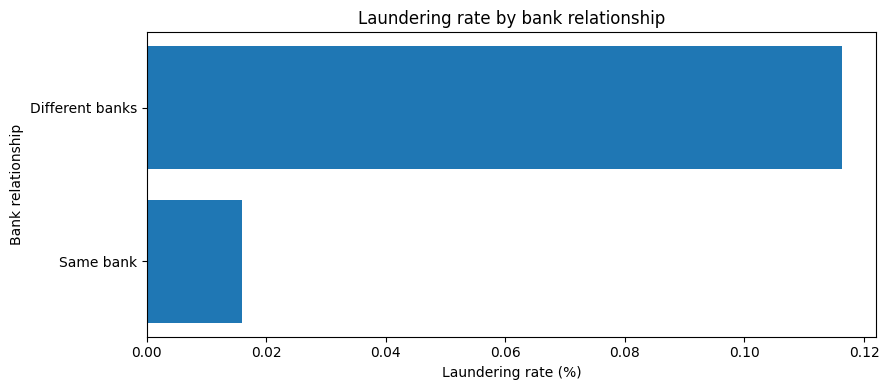

In [33]:
relationship_df = train_df.withColumn(
    "bank_relationship", F.when(F.col("from_bank") == F.col("to_bank"), "Same bank").otherwise("Different banks")
).withColumn(
    "currency_relationship", F.when(F.col("payment_currency") == F.col("receiving_currency"),
                                     "Same currency").otherwise("Different currencies")
)
bank_risk = relationship_df.groupBy("bank_relationship").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).toPandas()
display(bank_risk.round(4))
plot_data = bank_risk.sort_values("rate")

plt.figure(figsize=(9, 4))
plt.barh(plot_data["bank_relationship"], plot_data["rate"])
plt.title("Laundering rate by bank relationship")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Bank relationship")
plt.tight_layout()
plt.show()

Different-bank payments have a 0.1162% label rate, compared with 0.0160% for same-bank payments, about 7.3 times as high. They also contain 2,675 of the 2,733 positives. This supports testing a same-bank indicator, while recognising that other transaction characteristics may explain some of the difference.

,currency_relationship,transactions,positives,rate
0,Same currency,2626282,2733,0.1041
1,Different currencies,37753,0,0.0000


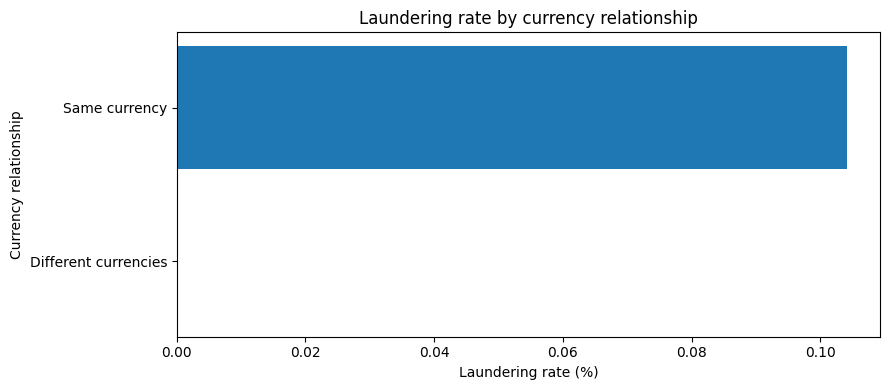

,bank_relationship,currency_relationship,transactions,positives
0,Different banks,Same currency,2301360,2675
1,Same bank,Different currencies,37753,0
2,Same bank,Same currency,324922,58


In [34]:
currency_change_risk = relationship_df.groupBy("currency_relationship").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).toPandas()
display(currency_change_risk.round(4))
plot_data = currency_change_risk.sort_values("rate")

plt.figure(figsize=(9, 4))
plt.barh(plot_data["currency_relationship"], plot_data["rate"])
plt.title("Laundering rate by currency relationship")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Currency relationship")
plt.tight_layout()
plt.show()
relationship_joint = relationship_df.groupBy("bank_relationship", "currency_relationship").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives")
).orderBy("bank_relationship", "currency_relationship").toPandas()
display(relationship_joint)

All 37,753 currency-changing payments have label 0 and occur within the same bank. This could reflect the synthetic data generation process and should not become an automatic safe-payment rule. The joint table also shows that bank and currency relationships are not independent in this dataset.

#### Account history and feature analysis
Compare previous activity, recent amounts and relationships using the training partition.

#### History available at each transaction
Accounts are identified by bank and account together. Use strictly earlier training transactions, with the start of each 1 hour or 24 hour window included. Exclude simultaneous transactions. Validation, test and streaming records never update the reference history.

Activity counts and distinct counterparties cover all currencies. Counts supporting amount means, and the means and totals themselves, use the current transaction's currency. Sender amounts use money paid; receiver amounts use money received. Self transfers contribute once to incoming and once to outgoing history.

This retains the existing random partitions and measures performance with partial account history, not a future time period.

In [35]:
from pyspark.sql import Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import SQLTransformer, StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.stat import Correlation

#### Read both sides of each payment
Each transaction supplies an outgoing event for the sender and an incoming event for the receiver.

In [36]:
def account_events(data):
    outgoing = data.select(
        "source_record_id", "model_partition",
        F.col("timestamp").cast("long").alias("event_second"),
        F.struct(F.col("from_bank").alias("bank"), F.col("sender_account").alias("account")).alias("account_key"),
        F.struct(F.col("to_bank").alias("bank"), F.col("receiver_account").alias("account")).alias("counterparty"),
        F.lit("out").alias("direction"),
        F.col("amount_paid").alias("amount"), F.col("payment_currency").alias("currency"),
    )
    incoming = data.select(
        "source_record_id", "model_partition",
        F.col("timestamp").cast("long").alias("event_second"),
        F.struct(F.col("to_bank").alias("bank"), F.col("receiver_account").alias("account")).alias("account_key"),
        F.struct(F.col("from_bank").alias("bank"), F.col("sender_account").alias("account")).alias("counterparty"),
        F.lit("in").alias("direction"),
        F.col("amount_received").alias("amount"), F.col("receiving_currency").alias("currency"),
    )
    return outgoing.unionByName(incoming)

#### Counts, gaps and recent amounts
The same account history supplies both directions. Currency windows keep amounts comparable.

In [37]:
def account_activity(events):
    account = Window.partitionBy("account_key").orderBy("event_second")
    money = Window.partitionBy("account_key", "currency").orderBy("event_second")
    previous = account.rangeBetween(Window.unboundedPreceding, -1)
    fields = []
    for direction in ["out", "in"]:
        known = (F.col("model_partition") == "train") & (F.col("direction") == direction)
        event = F.when(known, F.col("event_second"))
        amount = F.when(known, F.col("amount"))
        fields += [
            F.count(event).over(previous).alias(direction + "_count"),
            ((F.col("event_second") - F.max(event).over(previous)) / 3600).alias(direction + "_gap"),
        ]
        for hours in ([24] if direction == "out" else [1, 24]):
            recent = account.rangeBetween(-hours * 3600, -1)
            same_currency = money.rangeBetween(-hours * 3600, -1)
            fields += [
                F.count(event).over(recent).alias(f"{direction}_count_{hours}h"),
                F.count(amount).over(same_currency).alias(f"{direction}_money_count_{hours}h"),
                F.sum(amount).over(same_currency).alias(f"{direction}_sum_{hours}h"),
            ]
        fields.append(F.avg(amount).over(money.rangeBetween(-86400, -1)).alias(direction + "_mean_24h"))
    return events.select("source_record_id", "direction", *fields)

#### Historical distinct counterparties
Count each counterparty once, from its first earlier training payment. Repeated payments do not increase this count.

In [38]:
def counterparty_activity(events):
    keys = ["account_key", "direction"]
    first_payments = events.filter(F.col("model_partition") == "train").groupBy(
        *keys, "counterparty"
    ).agg(F.min("event_second").alias("event_second"))
    starts = first_payments.select(
        *keys, "event_second", F.lit(None).cast("long").alias("source_record_id"),
        F.lit(1).alias("new_counterparty"),
    )
    queries = events.select(
        *keys, "event_second", "source_record_id", F.lit(0).alias("new_counterparty"),
    )
    previous = Window.partitionBy(*keys).orderBy("event_second").rangeBetween(Window.unboundedPreceding, -1)
    counts = queries.unionByName(starts).select(
        "source_record_id", "direction",
        F.sum("new_counterparty").over(previous).alias("distinct_prior"),
    )
    return counts.filter(F.col("source_record_id").isNotNull()).fillna(0)

#### Previous and reverse payments
Count prior payments from A to B and check for an earlier B to A payment. Self transfers do not count as reverse payments.

In [39]:
def pair_activity(events):
    previous = Window.partitionBy("account_key", "counterparty").orderBy(
        "event_second"
    ).rangeBetween(Window.unboundedPreceding, -1)
    known = F.col("model_partition") == "train"
    counts = events.withColumn(
        "prior_pair_count", F.count(F.when(known & (F.col("direction") == "out"), 1)).over(previous)
    ).withColumn(
        "reverse_count", F.count(F.when(known & (F.col("direction") == "in"), 1)).over(previous)
    )
    return counts.filter(F.col("direction") == "out").select(
        "source_record_id", "prior_pair_count",
        ((F.col("reverse_count") > 0) & (F.col("account_key") != F.col("counterparty")))
        .cast("int").alias("has_prior_reverse_payment"),
    )

#### Attach the account history
Amount ratios remain missing when the denominator is unavailable or zero. Pass through similarity is missing when there is no recent receipt or both amounts are zero; otherwise it ranges from 0 to 1. Similar amounts do not prove that the same funds were forwarded.

In [40]:
def combine_account_features(data, activity, counterparties, pairs):
    sender = activity.filter(F.col("direction") == "out").select(
        "source_record_id", F.col("out_count").alias("sender_prior_count"),
        F.col("in_count").alias("sender_incoming_prior_count"),
        F.col("out_gap").alias("sender_gap_hours"), F.col("in_gap").alias("sender_incoming_gap_hours"),
        F.col("out_money_count_24h").alias("sender_previous_24h"),
        F.col("out_mean_24h").alias("sender_mean_24h"),
        F.col("in_count_1h").alias("sender_incoming_count_1h"),
        F.col("in_count_24h").alias("sender_incoming_count_24h"),
        F.col("in_money_count_1h").alias("sender_received_count_1h"),
        F.col("in_sum_1h").alias("sender_received_1h"),
        F.col("in_sum_24h").alias("sender_received_24h"),
        F.coalesce("out_sum_24h", F.lit(0)).alias("sender_sent_24h"),
    )
    receiver = activity.filter(F.col("direction") == "in").select(
        "source_record_id", F.col("in_count").alias("receiver_prior_count"),
        F.col("out_count").alias("receiver_outgoing_prior_count"),
        F.col("in_gap").alias("receiver_gap_hours"), F.col("out_gap").alias("receiver_outgoing_gap_hours"),
        F.col("in_money_count_24h").alias("receiver_previous_24h"),
        F.col("in_mean_24h").alias("receiver_mean_24h"),
        F.col("out_count_24h").alias("receiver_outgoing_count_24h"),
    )
    sender_links = counterparties.filter(F.col("direction") == "out").select(
        "source_record_id", F.col("distinct_prior").alias("sender_out_degree"),
    )
    receiver_links = counterparties.filter(F.col("direction") == "in").select(
        "source_record_id", F.col("distinct_prior").alias("receiver_in_degree"),
    )
    result = data.join(sender, "source_record_id").join(receiver, "source_record_id").join(
        sender_links, "source_record_id"
    ).join(receiver_links, "source_record_id").join(pairs, "source_record_id")
    return result.withColumn(
        "receiver_amount_ratio", F.when(F.col("receiver_mean_24h") > 0, F.col("amount_received") / F.col("receiver_mean_24h"))
    ).withColumn(
        "sender_amount_ratio_24h", F.when(F.col("sender_mean_24h") > 0, F.col("amount_paid") / F.col("sender_mean_24h"))
    ).withColumn(
        "sender_pass_through_1h", F.when(
            (F.col("sender_received_count_1h") > 0) & (F.greatest("amount_paid", "sender_received_1h") > 0),
            F.least("amount_paid", "sender_received_1h") / F.greatest("amount_paid", "sender_received_1h")
        )
    ).withColumn(
        "sender_outgoing_to_incoming_ratio_24h", F.when(F.col("sender_received_24h") > 0, F.col("sender_sent_24h") / F.col("sender_received_24h"))
    ).withColumn(
        "self_transfer", ((F.col("from_bank") == F.col("to_bank")) & (F.col("sender_account") == F.col("receiver_account"))).cast("int")
    )

In [41]:
events = account_events(development_df)
for name, records in [
    ("account_activity", account_activity(events)),
    ("counterparty_activity", counterparty_activity(events)),
    ("pair_activity", pair_activity(events)),
]:
    records.write.mode("overwrite").parquet(str(DATA_DIR / f"{name}.parquet"))

activity = spark.read.parquet(str(DATA_DIR / "account_activity.parquet"))
counterparties = spark.read.parquet(str(DATA_DIR / "counterparty_activity.parquet"))
pairs = spark.read.parquet(str(DATA_DIR / "pair_activity.parquet"))
feature_history = combine_account_features(development_df, activity, counterparties, pairs)
feature_history.write.mode("overwrite").parquet(str(DATA_DIR / "feature_history.parquet"))
feature_history = spark.read.parquet(str(DATA_DIR / "feature_history.parquet"))
history = feature_history.filter(F.col("model_partition") == "train")
history_check = history.agg(F.count("*").alias("rows"), F.sum("is_laundering").alias("positives")).first()
display(pd.DataFrame([history_check.asDict()]))

,rows,positives
0,2664035,2733


Rates use all transactions in each group as the denominator. Missing history is shown separately.

In [42]:
def history_summary(records, column, order):
    summary = records.groupBy(column).agg(
        F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
        F.sum(F.when(F.col("payment_format") == "ACH", 1).otherwise(0)).alias("ach_transactions"),
        F.sum(F.when(F.col("payment_format") == "ACH", F.col("is_laundering")).otherwise(0)).alias("ach_positives"),
    ).toPandas().set_index(column)
    summary = summary.reindex([group for group in order if group in summary.index])
    summary["rate"] = 100 * summary["positives"] / summary["transactions"]
    summary["ach_rate"] = 100 * summary["ach_positives"] / summary["ach_transactions"]
    return summary.rename_axis("group")

#### Previous interactions between accounts
Count earlier payments from the same sender to the same receiver. Zero identifies the first observed interaction. The model will use the count rather than the chart bands.

,transactions,positives,ach_transactions,ach_positives,rate,ach_rate
group,,,,,,
0: first observed,738739,2312,106676,2213,0.313,2.075
1,340951,120,32689,61,0.035,0.187
2 to 4,639323,150,59181,47,0.023,0.079
5 to 9,653793,117,69358,15,0.018,0.022
10 or more,291229,34,47470,4,0.012,0.008


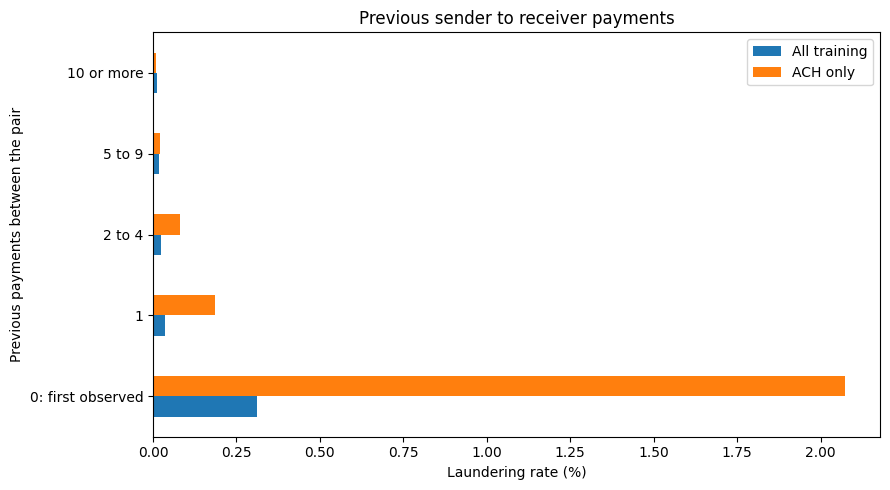

In [43]:
pair_order = ["0: first observed", "1", "2 to 4", "5 to 9", "10 or more"]
pair_records = history.withColumn(
    "pair_band", F.when(F.col("prior_pair_count") == 0, pair_order[0])
    .when(F.col("prior_pair_count") == 1, pair_order[1])
    .when(F.col("prior_pair_count") <= 4, pair_order[2])
    .when(F.col("prior_pair_count") <= 9, pair_order[3]).otherwise(pair_order[4])
)
pair_summary = history_summary(pair_records, "pair_band", pair_order)
display(pair_summary.round(3))
plot_data = pair_summary[["rate", "ach_rate"]].rename(columns={"rate": "All training", "ach_rate": "ACH only"})
plot_data.plot.barh(figsize=(9, 5))
plt.title("Previous sender to receiver payments")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Previous payments between the pair")
plt.tight_layout()
plt.show()

First observed interactions contain 84.60% of positives but only 27.73% of transactions. Within ACH, their rate is 2.075% (2,213/106,676), compared with 0.061% for established pairs. Most still have label 0, and an older relationship may exist outside this sample.

#### Time since the previous transaction
Measure hours since the sender's last outgoing payment and the receiver's last incoming payment. Both use earlier history across currencies. Keep missing history separate from a short gap.

transactions  positives  ach_transactions  \
Direction         Gap                                                           
Sender outgoing   No earlier event        385263        484             49240   
                  Up to 1 hour            959426        448            102673   
                  1 to 24 hours           935618        855             97596   
                  Over 24 hours           383728        946             65865   
Receiver incoming No earlier event        352901        281             26324   
                  Up to 1 hour            775247        394            129220   
                  1 to 24 hours           900718       1031             92245   
                  Over 24 hours           635169       1027             67585   

                                    ach_positives   rate  ach_rate  
Direction         Gap                                               
Sender outgoing   No earlier event            473  0.126     0.961  
                  Up to 1 hour                 94  0.047     0.092  
                  1 to 24 hours               849  0.091     0.870  
                  Over 24 hours               924  0.247     1.403  
Receiver incoming No earlier event            249  0.080     0.946  
                  Up to 1 hour                281  0.051     0.217  
                  1 to 24 hours               891  0.114     0.966  
                  Over 24 hours               919  0.162     1.360

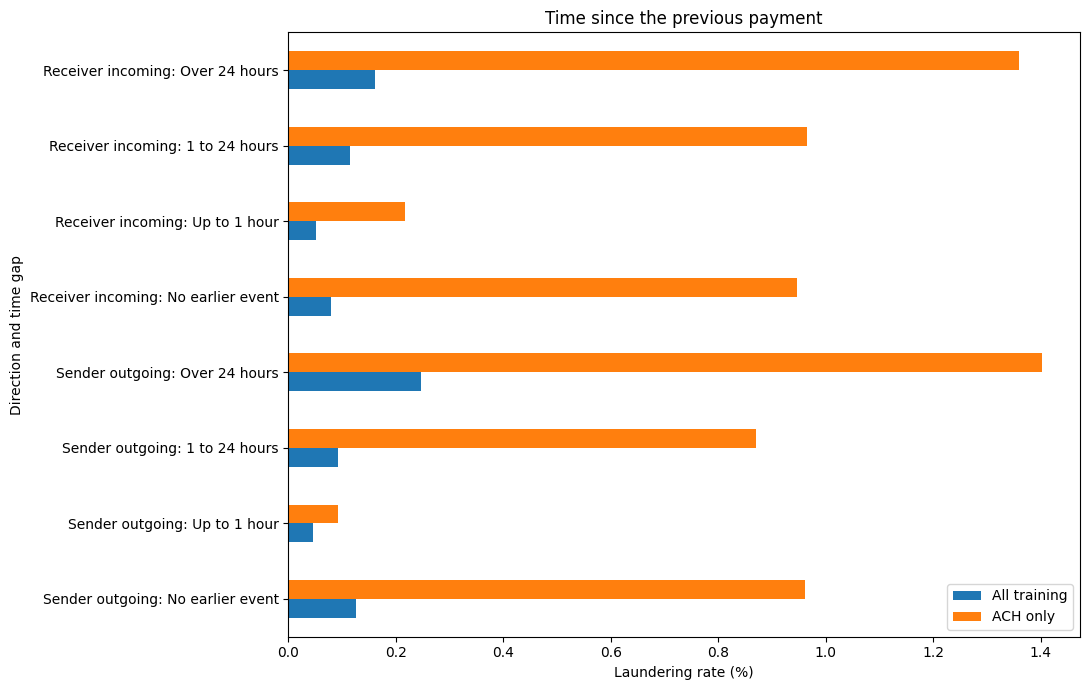

In [44]:
gap_order = ["No earlier event", "Up to 1 hour", "1 to 24 hours", "Over 24 hours"]
gap_summaries = {}
for column, name in [("sender_gap_hours", "Sender outgoing"), ("receiver_gap_hours", "Receiver incoming")]:
    gap_records = history.withColumn(
        "gap_band", F.when(F.col(column).isNull(), gap_order[0])
        .when(F.col(column) <= 1, gap_order[1])
        .when(F.col(column) <= 24, gap_order[2]).otherwise(gap_order[3])
    )
    gap_summaries[name] = history_summary(gap_records, "gap_band", gap_order)

gap_table = pd.concat(gap_summaries, names=["Direction", "Gap"])
display(gap_table.round(3))
plot_data = gap_table[["rate", "ach_rate"]].rename(columns={"rate": "All training", "ach_rate": "ACH only"})
plot_data.index = plot_data.index.map(": ".join)
plot_data.plot.barh(figsize=(11, 7))
plt.title("Time since the previous payment")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Direction and time gap")
plt.tight_layout()
plt.show()

Within ACH, sender gaps over 24 hours have a 1.403% rate, compared with 0.092% within one hour. Receiver rates are 1.360% and 0.217%. Longer gaps show the stronger association here, although incomplete history and the sparse final dates may contribute.

#### Amount relative to the receiver's recent average
Divide the current receipt by the receiver's average receipt during the preceding 24 hours in the same currency. Keep the earlier receipt count to show how much history supports the average.

No history and a zero average leave the ratio unavailable. The 24 hour window is an initial choice to validate.

,transactions,positives,ach_transactions,ach_positives,rate,ach_rate
group,,,,,,
No history,1004823,1321,104593,1181,0.131,1.129
At most 0.5,628147,372,91319,277,0.059,0.303
0.5 to 1,323897,222,40453,171,0.069,0.423
1 to 2,272251,239,37088,199,0.088,0.537
2 to 5,182540,192,19497,166,0.105,0.851
Above 5,252377,387,22424,346,0.153,1.543


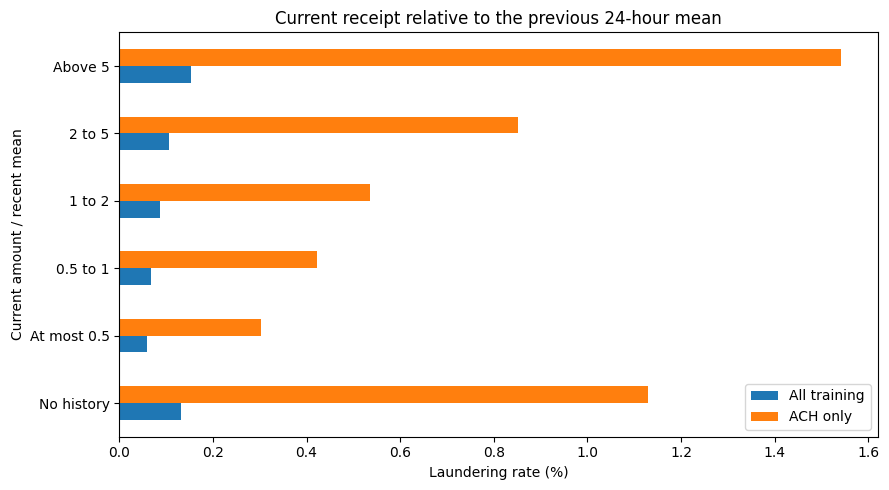

In [45]:
ratio_order = ["No history", "Zero mean", "At most 0.5", "0.5 to 1", "1 to 2", "2 to 5", "Above 5"]
ratio_records = history.withColumn(
    "ratio_band", F.when(F.col("receiver_previous_24h") == 0, ratio_order[0])
    .when(F.col("receiver_mean_24h") == 0, ratio_order[1])
    .when(F.col("receiver_amount_ratio") <= 0.5, ratio_order[2])
    .when(F.col("receiver_amount_ratio") <= 1, ratio_order[3])
    .when(F.col("receiver_amount_ratio") <= 2, ratio_order[4])
    .when(F.col("receiver_amount_ratio") <= 5, ratio_order[5]).otherwise(ratio_order[6])
)
ratio_summary = history_summary(ratio_records, "ratio_band", ratio_order)
display(ratio_summary.round(3))
plot_data = ratio_summary[["rate", "ach_rate"]].rename(columns={"rate": "All training", "ach_rate": "ACH only"})
plot_data.plot.barh(figsize=(9, 5))
plt.title("Current receipt relative to the previous 24-hour mean")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Current amount / recent mean")
plt.tight_layout()
plt.show()

Within ACH, receipts above five times the recent mean have a 1.543% rate, compared with 0.303% at or below half the mean. Across all formats, the rates are 0.153% and 0.059%.

A recent mean is available for only 51.66% of positives, so the model also needs a missing history flag. No zero means occur in this training data. The observed ratios are candidates to test, not fixed decision rules.

#### Account activity and counterparties
Historical counts measure repeated activity; distinct counterparties measure how widely that activity is spread. Incoming activity for the sender and outgoing activity for the receiver describe the other side of each account.

The box plots use all training positives and a seeded 1% sample of negatives. Values use log1p for readability; boxes show the middle half and omit outlier points. Full training counts are used in the rate tables.

In [46]:
count_columns = [
    "sender_prior_count",
    "receiver_prior_count",
    "sender_out_degree",
    "receiver_in_degree",
    "sender_incoming_prior_count",
    "receiver_outgoing_prior_count",
    "sender_previous_24h",
    "receiver_previous_24h",
    "sender_incoming_count_1h",
    "sender_incoming_count_24h",
    "receiver_outgoing_count_24h",
]
activity_columns = count_columns + [
    "sender_amount_ratio_24h", "receiver_amount_ratio",
    "sender_pass_through_1h", "sender_outgoing_to_incoming_ratio_24h",
]
activity_sample = history.sampleBy("is_laundering", {0: 0.01, 1: 1.0}, seed=SEED).select(
    "is_laundering", *activity_columns
).toPandas()
activity_sample["Label"] = activity_sample.is_laundering.map({0: "Normal", 1: "Laundering"})
display(activity_sample.groupby("Label").size().rename("Plot sample rows"))

def activity_boxplot(columns, title):
    plot_data = activity_sample[["Label"] + columns].copy()
    plot_data[columns] = np.log1p(plot_data[columns])
    plot_data = plot_data.melt(id_vars="Label", var_name="Feature", value_name="Value")
    plot_data["Feature"] = plot_data.Feature.str.replace("_", " ")
    plt.figure(figsize=(11, 6))
    sns.boxplot(data=plot_data, x="Value", y="Feature", hue="Label", showfliers=False)
    plt.title(title)
    plt.xlabel("log(1 + value)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

Label
Laundering     2733
Normal        26743
Name: Plot sample rows, dtype: int64

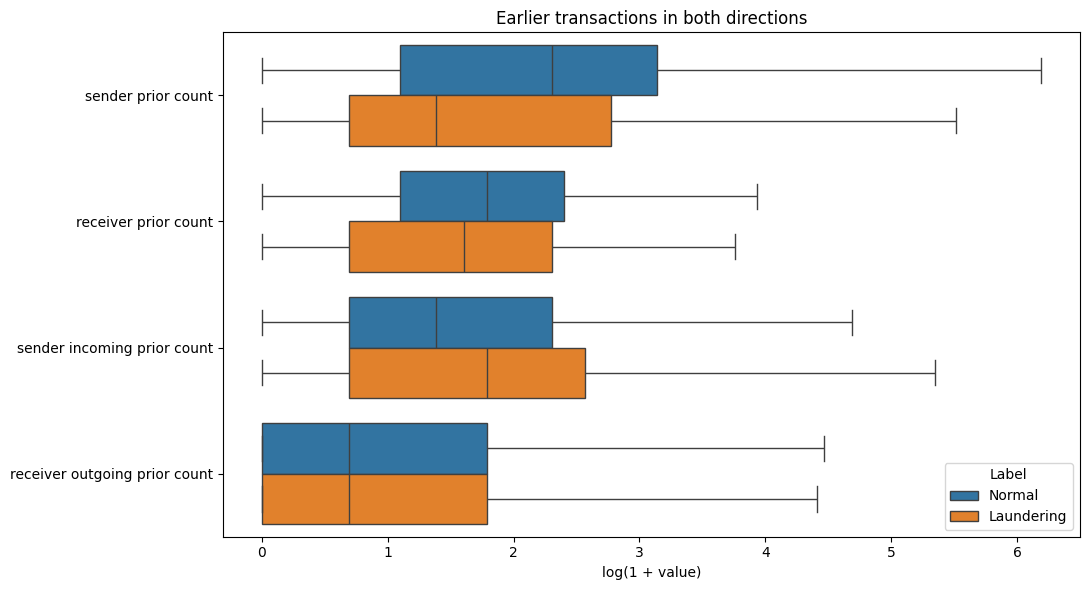

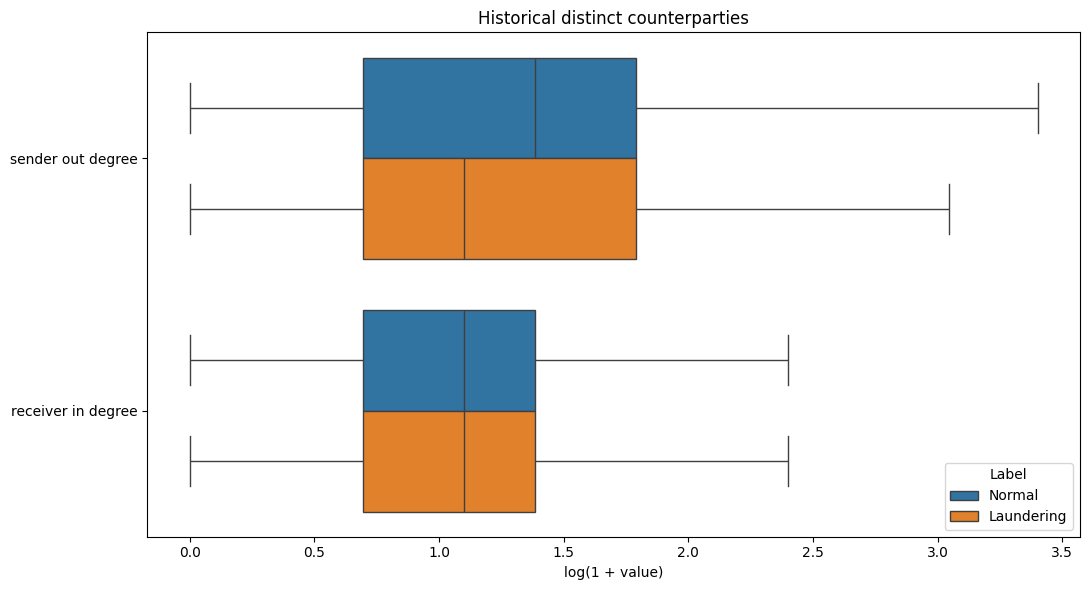

In [47]:
activity_boxplot([
    "sender_prior_count", "receiver_prior_count",
    "sender_incoming_prior_count", "receiver_outgoing_prior_count",
], "Earlier transactions in both directions")
activity_boxplot([
    "sender_out_degree", "receiver_in_degree",
], "Historical distinct counterparties")

Payments to receivers with 5 to 19 earlier senders have a 0.528% laundering rate, with 362 positives among 68,531 records. The rate is 0.093% for receivers with 1 to 4 earlier senders. Distinct counterparties may add information beyond transaction counts, but a larger count does not consistently mean a higher rate.

#### Recent transaction windows
Sender incoming activity uses both 1 hour and 24 hour counts. Receiver outgoing activity uses 24 hours. Amount counts use the current currency; the opposite direction counts cover all currencies.

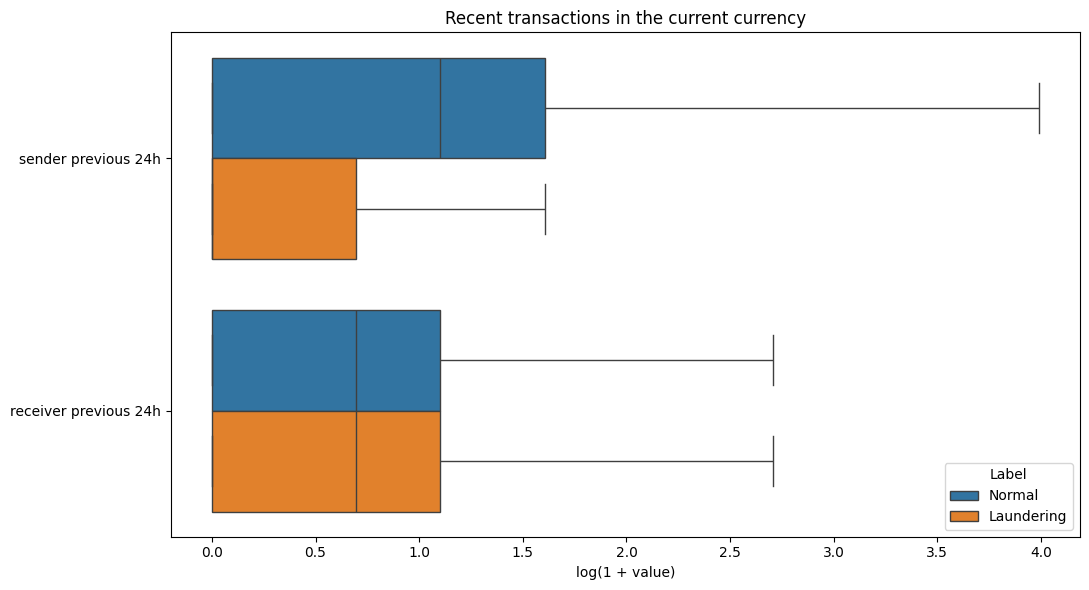

transactions  positives   rate
Feature                       Group                                     
sender_prior_count            None              385263        484  0.126
                              1 to 4            566058       1013  0.179
                              5 to 19           971241        643  0.066
                              20 or more        741473        593  0.080
receiver_prior_count          None              352901        281  0.080
                              1 to 4            827445       1184  0.143
                              5 to 19          1376836       1157  0.084
                              20 or more        106853        111  0.104
sender_out_degree             None              385263        484  0.126
                              1 to 4           1450662       1492  0.103
                              5 to 19           589562        403  0.068
                              20 or more        238548        354  0.148
receiver_in_degree            None              352901        281  0.080
                              1 to 4           2237112       2085  0.093
                              5 to 19            68531        362  0.528
                              20 or more          5491          5  0.091
sender_incoming_prior_count   None              603172        353  0.059
                              1 to 4            866601       1008  0.116
                              5 to 19           959096       1009  0.105
                              20 or more        235166        363  0.154
receiver_outgoing_prior_count None              830012        693  0.083
                              1 to 4           1131036       1298  0.115
                              5 to 19           552259        503  0.091
                              20 or more        150728        239  0.159
sender_previous_24h           None              783797       1844  0.235
                              1 to 4           1243518        478  0.038
                              5 to 19           399378         58  0.015
                              20 or more        237342        353  0.149
receiver_previous_24h         None             1004823       1321  0.131
                              1 to 4           1570202       1275  0.081
                              5 to 19            84267        132  0.157
                              20 or more          4743          5  0.105
sender_incoming_count_1h      None             2480402       2558  0.103
                              1 to 4            145063        100  0.069
                              5 to 19            38392         75  0.195
                              20 or more           178          0  0.000
sender_incoming_count_24h     None             1352937       1511  0.112
                              1 to 4           1174194       1024  0.087
                              5 to 19            77138         96  0.124
                              20 or more         59766        102  0.171
receiver_outgoing_count_24h   None             1704779       2009  0.118
                              1 to 4            823788        599  0.073
                              5 to 19           133752        125  0.093
                              20 or more          1716          0  0.000

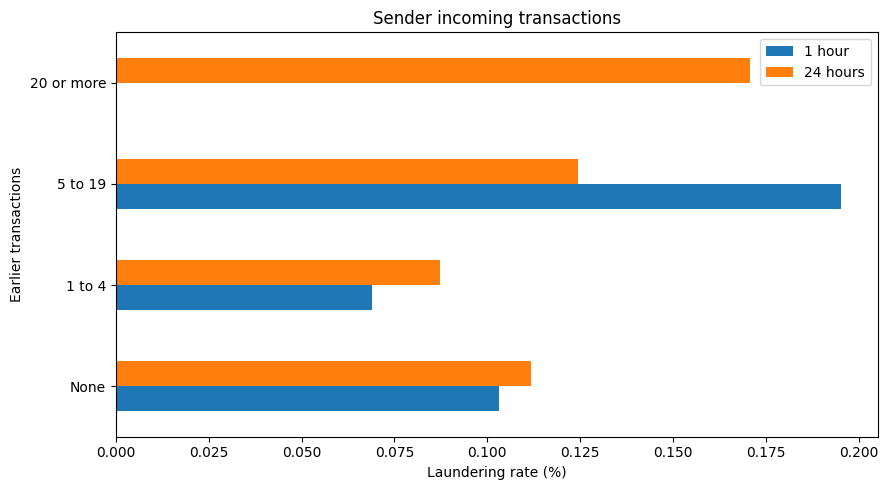

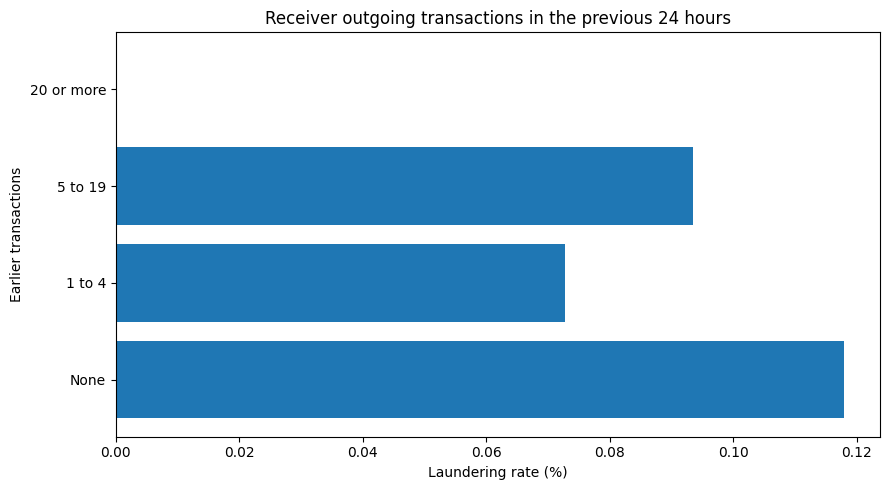

In [48]:
activity_boxplot(["sender_previous_24h", "receiver_previous_24h"], "Recent transactions in the current currency")

count_order = ["None", "1 to 4", "5 to 19", "20 or more"]
count_tables = {}
for column in count_columns:
    records = history.withColumn("band", F.when(F.col(column) == 0, count_order[0])
        .when(F.col(column) < 5, count_order[1]).when(F.col(column) < 20, count_order[2]).otherwise(count_order[3]))
    count_tables[column] = history_summary(records, "band", count_order)
count_table = pd.concat(count_tables, names=["Feature", "Group"])
display(count_table[["transactions", "positives", "rate"]].round(3))

plot_data = pd.DataFrame({
    "1 hour": count_tables["sender_incoming_count_1h"]["rate"],
    "24 hours": count_tables["sender_incoming_count_24h"]["rate"],
})
plot_data.plot.barh(figsize=(9, 5))
plt.title("Sender incoming transactions")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Earlier transactions")
plt.tight_layout()
plt.show()

plot_data = count_tables["receiver_outgoing_count_24h"]
plt.figure(figsize=(9, 5))
plt.barh(plot_data.index, plot_data["rate"])
plt.title("Receiver outgoing transactions in the previous 24 hours")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Earlier transactions")
plt.tight_layout()
plt.show()

For 1,844 positives, the sender has no earlier payment in the preceding 24 hours in the same currency. This group contains 67.47% of positives but only 29.42% of training rows. Within ACH, its rate is 1.529%, compared with 0.322% for 1 to 4 recent payments. These counts use earlier training records only, so missing history does not establish that an account was inactive outside this sample.

#### Receiving before sending
The sender incoming gap measures time since money arrived at the sender. The receiver outgoing gap measures time since the recipient last sent money. These differ from the original sender outgoing and receiver incoming gaps.

transactions  positives   rate  \
Feature                     Gap                                                
sender_incoming_gap_hours   No earlier event        603172        353  0.059   
                            Up to 1 hour            183633        175  0.095   
                            1 to 24 hours          1127465       1047  0.093   
                            Over 24 hours           749765       1158  0.154   
receiver_outgoing_gap_hours No earlier event        830012        693  0.083   
                            Up to 1 hour            113424         60  0.053   
                            1 to 24 hours           845832        664  0.079   
                            Over 24 hours           874767       1316  0.150   

                                              ach_rate  
Feature                     Gap                         
sender_incoming_gap_hours   No earlier event     0.467  
                            Up to 1 hour         0.300  
                            1 to 24 hours        0.718  
                            Over 24 hours        1.092  
receiver_outgoing_gap_hours No earlier event     0.694  
                            Up to 1 hour         0.210  
                            1 to 24 hours        0.569  
                            Over 24 hours        1.040

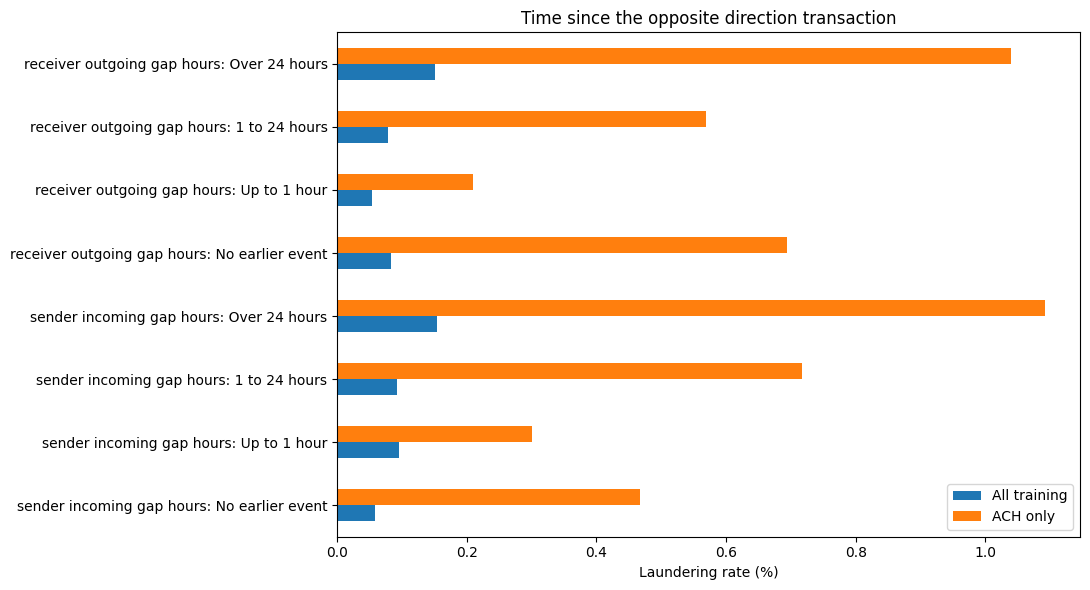

In [49]:
opposite_gap_tables = {}
for column in ["sender_incoming_gap_hours", "receiver_outgoing_gap_hours"]:
    records = history.withColumn("gap_band", F.when(F.col(column).isNull(), gap_order[0])
        .when(F.col(column) <= 1, gap_order[1]).when(F.col(column) <= 24, gap_order[2]).otherwise(gap_order[3]))
    opposite_gap_tables[column] = history_summary(records, "gap_band", gap_order)
opposite_gap_table = pd.concat(opposite_gap_tables, names=["Feature", "Gap"])
display(opposite_gap_table[["transactions", "positives", "rate", "ach_rate"]].round(3))
plot_data = opposite_gap_table[["rate", "ach_rate"]].rename(columns={"rate": "All training", "ach_rate": "ACH only"})
plot_data.index = plot_data.index.map(lambda row: row[0].replace("_", " ") + ": " + row[1])
plot_data.plot.barh(figsize=(11, 6))
plt.title("Time since the opposite direction transaction")
plt.xlabel("Laundering rate (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

Within ACH, sender incoming gaps over 24 hours have a 1.092% rate, with 985 positives, compared with 0.300% and 68 positives within one hour. Receiver outgoing gaps show the same direction: 1.040% versus 0.210%. The observed pattern does not support treating every quick receipt followed by a payment as suspicious.

#### Unusual sender amounts
Compare the current payment with the sender's previous 24 hour average in the payment currency. The sender count shows how much history supports the average.

,transactions,positives,ach_transactions,ach_positives,rate,ach_rate
group,,,,,,
No history,783797,1844,118472,1811,0.235,1.529
At most 0.5,979550,504,101178,166,0.051,0.164
0.5 to 1,250270,74,28378,69,0.030,0.243
1 to 2,223362,79,23658,76,0.035,0.321
2 to 5,180729,82,17903,79,0.045,0.441
Above 5,246327,150,25785,139,0.061,0.539


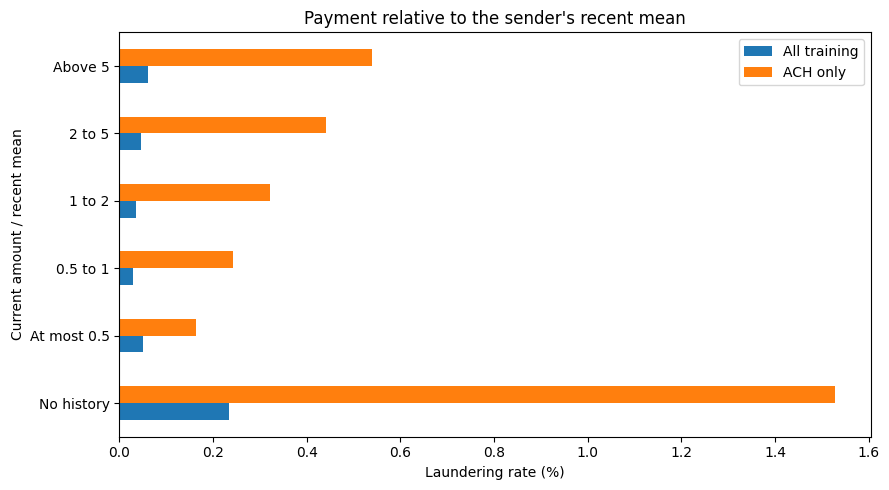

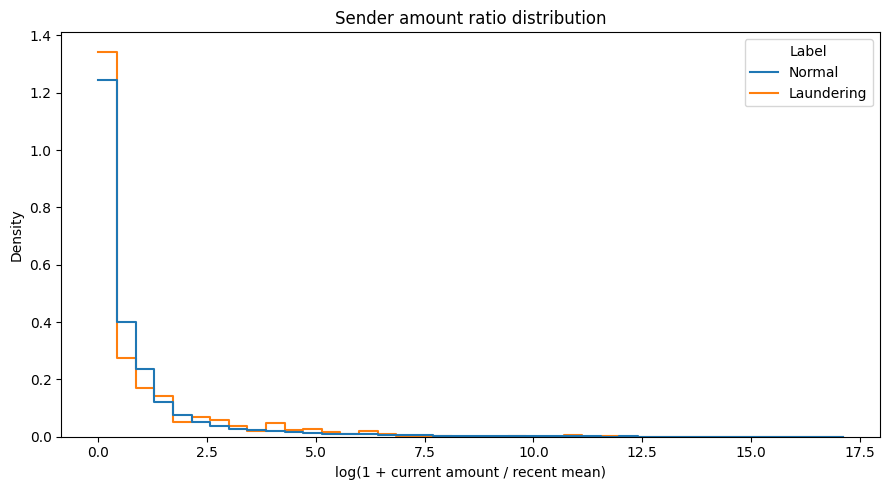

In [50]:
sender_ratio_records = history.withColumn("ratio_band",
    F.when(F.col("sender_previous_24h") == 0, ratio_order[0])
    .when(F.col("sender_mean_24h") == 0, ratio_order[1])
    .when(F.col("sender_amount_ratio_24h") <= 0.5, ratio_order[2])
    .when(F.col("sender_amount_ratio_24h") <= 1, ratio_order[3])
    .when(F.col("sender_amount_ratio_24h") <= 2, ratio_order[4])
    .when(F.col("sender_amount_ratio_24h") <= 5, ratio_order[5]).otherwise(ratio_order[6]))
sender_ratio_summary = history_summary(sender_ratio_records, "ratio_band", ratio_order)
display(sender_ratio_summary.round(3))
sender_ratio_summary[["rate", "ach_rate"]].rename(columns={"rate": "All training", "ach_rate": "ACH only"}).plot.barh(figsize=(9, 5))
plt.title("Payment relative to the sender's recent mean")
plt.xlabel("Laundering rate (%)")
plt.ylabel("Current amount / recent mean")
plt.tight_layout()
plt.show()

plot_data = activity_sample.dropna(subset=["sender_amount_ratio_24h"]).copy()
plot_data["Log ratio"] = np.log1p(plot_data.sender_amount_ratio_24h)
plt.figure(figsize=(9, 5))
sns.histplot(data=plot_data, x="Log ratio", hue="Label", bins=40, stat="density", common_norm=False, element="step", fill=False)
plt.title("Sender amount ratio distribution")
plt.xlabel("log(1 + current amount / recent mean)")
plt.tight_layout()
plt.show()

Within ACH, payments above five times the sender's recent mean have a 0.539% rate, with 139 positives. Payments at or below half the mean have a 0.164% rate, with 166 positives. Relative amount shows some separation when history is available, but the sender mean is available for only 32.53% of positives.

#### Money received and sent onward
Pass through similarity compares the current payment with receipts in the preceding hour. The outgoing to incoming ratio compares only earlier totals over 24 hours. Both use the payment currency. Missing history is separate from a valid zero.

transactions  positives  \
Feature                               Group                                  
sender_pass_through_1h                Unavailable       2493582       2599   
                                      0 to 0.5           141514        105   
                                      0.5 to 0.9          24514         22   
                                      Above 0.9            4425          7   
sender_outgoing_to_incoming_ratio_24h Unavailable       1383737       1989   
                                      At most 0.5        467835        345   
                                      0.5 to 2           237531        122   
                                      Above 2            574932        277   

                                                   ach_transactions  \
Feature                               Group                           
sender_pass_through_1h                Unavailable            303324   
                                      0 to 0.5                10156   
                                      0.5 to 0.9               1604   
                                      Above 0.9                 290   
sender_outgoing_to_incoming_ratio_24h Unavailable            166393   
                                      At most 0.5             57273   
                                      0.5 to 2                28215   
                                      Above 2                 63493   

                                                   ach_positives   rate  \
Feature                               Group                               
sender_pass_through_1h                Unavailable           2313  0.104   
                                      0 to 0.5                16  0.074   
                                      0.5 to 0.9               6  0.090   
                                      Above 0.9                5  0.158   
sender_outgoing_to_incoming_ratio_24h Unavailable           1772  0.144   
                                      At most 0.5            337  0.074   
                                      0.5 to 2               121  0.051   
                                      Above 2                110  0.048   

                                                   ach_rate  
Feature                               Group                  
sender_pass_through_1h                Unavailable     0.763  
                                      0 to 0.5        0.158  
                                      0.5 to 0.9      0.374  
                                      Above 0.9       1.724  
sender_outgoing_to_incoming_ratio_24h Unavailable     1.065  
                                      At most 0.5     0.588  
                                      0.5 to 2        0.429  
                                      Above 2         0.173

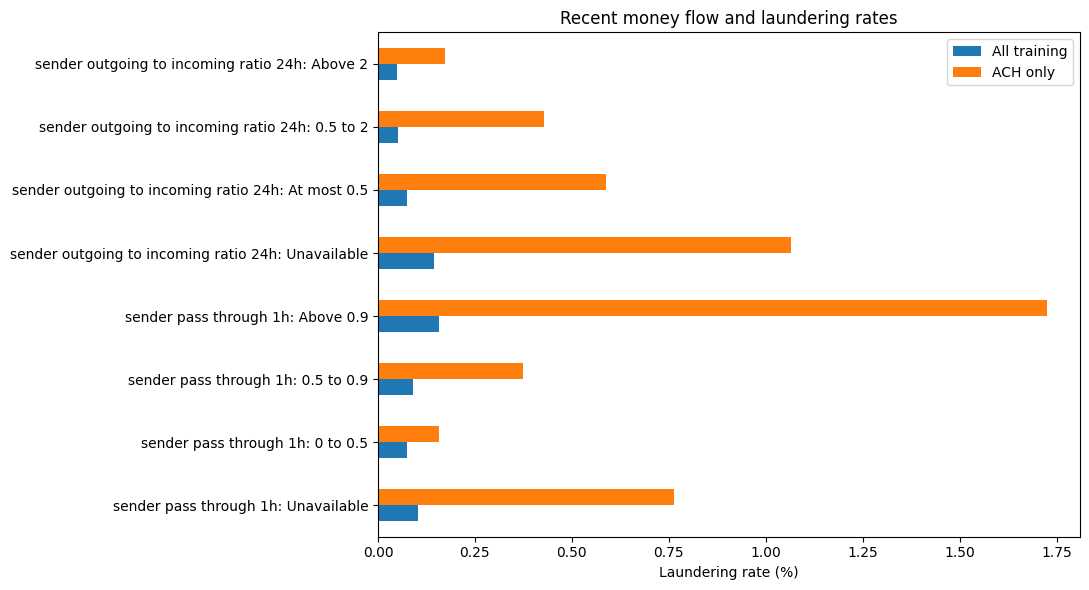

In [51]:
flow_tables = {}
flow_bands = {
    "sender_pass_through_1h": ["Unavailable", "0 to 0.5", "0.5 to 0.9", "Above 0.9"],
    "sender_outgoing_to_incoming_ratio_24h": ["Unavailable", "At most 0.5", "0.5 to 2", "Above 2"],
}
for column, order in flow_bands.items():
    upper = 0.9 if column == "sender_pass_through_1h" else 2.0
    records = history.withColumn("band", F.when(F.col(column).isNull(), order[0])
        .when(F.col(column) <= 0.5, order[1]).when(F.col(column) <= upper, order[2]).otherwise(order[3]))
    flow_tables[column] = history_summary(records, "band", order)
flow_table = pd.concat(flow_tables, names=["Feature", "Group"])
display(flow_table.round(3))
plot_data = flow_table[["rate", "ach_rate"]].rename(columns={"rate": "All training", "ach_rate": "ACH only"})
plot_data.index = plot_data.index.map(lambda row: row[0].replace("_", " ") + ": " + row[1])
plot_data.plot.barh(figsize=(11, 6))
plt.title("Recent money flow and laundering rates")
plt.xlabel("Laundering rate (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

Pass through similarity above 0.9 contains 7 positives among 4,425 records, a rate of 0.158%. The measure is unavailable for 95.10% of positives. The 24 hour flow ratio is also unavailable for 72.78% of positives, and ratios above 2 have a lower rate than ratios at or below 0.5. These features need model validation; they do not justify a fixed forwarding rule.

#### Reverse payments and self transfers
Reverse payments identify a previous payment in the other direction between different accounts. Self transfer requires both the bank and account number to match.

transactions  positives  ach_transactions  \
Feature                   Group                                              
has_prior_reverse_payment No          2662637       2620            314174   
                          Yes            1398        113              1200   
self_transfer             No          2354101       2726            278051   
                          Yes          309934          7             37323   

                                 ach_positives   rate  ach_rate  
Feature                   Group                                  
has_prior_reverse_payment No              2230  0.098     0.710  
                          Yes              110  8.083     9.167  
self_transfer             No              2333  0.116     0.839  
                          Yes                7  0.002     0.019

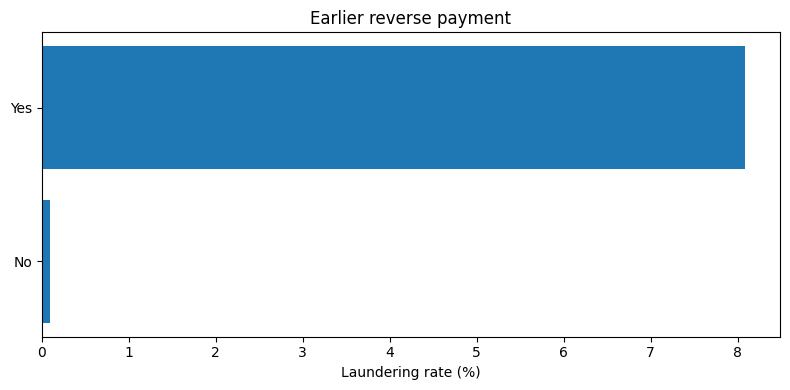

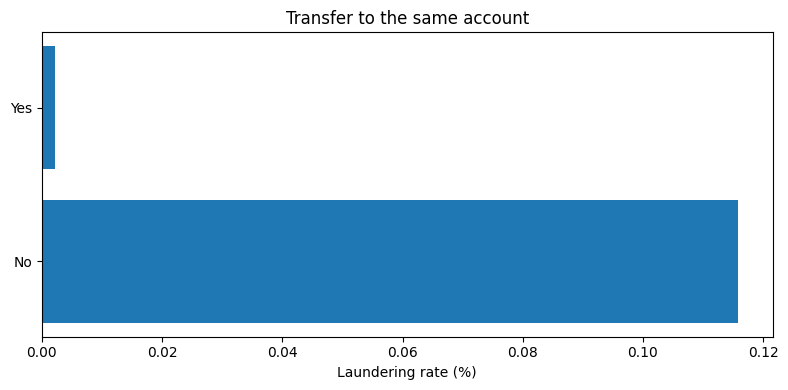

In [52]:
relationship_tables = {}
for column in ["has_prior_reverse_payment", "self_transfer"]:
    records = history.withColumn("group", F.when(F.col(column) == 1, "Yes").otherwise("No"))
    relationship_tables[column] = history_summary(records, "group", ["No", "Yes"])
relationship_table = pd.concat(relationship_tables, names=["Feature", "Group"])
display(relationship_table.round(3))
for column, title in [
    ("has_prior_reverse_payment", "Earlier reverse payment"),
    ("self_transfer", "Transfer to the same account"),
]:
    plot_data = relationship_tables[column]
    plt.figure(figsize=(8, 4))
    plt.barh(plot_data.index, plot_data["rate"])
    plt.title(title)
    plt.xlabel("Laundering rate (%)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()


Prior reverse payments stand out: 113 of 1,398 records are positive, a rate of 8.083%, compared with 0.098% without a reverse payment. They still cover only 4.13% of positives. Self transfers contain 7 positives among 309,934 records, so their low rate should not become an automatic safe payment rule.

#### Bank categories
Keep the 20 most frequent banks in each role and group the rest as Other. Fit these groups using training transaction counts only. Bank IDs are categories, not numeric measurements. Original IDs still identify accounts for all history calculations.

This limits the number of encoded inputs and avoids ranking tiny banks by unstable label rates. The comparison describes banks seen in the synthetic training data; it does not establish real bank risk.

,Role,Distinct training banks
0,from_bank,27187
1,to_bank,12892


,bank_group,transactions,positives,rate
9,Other,2037797,2055,0.101
17,70,236743,354,0.150
8,10,42796,26,0.061
4,12,42017,40,0.095
0,1,32875,24,0.073
13,220,27687,10,0.036
19,15,27505,25,0.091
5,20,21540,36,0.167
6,3,20247,8,0.040
11,7,16124,3,0.019


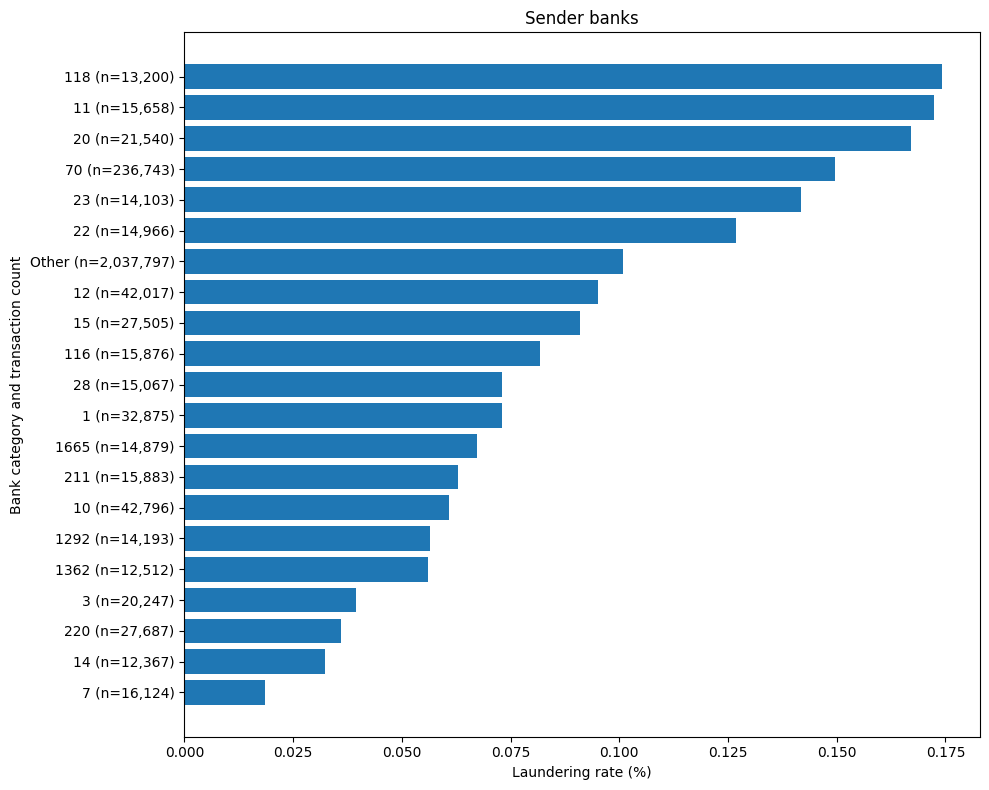

,bank_group,transactions,positives,rate
7,Other,2423474,2393,0.099
8,10,22334,23,0.103
3,12,22026,58,0.263
20,15,20297,21,0.103
14,220,16214,18,0.111
0,1,15839,27,0.170
5,3,13548,7,0.052
9,7,12041,9,0.075
4,20,11629,30,0.258
16,28,11083,13,0.117


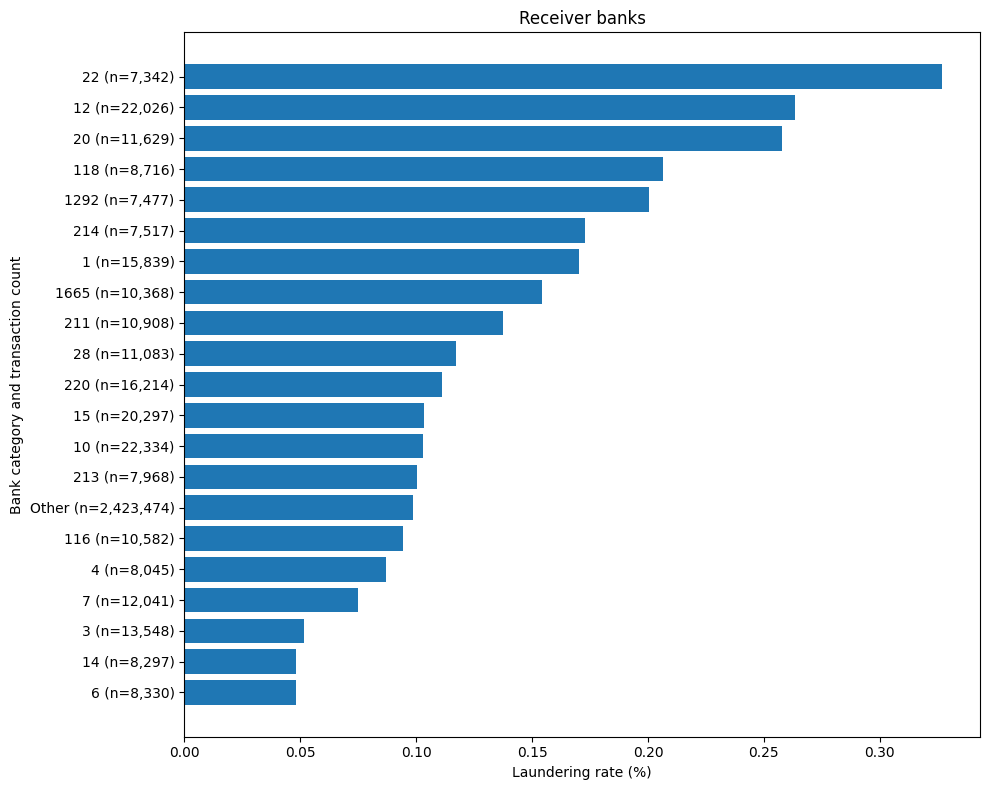

In [53]:
bank_categories = {}
bank_tables = {}
bank_counts = []
for column in ["from_bank", "to_bank"]:
    counts = history.groupBy(column).count()
    bank_counts.append((column, counts.count()))
    bank_categories[column] = [row[column] for row in counts.orderBy(F.desc("count"), column).limit(20).collect()]
    grouped = history.withColumn("bank_group", F.when(F.col(column).isin(bank_categories[column]), F.col(column).cast("string")).otherwise("Other"))
    table = grouped.groupBy("bank_group").agg(F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives")).toPandas()
    table["rate"] = 100 * table.positives / table.transactions
    bank_tables[column] = table.sort_values("rate")
display(pd.DataFrame(bank_counts, columns=["Role", "Distinct training banks"]))
for column, table in bank_tables.items():
    display(table.sort_values("transactions", ascending=False).round(3))
    labels = table.bank_group + " (n=" + table.transactions.map(lambda value: f"{value:,}") + ")"
    plt.figure(figsize=(10, 8))
    plt.barh(labels, table.rate)
    plt.title("Sender banks" if column == "from_bank" else "Receiver banks")
    plt.xlabel("Laundering rate (%)")
    plt.ylabel("Bank category and transaction count")
    plt.tight_layout()
    plt.show()

There are 27,187 sender banks and 12,892 receiver banks in training. Grouping less frequent banks as Other avoids thousands of sparse inputs. Other contains 76.49% of sender records and 90.97% of receiver records.

#### Numeric feature correlations
Use all training records to check the numeric candidates, including missing history indicators. Categories, source IDs and the target are excluded. An absolute Pearson correlation above 0.80 is the cutoff for removing overlapping inputs. This reduces linear redundancy; it does not establish whether prediction improves.

Use the same derived values and missing history indicators in the correlation review and modelling tables.

In [6]:
def prepare_features(data):
    data = data.withColumn("log_amount_paid", F.log1p("amount_paid")).withColumn("hour", F.hour("timestamp"))
    data = data.withColumn("weekday", (F.dayofweek("timestamp") + 5) % 7)
    data = data.withColumn("same_bank", (F.col("from_bank") == F.col("to_bank")).cast("int"))
    data = data.withColumn("currency_changed", (F.col("payment_currency") != F.col("receiving_currency")).cast("int"))
    history_columns = {
        "sender_gap_hours": "sender_history_missing",
        "receiver_gap_hours": "receiver_history_missing",
        "receiver_amount_ratio": "receiver_ratio_missing",
        "sender_amount_ratio_24h": "sender_ratio_missing",
        "sender_incoming_gap_hours": "sender_incoming_history_missing",
        "receiver_outgoing_gap_hours": "receiver_outgoing_history_missing",
        "sender_pass_through_1h": "sender_pass_through_missing",
        "sender_outgoing_to_incoming_ratio_24h": "sender_flow_ratio_missing",
    }
    for column, indicator in history_columns.items():
        data = data.withColumn(indicator, F.col(column).isNull().cast("int"))
    return data.fillna(0, subset=list(history_columns))

analysis_features = prepare_features(history)
candidate_numeric_columns = [
    "log_amount_paid",
    "hour",
    "same_bank",
    "currency_changed",
    "prior_pair_count",
    "sender_gap_hours",
    "receiver_gap_hours",
    "receiver_previous_24h",
    "receiver_amount_ratio",
    "sender_history_missing",
    "receiver_history_missing",
    "receiver_ratio_missing",
    "sender_prior_count",
    "receiver_prior_count",
    "sender_out_degree",
    "receiver_in_degree",
    "sender_previous_24h",
    "sender_amount_ratio_24h",
    "sender_incoming_gap_hours",
    "receiver_outgoing_gap_hours",
    "sender_pass_through_1h",
    "has_prior_reverse_payment",
    "sender_incoming_count_1h",
    "sender_incoming_count_24h",
    "receiver_outgoing_count_24h",
    "sender_incoming_prior_count",
    "receiver_outgoing_prior_count",
    "sender_outgoing_to_incoming_ratio_24h",
    "self_transfer",
    "sender_ratio_missing",
    "sender_incoming_history_missing",
    "receiver_outgoing_history_missing",
    "sender_pass_through_missing",
    "sender_flow_ratio_missing",
]
variation = analysis_features.agg(*[F.stddev_pop(column).alias(column) for column in candidate_numeric_columns]).first().asDict()
constant_columns = [column for column, value in variation.items() if value == 0 or value is None]
print("Constant numeric inputs:", constant_columns or "None")

Constant numeric inputs: None


In [7]:
numeric_data = VectorAssembler(inputCols=candidate_numeric_columns, outputCol="numeric_features").transform(analysis_features)
correlation_values = Correlation.corr(numeric_data, "numeric_features", "pearson").first()[0].toArray()
correlation_matrix = pd.DataFrame(correlation_values, index=candidate_numeric_columns, columns=candidate_numeric_columns)

correlation_cutoff = 0.80
removal_review = pd.DataFrame([
    ("sender_prior_count", "sender_previous_24h", "Keep recent sender activity instead of the overlapping historical total."),
    ("sender_incoming_prior_count", "sender_previous_24h", "Keep recent sender activity; incoming counts over 1 and 24 hours remain."),
    ("sender_out_degree", "sender_previous_24h", "Keep recent transaction count instead of the overlapping recipient count."),
    ("receiver_outgoing_prior_count", "receiver_outgoing_count_24h", "Keep recent outgoing activity instead of the historical total."),
    ("receiver_in_degree", "receiver_outgoing_count_24h", "Keep recent incoming and outgoing counts instead of sender diversity."),
    ("same_bank", "self_transfer", "Keep the more specific same-account condition."),
], columns=["Removed feature", "Retained feature", "Reason"])
removal_review["Correlation"] = [
    correlation_matrix.loc[removed, retained]
    for removed, retained in zip(removal_review["Removed feature"], removal_review["Retained feature"])
]
removal_review = removal_review[removal_review["Correlation"].abs() > correlation_cutoff]
removed_features = removal_review["Removed feature"].tolist()
with pd.option_context("display.max_colwidth", None):
    display(removal_review[["Removed feature", "Retained feature", "Correlation", "Reason"]].round(3))

,Removed feature,Retained feature,Correlation,Reason
0,sender_prior_count,sender_previous_24h,0.858,Keep recent sender activity instead of the overlapping historical total.
1,sender_incoming_prior_count,sender_previous_24h,0.848,Keep recent sender activity; incoming counts over 1 and 24 hours remain.
2,sender_out_degree,sender_previous_24h,0.951,Keep recent transaction count instead of the overlapping recipient count.
3,receiver_outgoing_prior_count,receiver_outgoing_count_24h,0.808,Keep recent outgoing activity instead of the historical total.
4,receiver_in_degree,receiver_outgoing_count_24h,0.816,Keep recent incoming and outgoing counts instead of sender diversity.
5,same_bank,self_transfer,0.914,Keep the more specific same-account condition.


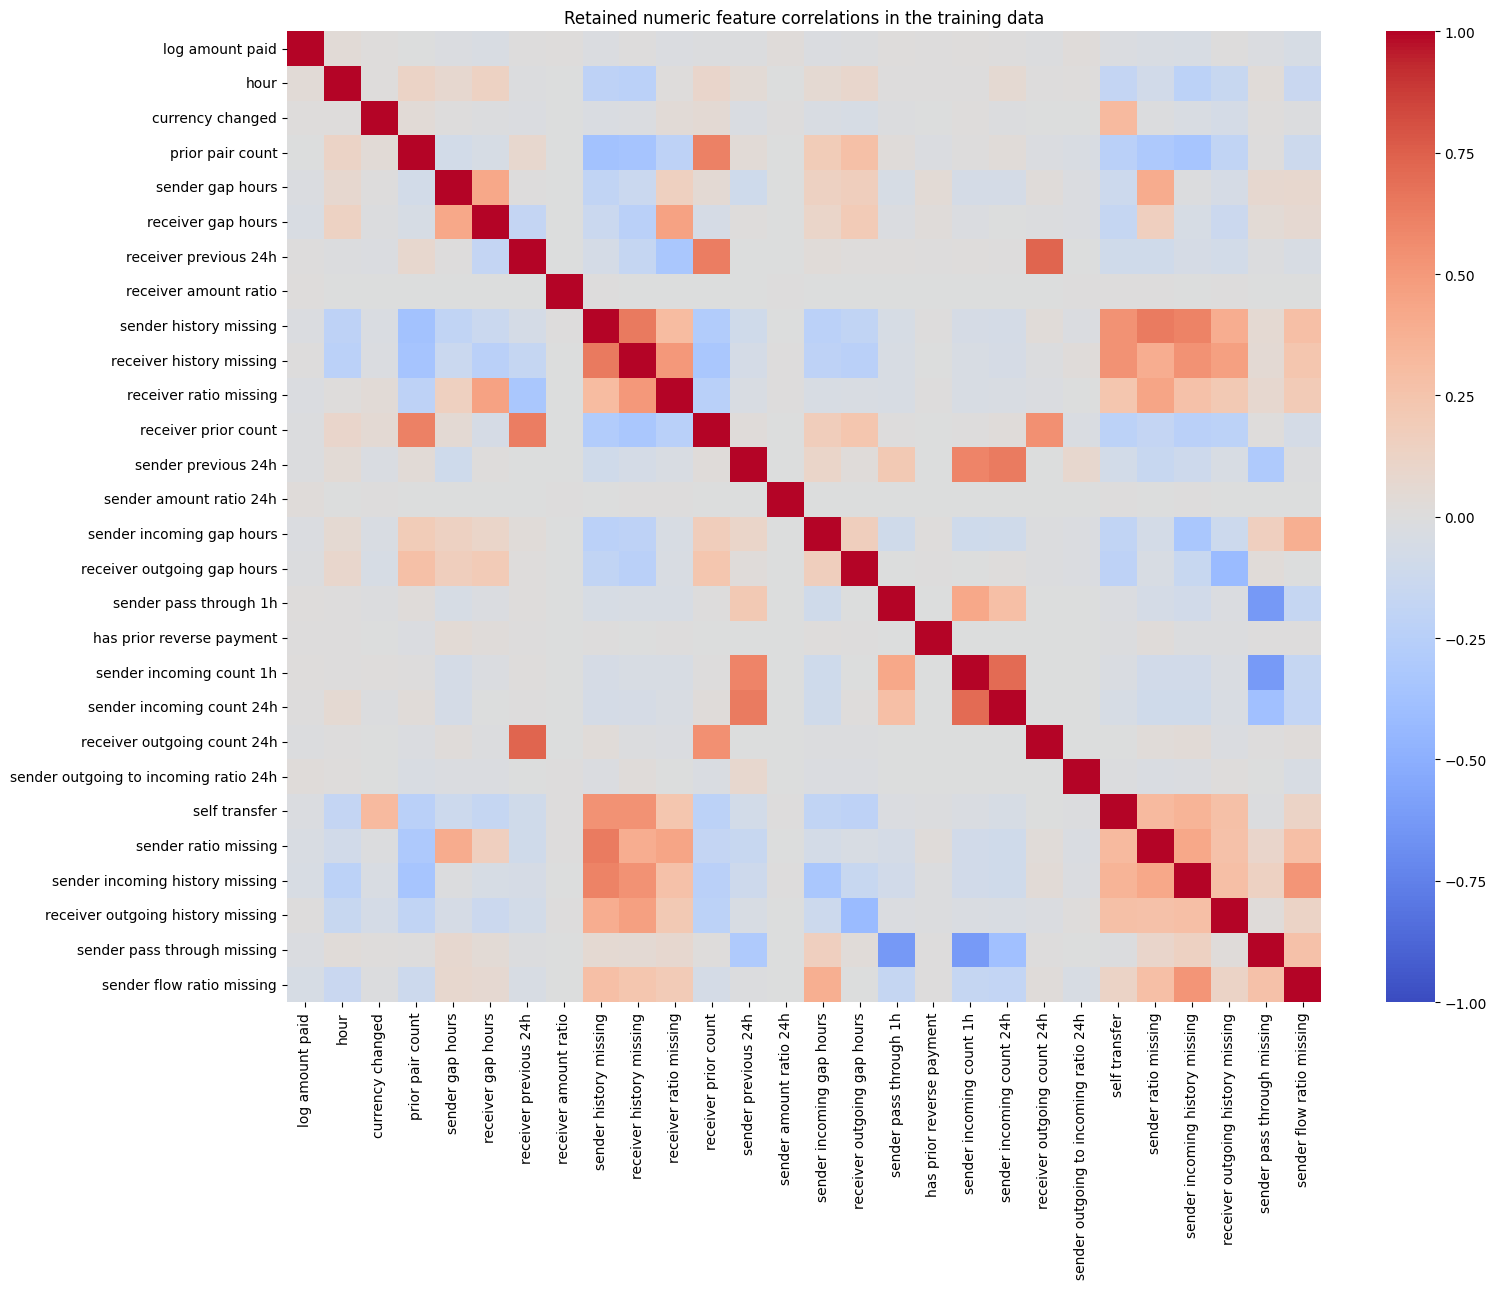

,Feature 1,Feature 2,Correlation
0,receiver_previous_24h,receiver_outgoing_count_24h,0.733
1,sender_incoming_count_1h,sender_incoming_count_24h,0.706
2,sender_history_missing,receiver_history_missing,0.648
3,sender_previous_24h,sender_incoming_count_24h,0.639
4,sender_history_missing,sender_ratio_missing,0.637
5,receiver_previous_24h,receiver_prior_count,0.630
6,sender_pass_through_1h,sender_pass_through_missing,-0.627
7,sender_incoming_count_1h,sender_pass_through_missing,-0.621
8,prior_pair_count,receiver_prior_count,0.616
9,sender_history_missing,sender_incoming_history_missing,0.606


In [8]:
retained_numeric_columns = [column for column in candidate_numeric_columns if column not in removed_features]
retained_correlations = correlation_matrix.loc[retained_numeric_columns, retained_numeric_columns]
labels = [column.replace("_", " ") for column in retained_numeric_columns]
plt.figure(figsize=(16, 13))
sns.heatmap(retained_correlations, cmap="coolwarm", vmin=-1, vmax=1, center=0, xticklabels=labels, yticklabels=labels)
plt.title("Retained numeric feature correlations in the training data")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

upper_triangle = np.triu(np.ones(retained_correlations.shape), k=1).astype(bool)
strongest_pairs = retained_correlations.where(upper_triangle).stack().sort_values(key=abs, ascending=False).head(12)
display(strongest_pairs.rename_axis(["Feature 1", "Feature 2"]).reset_index(name="Correlation").round(3))

The strongest remaining numeric correlation is 0.733, below the 0.80 cutoff. Sender incoming counts over 1 and 24 hours correlate at 0.706, so both remain. Recent activity counts are retained over overlapping historical totals and counterparty counts. The six removals leave 34 inputs, including all eight missing history indicators. Their effect on model performance still needs validation.

### A4. Build the feature pipeline
#### Feature list
Use these 34 inputs after the correlation review. The source record ID and target remain outside the feature vector.

In [9]:
feature_columns = [
    "payment_format",
    "payment_currency",
    "receiving_currency",
    "log_amount_paid",
    "hour",
    "weekday",
    "currency_changed",
    "prior_pair_count",
    "sender_gap_hours",
    "receiver_gap_hours",
    "receiver_previous_24h",
    "receiver_amount_ratio",
    "sender_history_missing",
    "receiver_history_missing",
    "receiver_ratio_missing",
    "receiver_prior_count",
    "sender_previous_24h",
    "sender_amount_ratio_24h",
    "sender_incoming_gap_hours",
    "receiver_outgoing_gap_hours",
    "sender_pass_through_1h",
    "has_prior_reverse_payment",
    "sender_incoming_count_1h",
    "sender_incoming_count_24h",
    "receiver_outgoing_count_24h",
    "sender_outgoing_to_incoming_ratio_24h",
    "self_transfer",
    "from_bank",
    "to_bank",
    "sender_ratio_missing",
    "sender_incoming_history_missing",
    "receiver_outgoing_history_missing",
    "sender_pass_through_missing",
    "sender_flow_ratio_missing",
]
categorical_columns = ["payment_format", "payment_currency", "receiving_currency", "weekday", "from_bank", "to_bank"]
numeric_columns = [column for column in feature_columns if column not in categorical_columns]
display(pd.DataFrame({
    "Feature": feature_columns,
    "Type": ["Category" if column in categorical_columns else "Numeric" for column in feature_columns],
}))

,Feature,Type
0,payment_format,Category
1,payment_currency,Category
2,receiving_currency,Category
3,log_amount_paid,Numeric
4,hour,Numeric
5,weekday,Category
6,currency_changed,Numeric
7,prior_pair_count,Numeric
8,sender_gap_hours,Numeric
9,receiver_gap_hours,Numeric


#### Final modelling tables
All three tables use the same selected columns. Validation and test transactions use only earlier training history.

In [10]:
for name, partition in [("training", "train"), ("validation", "validation"), ("test", "test")]:
    records = prepare_features(feature_history.filter(F.col("model_partition") == partition))
    records.select("source_record_id", *feature_columns, "is_laundering").write.mode("overwrite").parquet(str(DATA_DIR / f"model_{name}.parquet"))
model_train_df = spark.read.parquet(str(DATA_DIR / "model_training.parquet"))
model_validation_df = spark.read.parquet(str(DATA_DIR / "model_validation.parquet"))
model_test_df = spark.read.parquet(str(DATA_DIR / "model_test.parquet"))
with pd.option_context("display.max_columns", None):
    display(model_train_df.orderBy("source_record_id").limit(5).toPandas())

,source_record_id,payment_format,payment_currency,receiving_currency,log_amount_paid,hour,weekday,currency_changed,prior_pair_count,sender_gap_hours,receiver_gap_hours,receiver_previous_24h,receiver_amount_ratio,sender_history_missing,receiver_history_missing,receiver_ratio_missing,receiver_prior_count,sender_previous_24h,sender_amount_ratio_24h,sender_incoming_gap_hours,receiver_outgoing_gap_hours,sender_pass_through_1h,has_prior_reverse_payment,sender_incoming_count_1h,sender_incoming_count_24h,receiver_outgoing_count_24h,sender_outgoing_to_incoming_ratio_24h,self_transfer,from_bank,to_bank,sender_ratio_missing,sender_incoming_history_missing,receiver_outgoing_history_missing,sender_pass_through_missing,sender_flow_ratio_missing,is_laundering
0,2,Cheque,US Dollar,US Dollar,0.009950,0,3,0,0,0.0,0.15,1,0.000071,1,0,0,1,0,0.0,0.0,0.0,0.0,0,0,0,0,0.0,0,3208,1,1,1,1,1,1,0
1,5,Reinvestment,US Dollar,US Dollar,10.510095,0,3,0,0,0.0,0.00,0,0.000000,1,1,1,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0.0,1,10,10,1,1,1,1,1,0
2,7,Reinvestment,US Dollar,US Dollar,2.725235,0,3,0,0,0.0,0.00,0,0.000000,1,1,1,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0.0,1,1,1,1,1,1,1,1,0
3,8,Reinvestment,US Dollar,US Dollar,2.554122,0,3,0,0,0.0,0.00,0,0.000000,1,1,1,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0.0,1,1,1,1,1,1,1,1,0
4,13,Credit Card,US Dollar,US Dollar,1.611436,0,3,0,0,0.0,0.00,0,0.000000,1,1,1,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0.0,0,1,245335,1,1,1,1,1,0


#### Fit the preprocessing pipeline
Fit category encoding on training data and apply the same transformation to validation and test data. Rare and unseen banks use Other; other unseen categories have a separate indicator.

In [11]:
bank_expressions = []
for column, values in bank_categories.items():
    choices = ", ".join(str(value) for value in values)
    bank_expressions.append(f"CASE WHEN {column} IN ({choices}) THEN CAST({column} AS STRING) ELSE 'Other' END AS {column}_group")
bank_grouping = SQLTransformer(statement="SELECT *, " + ", ".join(bank_expressions) + " FROM __THIS__")
indexer_inputs = [column + "_group" if column in bank_categories else column for column in categorical_columns]
index_columns = [column + "_index" for column in categorical_columns]
encoded_columns = [column + "_encoded" for column in categorical_columns]
indexer = StringIndexer(inputCols=indexer_inputs, outputCols=index_columns, handleInvalid="keep")
encoder = OneHotEncoder(inputCols=index_columns, outputCols=encoded_columns, dropLast=False)
assembler = VectorAssembler(inputCols=numeric_columns + encoded_columns, outputCol="features")
preprocessing_model = Pipeline(stages=[bank_grouping, indexer, encoder, assembler]).fit(model_train_df)
preprocessing_model.write().overwrite().save(str(DATA_DIR / "preprocessing_model"))

prepared_train_df = preprocessing_model.transform(model_train_df)
prepared_validation_df = preprocessing_model.transform(model_validation_df)
prepared_test_df = preprocessing_model.transform(model_test_df)
vector_size = prepared_train_df.schema["features"].metadata["ml_attr"]["num_attrs"]
display(pd.DataFrame({"Rows": [model_train_df.count(), model_validation_df.count(), model_test_df.count()],
    "Input columns": len(feature_columns), "Vector values": vector_size}, index=["Training", "Validation", "Test"]))

,Rows,Input columns,Vector values
Training,2664035,34,120
Validation,572159,34,120
Test,572457,34,120


#### Transform without the label
The pipeline uses only input columns. The same transformation applies when the laundering label is absent.

In [12]:
unlabelled_sample = model_validation_df.orderBy("source_record_id").limit(5).drop("is_laundering")
preprocessing_model.transform(unlabelled_sample).select("source_record_id", "features").show(5, truncate=100)

+----------------+----------------------------------------------------------------------------------------------------+
|source_record_id|                                                                                            features|
+----------------+----------------------------------------------------------------------------------------------------+
|               6|(120,[0,8,9,10,22,23,24,25,26,27,32,36,52,68,80,103],[8.726390342215547,1.0,1.0,1.0,1.0,1.0,1.0,1...|
|              12|(120,[0,8,9,10,22,23,24,25,26,27,32,36,52,68,80,103],[2.339880877737743,1.0,1.0,1.0,1.0,1.0,1.0,1...|
|              28|(120,[0,8,9,10,22,23,24,25,26,27,32,36,52,68,76,98],[6.619566411464762,1.0,1.0,1.0,1.0,1.0,1.0,1....|
|              31|(120,[0,8,9,10,22,23,24,25,26,27,32,36,52,68,78,99],[6.864252611332742,1.0,1.0,1.0,1.0,1.0,1.0,1....|
|              38|(120,[0,8,9,10,22,23,24,25,26,27,32,36,52,68,76,98],[12.166059802725023,1.0,1.0,1.0,1.0,1.0,1.0,1...|
+----------------+----------------------

A5 uses these 34 inputs and the fitted preprocessing pipeline for every classifier.

### A5. Train and compare models

#### Compare four classifiers
Logistic regression provides a linear baseline. Decision tree, random forest and XGBoost can capture nonlinear relationships. All four use the same 34 selected A4 inputs and training records. The fitted preprocessing pipeline produces 120 vector values.

Compare two settings per model. Select settings and thresholds by validation F1, with PR AUC as the tie break between settings. F1 balances precision and recall; PR AUC measures ranking quality for the rare positive class. Spark's PR AUC is the area under its precision recall curve, rather than average precision.

Earlier test results were already inspected. Further choices use validation only, but the repeated test comparison is a benchmark rather than an untouched independent estimate. Streaming records remain excluded from development.

In [1]:
from time import perf_counter
from pyspark.ml.classification import (
    LogisticRegression, DecisionTreeClassifier, RandomForestClassifier
)
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import OneHotEncoderModel
from pyspark.ml.functions import vector_to_array
from xgboost.spark import SparkXGBClassifier
import logging

logging.getLogger("XGBoost-PySpark").setLevel(logging.WARNING)

class_weights = {
    label: training_count / (2 * count)
    for label, count in training_labels.items()
}
weight = F.when(F.col("is_laundering") == 1, class_weights[1]).otherwise(class_weights[0])
training = preprocessing_model.transform(model_train_df).select(
    "source_record_id", "features", "is_laundering"
).withColumn("class_weight", weight).repartition(
    2, "source_record_id"
).sortWithinPartitions("source_record_id").cache()
validation = preprocessing_model.transform(model_validation_df).select(
    "source_record_id", "features", "is_laundering"
).cache()

print(f"Training: {training.count():,}; validation: {validation.count():,}")
display(pd.DataFrame({"Rows": training_labels, "Weight": class_weights}).rename_axis("Label").round(4))

Training: 2,664,035; validation: 572,159


,Rows,Weight
Label,,
1,2733,487.3829
0,2661302,0.5005


Logistic regression, decision tree and random forest use weights that give each class equal total training weight. XGBoost compares no extra weighting with a moderate positive weight. Every training row is retained; validation and test keep their original class proportions. These weighted scores are not calibrated laundering probabilities.

In [2]:
pr_evaluator = BinaryClassificationEvaluator(
    labelCol="is_laundering", rawPredictionCol="score", metricName="areaUnderPR", numBins=0
)
roc_evaluator = BinaryClassificationEvaluator(
    labelCol="is_laundering", rawPredictionCol="score", metricName="areaUnderROC", numBins=0
)

def score_model(model, data):
    return model.transform(data).select(
        "source_record_id", "is_laundering",
        vector_to_array("probability")[1].alias("score")
    )

#### Select thresholds using validation data
Include all tied scores together. If F1 ties, use the higher threshold to reduce alerts. The chosen rule is score greater than or equal to the threshold.

In [3]:
def threshold_curve(scores):
    ranked = scores.groupBy("score").agg(
        F.count("*").alias("Rows"), F.sum("is_laundering").alias("Positives")
    )
    ranking = Window.orderBy(F.desc("score")).rowsBetween(Window.unboundedPreceding, 0)
    positives = model_counts["validation"]["positive"]
    return (ranked
        .withColumn("Alerts", F.sum("Rows").over(ranking))
        .withColumn("TP", F.sum("Positives").over(ranking))
        .withColumn("Precision", F.col("TP") / F.col("Alerts"))
        .withColumn("Recall", F.col("TP") / positives)
        .withColumn("F1", 2 * F.col("TP") / (F.col("Alerts") + positives))
        .withColumnRenamed("score", "Threshold")
    )

In [4]:
models = {}
settings = {}
validation_scores = {}
trial_rows = []

def fit_trial(name, run, estimator):
    start = perf_counter()
    models[run] = estimator.fit(training)
    seconds = perf_counter() - start
    settings[run] = estimator
    validation_scores[run] = score_model(models[run], validation).cache()
    best = threshold_curve(validation_scores[run]).orderBy(F.desc("F1"), F.desc("Threshold")).first()
    trial_rows.append({
        "Run": run, "Model": name, "Inputs": len(feature_columns),
        "PR AUC": pr_evaluator.evaluate(validation_scores[run]),
        "Precision": best.Precision, "Recall": best.Recall, "F1": best.F1,
        "Threshold": best.Threshold, "Training seconds": seconds,
        "Iterations": models[run].summary.totalIterations if name == "Logistic regression" else None
    })
    print(f"{run}: validation F1 {best.F1:.4f}")

#### Logistic regression
Compare regularisation strengths of 0.01 and 0.1.

In [5]:
for regularisation in [0.01, 0.1]:
    estimator = LogisticRegression(
        labelCol="is_laundering", weightCol="class_weight",
        regParam=regularisation, elasticNetParam=0.0,
        maxIter=100, tol=1e-6, standardization=True
    )
    fit_trial("Logistic regression", f"LR regularisation {regularisation}", estimator)

LR regularisation 0.01: validation F1 0.1592


LR regularisation 0.1: validation F1 0.1148


#### Decision tree
Compare depths of 6 and 10, with at least 20 training records per leaf.

In [6]:
for depth in [6, 10]:
    estimator = DecisionTreeClassifier(
        labelCol="is_laundering", weightCol="class_weight",
        maxDepth=depth, minInstancesPerNode=20, impurity="gini", seed=SEED
    )
    fit_trial("Decision tree", f"DT depth {depth}", estimator)

DT depth 6: validation F1 0.0471


DT depth 10: validation F1 0.2638


#### Random forest
Compare depths of 6 and 10 with 40 trees each and at least 20 training records per leaf.

In [7]:
for depth in [6, 10]:
    estimator = RandomForestClassifier(
        labelCol="is_laundering", weightCol="class_weight",
        numTrees=40, maxDepth=depth, minInstancesPerNode=20,
        featureSubsetStrategy="sqrt", seed=SEED
    )
    fit_trial("Random forest", f"RF depth {depth}", estimator)

RF depth 6: validation F1 0.1264


RF depth 10: validation F1 0.1998


#### XGBoost
Use 300 trees of depth 7 and a learning rate of 0.1. Compare a positive weight of 1 with the square root of the training class ratio.

In [8]:
for positive_weight in [1.0, np.sqrt(training_labels[0] / training_labels[1])]:
    estimator = SparkXGBClassifier(
        label_col="is_laundering", num_workers=2, device="cpu",
        n_estimators=300, max_depth=7, learning_rate=0.1,
        min_child_weight=3, subsample=0.85, colsample_bytree=0.85,
        tree_method="hist", random_state=SEED, scale_pos_weight=float(positive_weight),
        eval_metric="logloss", verbose=False
    )
    fit_trial("XGBoost", f"XGBoost positive weight {positive_weight:.2f}", estimator)

trial_results = pd.DataFrame(trial_rows).set_index("Run")
display(trial_results.drop(columns="Iterations").round(4))

[22:27:33] Task 1 got rank 1
[22:27:33] Task 0 got rank 0


XGBoost positive weight 1.00: validation F1 0.5444


[22:28:24] Task 0 got rank 0
[22:28:24] Task 1 got rank 1


XGBoost positive weight 31.21: validation F1 0.5329


,Model,Inputs,PR AUC,Precision,Recall,F1,Threshold,Training seconds
Run,,,,,,,,
LR regularisation 0.01,Logistic regression,34,0.0669,0.1168,0.2500,0.1592,0.9572,5.0422
LR regularisation 0.1,Logistic regression,34,0.0481,0.0858,0.1736,0.1148,0.9015,2.9264
DT depth 6,Decision tree,34,0.2080,0.7368,0.0243,0.0471,0.9998,6.0166
DT depth 10,Decision tree,34,0.1992,0.2750,0.2535,0.2638,0.9971,7.0566
RF depth 6,Random forest,34,0.0533,0.1061,0.1562,0.1264,0.8966,50.9693
RF depth 10,Random forest,34,0.1104,0.1865,0.2153,0.1998,0.9508,99.2583
XGBoost positive weight 1.00,XGBoost,34,0.5041,0.7562,0.4253,0.5444,0.2882,49.3772
XGBoost positive weight 31.21,XGBoost,34,0.4943,0.7232,0.4219,0.5329,0.8147,47.7787


#### Compare validation results
Select one configuration per model using validation F1, then PR AUC. All four still use the same input columns. Accuracy is included for completeness, but predicting every row as normal already gives about 99.9% accuracy.

In [9]:
model_names = ["Logistic regression", "Decision tree", "Random forest", "XGBoost"]
selected_runs = {
    name: trial_results[trial_results["Model"] == name].sort_values(
        ["F1", "PR AUC"], ascending=False
    ).index[0]
    for name in model_names
}
thresholds = {name: float(trial_results.loc[run, "Threshold"]) for name, run in selected_runs.items()}
run_preprocessors = {run: preprocessing_model for run in selected_runs.values()}
validation_curves = {
    name: threshold_curve(validation_scores[run]).cache()
    for name, run in selected_runs.items()
}

for run, scores in validation_scores.items():
    if run not in selected_runs.values():
        scores.unpersist()

In [10]:
def evaluate_scores(scores, threshold):
    counts = scores.withColumn("prediction", (F.col("score") >= threshold).cast("int")).groupBy(
        "is_laundering", "prediction"
    ).count().collect()
    counts = {(row.is_laundering, row.prediction): row["count"] for row in counts}
    tn, fp = counts.get((0, 0), 0), counts.get((0, 1), 0)
    fn, tp = counts.get((1, 0), 0), counts.get((1, 1), 0)
    total = tn + fp + fn + tp
    return {
        "PR AUC": pr_evaluator.evaluate(scores), "ROC AUC": roc_evaluator.evaluate(scores),
        "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1),
        "F1": 2 * tp / max(2 * tp + fp + fn, 1), "Accuracy": (tp + tn) / total,
        "Alerts": tp + fp, "Alert rate": (tp + fp) / total,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

validation_results = pd.DataFrame({
    name: evaluate_scores(validation_scores[run], thresholds[name])
    for name, run in selected_runs.items()
}).T
validation_results.index.name = "Model"
display(validation_results.drop(columns=["TN", "FP", "FN", "TP"]).round(4))
display(pd.Series(thresholds, name="Selected threshold").round(6))

,PR AUC,ROC AUC,Precision,Recall,F1,Accuracy,Alerts,Alert rate
Model,,,,,,,,
Logistic regression,0.0669,0.9749,0.1168,0.2500,0.1592,0.9973,1233.0,0.0022
Decision tree,0.1992,0.9555,0.2750,0.2535,0.2638,0.9986,531.0,0.0009
Random forest,0.1104,0.9790,0.1865,0.2153,0.1998,0.9983,665.0,0.0012
XGBoost,0.5041,0.9825,0.7562,0.4253,0.5444,0.9993,324.0,0.0006


Logistic regression    0.957173
Decision tree          0.997149
Random forest          0.950794
XGBoost                0.288215
Name: Selected threshold, dtype: float64

#### Validation precision and recall
The horizontal line shows the validation proportion of laundering labels. Compare ranking quality alongside the alert counts and chosen threshold.

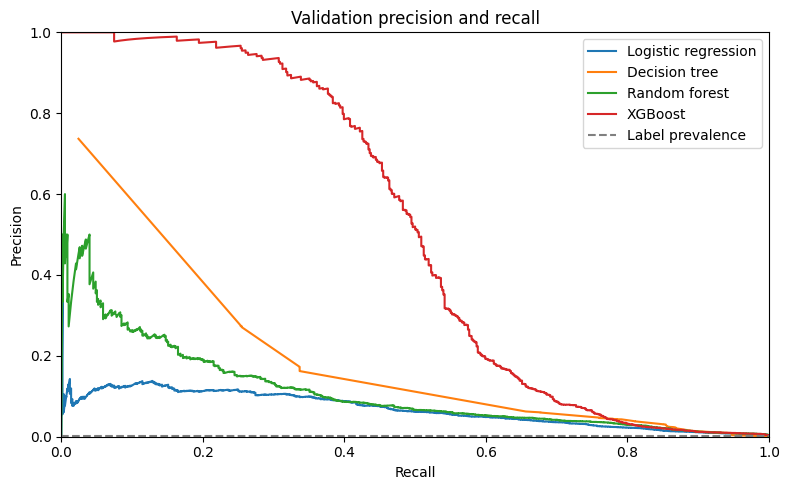

In [11]:
plt.figure(figsize=(8, 5))
for name, curve in validation_curves.items():
    plot_data = curve.orderBy(F.desc("Threshold")).select("Recall", "Precision").toPandas()
    plt.plot(plot_data["Recall"], plot_data["Precision"], label=name)
plt.axhline(model_counts["validation"]["positive"] / model_counts["validation"]["rows"],
            color="grey", linestyle="--", label="Label prevalence")
plt.title("Validation precision and recall")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

#### Validation confusion matrices
Rows show actual labels and columns show predicted labels. The upper right cell contains false alerts; the lower left contains missed laundering transactions.

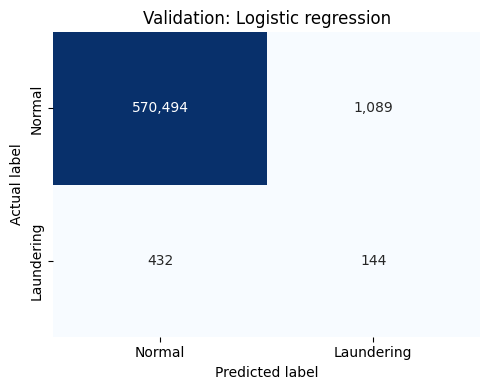

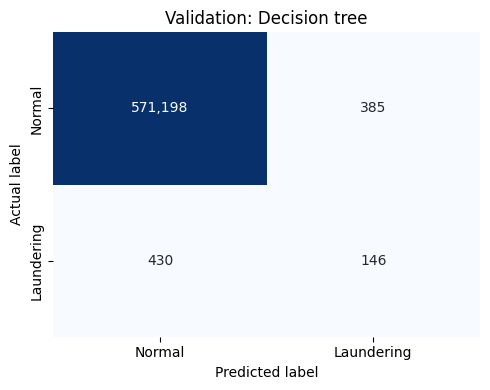

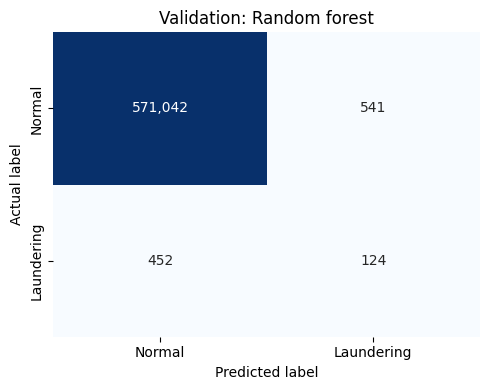

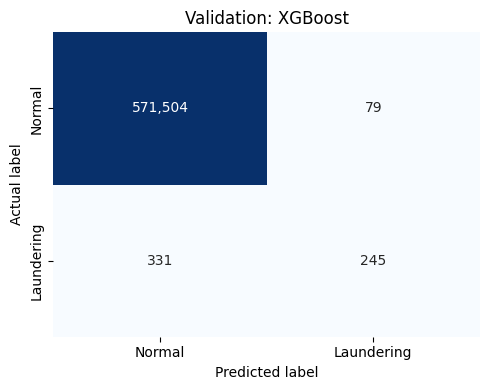

In [12]:
for name, row in validation_results.iterrows():
    matrix = np.array([[row["TN"], row["FP"]], [row["FN"], row["TP"]]], dtype=int)
    plt.figure(figsize=(5, 4))
    sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=["Normal", "Laundering"], yticklabels=["Normal", "Laundering"])
    plt.title(f"Validation: {name}")
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.tight_layout()
    plt.show()

#### Do bank categories help?
Repeat the selected XGBoost settings without the two bank categories. Compare these 32 inputs with all 34 selected inputs, using the same training records and fitted encoders. Each feature set receives its own validation threshold.

This checks the bank group at fixed model settings. It does not measure each feature independently or establish performance for unseen banks.

In [13]:
feature_sets = {
    "Without bank categories": [column for column in feature_columns if column not in ["from_bank", "to_bank"]]
}
best_xgb_run = selected_runs["XGBoost"]
ablation_models = {}
ablation_scores = {}
ablation_preprocessors = {}
ablation_rows = []

In [14]:
for name, columns in feature_sets.items():
    inputs = [column for column in numeric_columns if column in columns]
    inputs += [encoded for column, encoded in zip(categorical_columns, encoded_columns) if column in columns]
    preprocessor = PipelineModel(stages=preprocessing_model.stages[:-1] + [
        VectorAssembler(inputCols=inputs, outputCol="features")
    ])
    records = preprocessor.transform(model_train_df).select(
        "source_record_id", "features", "is_laundering"
    ).repartition(2, "source_record_id").sortWithinPartitions("source_record_id").cache()
    start = perf_counter()
    ablation_models[name] = settings[best_xgb_run].fit(records)
    seconds = perf_counter() - start
    ablation_preprocessors[name] = preprocessor
    ablation_scores[name] = score_model(
        ablation_models[name], preprocessor.transform(model_validation_df)
    ).cache()
    best = threshold_curve(ablation_scores[name]).orderBy(F.desc("F1"), F.desc("Threshold")).first()
    ablation_rows.append({
        "Feature set": name, "Inputs": len(columns), "PR AUC": pr_evaluator.evaluate(ablation_scores[name]),
        "Precision": best.Precision, "Recall": best.Recall, "F1": best.F1,
        "Threshold": best.Threshold, "Training seconds": seconds
    })
    records.unpersist()

ablation_rows.append({"Feature set": "All selected inputs", **trial_results.loc[
    best_xgb_run, ["Inputs", "PR AUC", "Precision", "Recall", "F1", "Threshold", "Training seconds"]
].to_dict()})
feature_comparison = pd.DataFrame(ablation_rows).set_index("Feature set")
display(feature_comparison.round(4))

[22:29:26] Task 1 got rank 1[22:29:26] Task 0 got rank 0



,Inputs,PR AUC,Precision,Recall,F1,Threshold,Training seconds
Feature set,,,,,,,
Without bank categories,32,0.4995,0.6870,0.4497,0.5435,0.2228,39.1433
All selected inputs,34,0.5041,0.7562,0.4253,0.5444,0.2882,49.3772


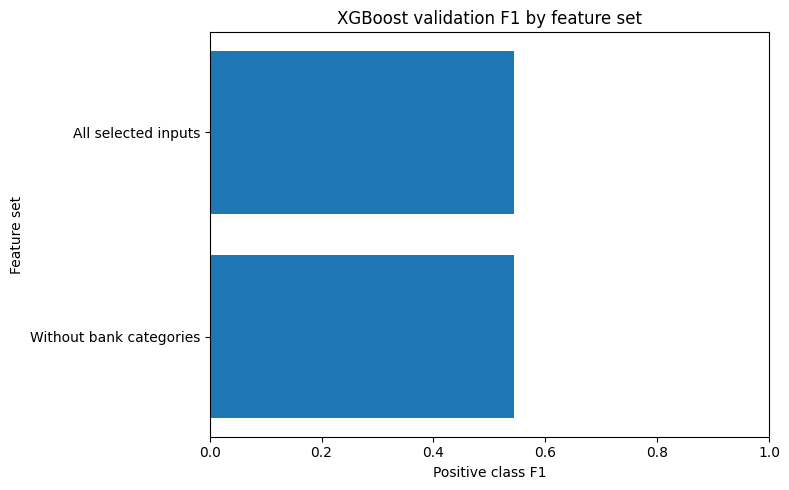

In [15]:
plot_data = feature_comparison.sort_values("F1")
plt.figure(figsize=(8, 5))
plt.barh(plot_data.index, plot_data["F1"])
plt.title("XGBoost validation F1 by feature set")
plt.xlabel("Positive class F1")
plt.ylabel("Feature set")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

At the selected XGBoost settings, validation F1 is 0.5435 without bank categories and 0.5444 with all 34 inputs, a change of +0.0009. PR AUC changes from 0.4995 to 0.5041. The bank categories describe common training banks and an Other group. This comparison does not establish performance for unseen banks.

#### Feature importance
Sum the importance of encoded categories back to their original column. Decision tree and forest importance measure reductions in impurity; XGBoost importance uses normalised total split gain. Compare rankings within each model rather than comparing the numerical scales between models.

These are training importances, not causal effects or proof of validation benefit. Correlated inputs can share importance. The feature group comparison above provides a separate validation check.

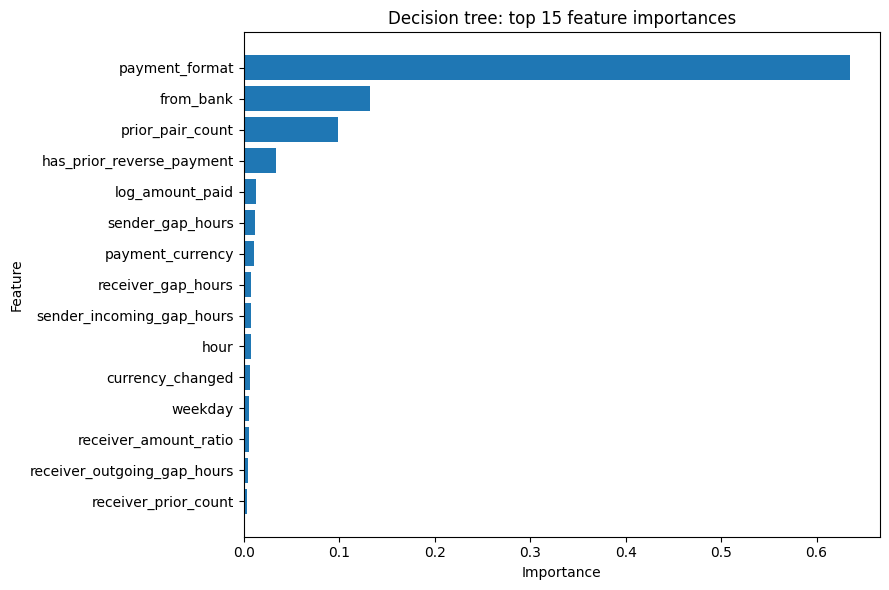

Feature
payment_format               0.6347
from_bank                    0.1325
prior_pair_count             0.0992
has_prior_reverse_payment    0.0338
log_amount_paid              0.0126
sender_gap_hours             0.0119
payment_currency             0.0106
receiver_gap_hours           0.0079
sender_incoming_gap_hours    0.0077
hour                         0.0072
Name: Importance, dtype: float64

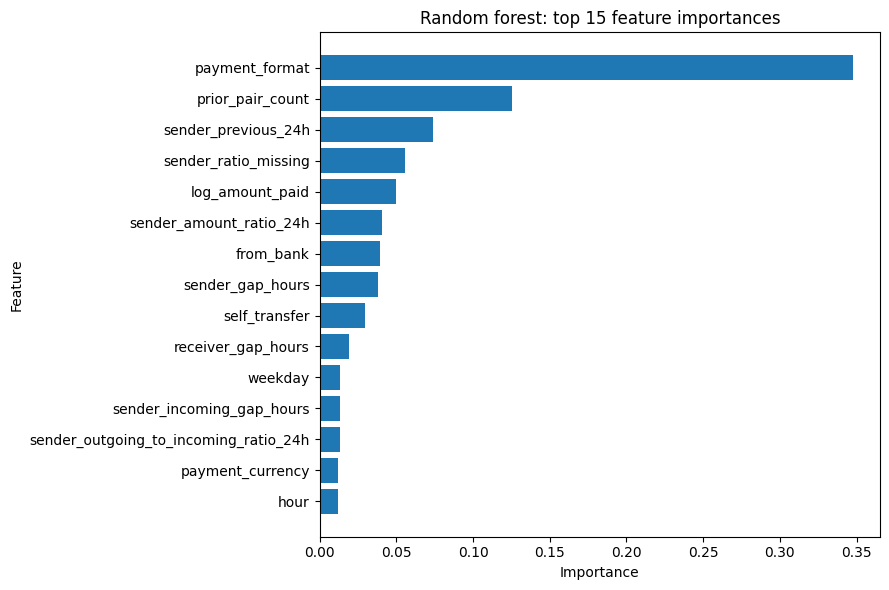

Feature
payment_format             0.3479
prior_pair_count           0.1256
sender_previous_24h        0.0740
sender_ratio_missing       0.0560
log_amount_paid            0.0499
sender_amount_ratio_24h    0.0404
from_bank                  0.0394
sender_gap_hours           0.0378
self_transfer              0.0298
receiver_gap_hours         0.0192
Name: Importance, dtype: float64

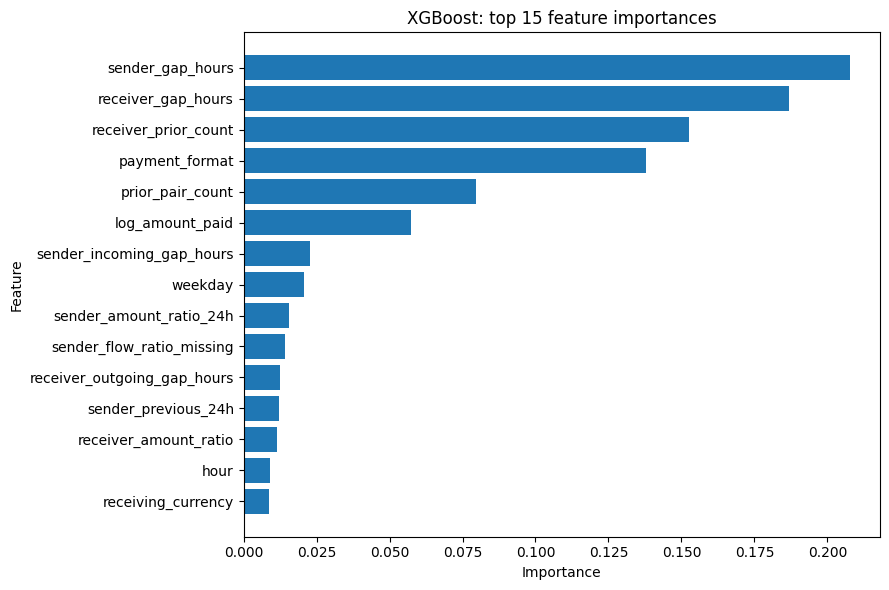

Feature
sender_gap_hours             0.2077
receiver_gap_hours           0.1869
receiver_prior_count         0.1527
payment_format               0.1380
prior_pair_count             0.0798
log_amount_paid              0.0572
sender_incoming_gap_hours    0.0227
weekday                      0.0205
sender_amount_ratio_24h      0.0157
sender_flow_ratio_missing    0.0142
Name: Importance, dtype: float64

In [17]:
encoder_model = next(stage for stage in preprocessing_model.stages if isinstance(stage, OneHotEncoderModel))
feature_names = numeric_columns + [
    column for column, size in zip(categorical_columns, encoder_model.categorySizes)
    for _ in range(size)
]
feature_importances = {}
for name in ["Decision tree", "Random forest", "XGBoost"]:
    fitted = models[selected_runs[name]]
    if name == "XGBoost":
        gain = fitted.get_booster().get_score(importance_type="total_gain")
        values = np.array([gain.get(f"f{i}", 0) for i in range(len(feature_names))])
        values = values / max(values.sum(), 1e-12)
    else:
        values = fitted.featureImportances.toArray()
    feature_importances[name] = pd.DataFrame({
        "Feature": feature_names, "Importance": values
    }).groupby("Feature")["Importance"].sum().sort_values(ascending=False)

    plot_data = feature_importances[name].head(15).sort_values()
    plt.figure(figsize=(9, 6))
    plt.barh(plot_data.index, plot_data.values)
    plt.title(f"{name}: top 15 feature importances")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
    display(feature_importances[name].head(10).round(4))

The largest shares of XGBoost split gain are sender_gap_hours (20.8%), receiver_gap_hours (18.7%), receiver_prior_count (15.3%). These are training contributions; removing a feature still needs a validation comparison.

#### Freeze the model choice
Choose the model from validation results before the repeated test comparison. Keep the common feature set, selected settings and validation threshold fixed.

In [19]:
selected_name = validation_results.sort_values(["F1", "PR AUC"], ascending=False).index[0]
selected_run = selected_runs[selected_name]
selected_model = models[selected_run]
selected_preprocessing_model = preprocessing_model
selected_input_count = len(feature_columns)
selected_feature_columns = feature_columns.copy()
selected_threshold = thresholds[selected_name]

XGBoost is selected with 34 inputs. Validation F1 is 0.5444, PR AUC is 0.5041, precision is 75.62% and recall is 42.53%. The threshold is 0.288215, producing 324 alerts including 79 false alerts. An operational threshold would also need an investigation budget and error costs.

#### Final test comparison
Apply each model's validation settings and threshold without further tuning. These repeated test results are a benchmark; they do not restore an untouched holdout after earlier inspection.

In [20]:
test_features = preprocessing_model.transform(model_test_df)
test_scores = {
    name: score_model(models[run], test_features).cache()
    for name, run in selected_runs.items()
}
test_results = pd.DataFrame({
    name: evaluate_scores(scores, thresholds[name]) for name, scores in test_scores.items()
}).T
test_results.index.name = "Model"
display(test_results.drop(columns=["TN", "FP", "FN", "TP"]).round(4))

,PR AUC,ROC AUC,Precision,Recall,F1,Accuracy,Alerts,Alert rate
Model,,,,,,,,
Logistic regression,0.0757,0.9742,0.1291,0.2602,0.1726,0.9974,1185.0,0.0021
Decision tree,0.2088,0.9540,0.2669,0.2551,0.2609,0.9985,562.0,0.0010
Random forest,0.0976,0.9799,0.1703,0.1871,0.1783,0.9982,646.0,0.0011
XGBoost,0.4923,0.9850,0.7492,0.3963,0.5184,0.9992,311.0,0.0005


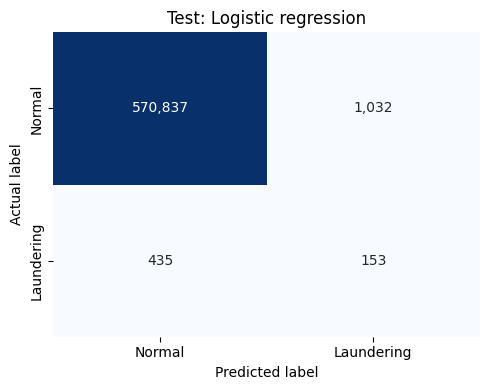

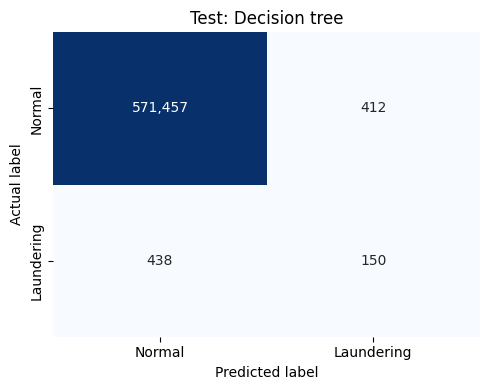

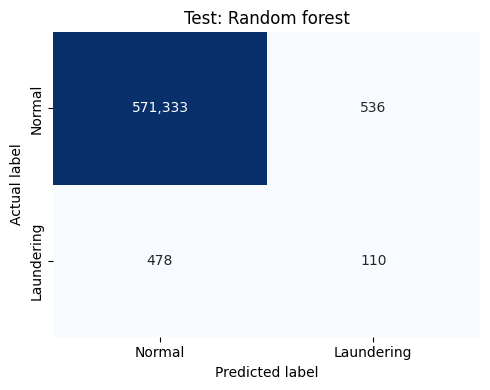

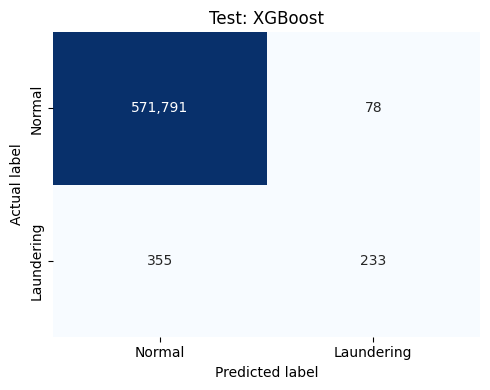

In [21]:
for name, row in test_results.iterrows():
    matrix = np.array([[row["TN"], row["FP"]], [row["FN"], row["TP"]]], dtype=int)
    plt.figure(figsize=(5, 4))
    sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=["Normal", "Laundering"], yticklabels=["Normal", "Laundering"])
    plt.title(f"Test: {name}")
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.tight_layout()
    plt.show()

On test data, XGBoost detects 233 of 588 laundering transactions and misses 355. Its 311 alerts include 78 false alerts. Precision is 74.92%, recall is 39.63%, PR AUC is 0.4923 and F1 is 0.5184.

The data is synthetic, and the random split can share accounts and banks across partitions. Results describe new records with partial training history, not future periods or unseen customers. The limited number of positives and repeated selection on one validation partition can make validation performance optimistic.

In [23]:
training.unpersist()
validation.unpersist()
for scores in list(validation_scores.values()) + list(test_scores.values()) + list(ablation_scores.values()):
    scores.unpersist()
for curve in validation_curves.values():
    curve.unpersist()

### A6. Save and reload the selected pipeline

Save the fitted preprocessing and selected XGBoost model together. The pipeline takes the 34 prepared inputs. Use the saved threshold when converting scores into predictions.

In [1]:
import json

final_pipeline = PipelineModel(
    stages=selected_preprocessing_model.stages + [selected_model]
)
final_pipeline.write().overwrite().save(str(MODEL_PATH))

model_settings = {
    "model": selected_name,
    "threshold": float(selected_threshold),
    "feature_columns": selected_feature_columns,
    "training_history": "data/training_history.parquet",
    "history_rule": "Strictly earlier training transactions; exclude timestamp ties",
    "timezone": "UTC",
}
settings_path = MODEL_PATH.parent / "a2_settings.json"
settings_path.write_text(json.dumps(model_settings, indent=2) + "\n")
print("Saved model:", MODEL_PATH.relative_to(PROJECT_ROOT))
print("Threshold:", model_settings["threshold"])

Saved model: models/a2_model
Threshold: 0.2882150709629059


#### Keep the training history
Save the training transactions without labels. Part B will use this fixed reference to calculate the same account features, using only transactions earlier than each incoming record.

In [2]:
training_history = development_df.filter(
    F.col("model_partition") == "train"
).drop("is_laundering", "data_partition", "transaction_group_id")
training_history.write.mode("overwrite").parquet(
    str(PROJECT_ROOT / model_settings["training_history"])
)
print(f"Saved {training_history.count():,} training transactions")

Saved 2,664,035 training transactions


#### Keep a sample for the reload check
Take 100 predicted positives and 100 predicted negatives from the existing test scores. Save their prepared inputs without labels and keep the A5 scores for comparison.

In [3]:
sample_scores = test_scores[selected_name]
positive_ids = sample_scores.filter(
    F.col("score") >= selected_threshold
).orderBy("source_record_id").limit(100).select("source_record_id")
negative_ids = sample_scores.filter(
    F.col("score") < selected_threshold
).orderBy("source_record_id").limit(100).select("source_record_id")
sample_ids = positive_ids.unionByName(negative_ids)

reload_input = model_test_df.join(sample_ids, "source_record_id").drop("is_laundering")
reload_input.write.mode("overwrite").parquet(str(DATA_DIR / "model_reload_input.parquet"))
expected_predictions = sample_scores.join(sample_ids, "source_record_id").select(
    "source_record_id", "score",
    (F.col("score") >= selected_threshold).cast("int").alias("prediction")
)
expected_predictions.write.mode("overwrite").parquet(
    str(DATA_DIR / "model_reload_expected.parquet")
)

#### Reload and predict
After the notebook setup, these cells can run in a fresh session. The prediction function applies the saved threshold of 0.288215 instead of the classifier default of 0.5.

In [1]:
import json
from pyspark.ml import PipelineModel
from pyspark.ml.functions import vector_to_array

def predict_transactions(data, model, threshold):
    predictions = model.transform(data)
    return predictions.withColumn(
        "score", vector_to_array("probability")[1]
    ).withColumn("prediction", (F.col("score") >= threshold).cast("int"))

loaded_model = PipelineModel.load(str(MODEL_PATH))
model_settings = json.loads((MODEL_PATH.parent / "a2_settings.json").read_text())
loaded_history = spark.read.parquet(str(PROJECT_ROOT / model_settings["training_history"]))
reload_input = spark.read.parquet(str(DATA_DIR / "model_reload_input.parquet"))
reloaded_predictions = predict_transactions(
    reload_input, loaded_model, model_settings["threshold"]
).select("source_record_id", "score", "prediction").cache()
reloaded_predictions.orderBy("source_record_id").show(10, truncate=False)

+----------------+---------------------+----------+
|source_record_id|score                |prediction|
+----------------+---------------------+----------+
|4               |1.2778136806446128E-5|0         |
|9               |3.6997021197748836E-6|0         |
|10              |1.8789929526974447E-5|0         |
|18              |2.4391124497924466E-6|0         |
|19              |2.098572394970688E-6 |0         |
|24              |1.1052668469346827E-6|0         |
|40              |1.0416243640065659E-5|0         |
|42              |7.544164191131131E-7 |0         |
|57              |3.159666221108637E-6 |0         |
|73              |1.182329942821525E-4 |0         |
+----------------+---------------------+----------+
only showing top 10 rows



2026-10-10 22:43:30,407 INFO XGBoost-PySpark: predict_udf Do the inference on the CPUs


In [2]:
import pandas as pd
from IPython.display import display

expected_predictions = spark.read.parquet(str(DATA_DIR / "model_reload_expected.parquet"))
reload_checks = [
    ("Rows scored", reloaded_predictions.count()),
    ("Predicted laundering", reloaded_predictions.filter("prediction = 1").count()),
    ("Column names and types match", expected_predictions.dtypes == reloaded_predictions.dtypes),
    ("Rows missing or changed", expected_predictions.exceptAll(reloaded_predictions).count()),
    ("Rows extra or changed", reloaded_predictions.exceptAll(expected_predictions).count()),
]
reloaded_predictions.unpersist()
display(pd.DataFrame(reload_checks, columns=["Check", "Result"]))

,Check,Result
0,Rows scored,200
1,Predicted laundering,100
2,Column names and types match,True
3,Rows missing or changed,0
4,Rows extra or changed,0


All 200 sample scores and predictions match after loading in a fresh session. The sample contains 100 predicted positives and 100 predicted negatives, with no true labels supplied to the model.

## Part B: Real time streaming
### B1. Kafka producer and message schema

`producer.py` reads the reserved Parquet files in batches of up to 1,000 records. Each Kafka message contains one JSON array. The producer pauses for five seconds between batches and logs the record count, publication time and Kafka offset after delivery is acknowledged.

The original `timestamp` is kept for account history. `event_timestamp` records publication time in UTC and will drive the streaming windows. Labels and split columns are excluded. Each run starts the replay again; `source_record_id` identifies repeated transactions.

#### Message fields
The producer sends both timestamps as ISO 8601 strings. B2 will convert them to Spark timestamps.

| Fields | JSON type | Spark type |
|---|---|---|
| source_record_id, from_bank, to_bank | Integer | Long |
| amount_paid, amount_received | Number | Double |
| sender_account, receiver_account | String | String |
| payment_currency, receiving_currency, payment_format | String | String |
| timestamp, event_timestamp | String | String before conversion |

In [1]:
from pyspark.sql.types import (
    ArrayType, StructType, StructField, StringType, LongType, DoubleType
)

message_schema = ArrayType(StructType([
    StructField("source_record_id", LongType()),
    StructField("timestamp", StringType()),
    StructField("from_bank", LongType()),
    StructField("sender_account", StringType()),
    StructField("to_bank", LongType()),
    StructField("receiver_account", StringType()),
    StructField("amount_received", DoubleType()),
    StructField("receiving_currency", StringType()),
    StructField("amount_paid", DoubleType()),
    StructField("payment_currency", StringType()),
    StructField("payment_format", StringType()),
    StructField("event_timestamp", StringType()),
]))

#### Check three batches
Start Kafka with `bash scripts/start_kafka.sh`. This check sends three batches to a separate test topic, then reads them back. The topic is removed after the comparison.

In [2]:
import json
import subprocess
import pandas as pd
from IPython.display import display
from uuid import uuid4
from kafka3 import KafkaConsumer
from kafka3.admin import KafkaAdminClient

test_topic = "aml-producer-check-" + uuid4().hex[:8]
producer_result = subprocess.run([
    sys.executable, str(PROJECT_ROOT / "producer.py"),
    "--batch-size", "1000", "--max-batches", "3",
    "--topic", test_topic, "--bootstrap-servers", KAFKA_BOOTSTRAP_SERVERS,
], cwd=PROJECT_ROOT, capture_output=True, text=True, check=True, timeout=90)
print(producer_result.stdout)

Batch 1: records=1000 timestamp=2026-10-10T11:56:01.998+00:00 partition=0 offset=0
Batch 2: records=1000 timestamp=2026-10-10T11:56:07.030+00:00 partition=0 offset=1
Batch 3: records=1000 timestamp=2026-10-10T11:56:12.085+00:00 partition=0 offset=2
Sent 3,000 records in 3 batches to aml-producer-check-6cdb6c60.



In [3]:
consumer = KafkaConsumer(
    test_topic, bootstrap_servers=KAFKA_BOOTSTRAP_SERVERS,
    auto_offset_reset="earliest", enable_auto_commit=False,
    consumer_timeout_ms=10000,
    value_deserializer=lambda value: json.loads(value.decode("utf-8")),
)
try:
    messages = list(consumer)
finally:
    consumer.close()

batch_summary = pd.DataFrame([
    {"Batch": number, "Records": len(message.value),
     "Published at": message.value[0]["event_timestamp"], "Offset": message.offset}
    for number, message in enumerate(messages, start=1)
])
batch_summary["Gap (seconds)"] = pd.to_datetime(
    batch_summary["Published at"], utc=True
).diff().dt.total_seconds()
display(batch_summary)

,Batch,Records,Published at,Offset,Gap (seconds)
0,1,1000,2026-10-10T11:56:01.998+00:00,0,NaN
1,2,1000,2026-10-10T11:56:07.030+00:00,1,5.032
2,3,1000,2026-10-10T11:56:12.085+00:00,2,5.055


In [4]:
received_records = [record for message in messages for record in message.value]
expected_fields = set(message_schema.elementType.fieldNames())
received_df = spark.createDataFrame(received_records, message_schema.elementType)
received_df = received_df.withColumn("timestamp", F.to_timestamp("timestamp"))
received_df = received_df.withColumn("event_timestamp", F.to_timestamp("event_timestamp"))

source_columns = [field for field in message_schema.elementType.fieldNames() if field != "event_timestamp"]
source_sample = spark.read.parquet(str(STREAM_PATH)).join(
    received_df.select("source_record_id").distinct(), "source_record_id"
).select(*source_columns)
received_sample = received_df.select(*source_columns)
producer_checks = [
    ("Batches received", len(messages)),
    ("Records received", received_df.count()),
    ("Unique record IDs", received_df.select("source_record_id").distinct().count()),
    ("Fields match the schema", all(set(record) == expected_fields for record in received_records)),
    ("Column types match the source", received_sample.dtypes == source_sample.dtypes),
    ("Invalid timestamps", received_df.filter("timestamp IS NULL OR event_timestamp IS NULL").count()),
    ("Received rows missing or changed", source_sample.exceptAll(received_sample).count()),
    ("Unexpected or changed rows", received_sample.exceptAll(source_sample).count()),
]
display(pd.DataFrame(producer_checks, columns=["Check", "Result"]))

,Check,Result
0,Batches received,3
1,Records received,3000
2,Unique record IDs,3000
3,Fields match the schema,True
4,Column types match the source,True
5,Invalid timestamps,0
6,Received rows missing or changed,0
7,Unexpected or changed rows,0


All 3,000 received records matched the saved source, with no missing, changed or unexpected rows. Publication gaps were 5.032 and 5.055 seconds, including the five-second pause and processing time.

In [5]:
admin = KafkaAdminClient(bootstrap_servers=KAFKA_BOOTSTRAP_SERVERS)
try:
    admin.delete_topics([test_topic])
finally:
    admin.close()

#### Run the producer
For a short run on the main topic:

```bash
.venv/bin/python producer.py --batch-size 1000 --max-batches 3
```

Omit `--max-batches` to replay the entire reserved subset. Start the B2 consumer before publishing to the main topic.

### B2. Read, parse and predict

### B3. Sliding windows, watermark and outputs

### B4. Run the complete stream

### Reflection

### Stop Spark
Run this cell when finished. Start Spark again before continuing with more processing.

In [81]:
for query in spark.streams.active:
    query.stop()
spark.stop()
print("Spark session stopped.")

Spark session stopped.
